# Анализ климатических изменений в Дубае (2016–2026)

## 1. Цель исследования

Исследовать изменения климатических и погодных характеристик Дубая за десятилетний период с ноября 2016 года по октябрь 2026 года, выявить статистически значимые тенденции и рассмотреть их в контексте программ модификации погоды, реализуемых в Объединенных Арабских Эмиратах (ОАЭ).

Особое внимание уделяется динамике осадков, частоте дождливых дней и интенсивности дождей, а также возможному соответствию выявленных изменений целям программ искусственного увеличения количества осадков (*cloud seeding* — засев облаков).

### Исследовательский вопрос

**Какие статистически значимые изменения погодных характеристик наблюдались в Дубае за исследуемые десять лет и насколько выявленные тенденции согласуются с целями климатических инициатив ОАЭ?**

### Задачи исследования

1. Проверить качество, полноту и временной охват исторических погодных данных.
2. Рассчитать основные описательные статистики температуры, осадков, влажности и ветра.
3. Исследовать сезонные закономерности и межгодовые изменения погодных показателей.
4. Проанализировать динамику количества осадков, частоты дождливых дней и интенсивности дождей.
5. Выявить температурные аномалии, экстремально жаркие дни и периоды продолжительной жары.
6. Исследовать взаимосвязи между температурой, влажностью, осадками и ветром.
7. Проверить статистические гипотезы о наличии временных трендов и изменений погодных характеристик.
8. Сопоставить выявленные тенденции с доступной информацией о программах модификации погоды в ОАЭ.
9. Сформулировать выводы о наблюдаемых изменениях, их статистической значимости и возможных объяснениях.

### Исследовательские гипотезы

- **H1.** Средняя температура воздуха в Дубае демонстрирует положительный межгодовой тренд.
- **H2.** Годовое количество осадков и частота дождливых дней демонстрируют статистически значимые изменения во времени.
- **H3.** Частота экстремально жарких дней увеличивается в течение исследуемого периода.

**Дополнительный исследовательский вопрос:** наблюдаются ли изменения количества и интенсивности осадков, согласующиеся с целями программ модификации погоды ОАЭ?

### Ограничения исследования

Исторические погодные данные позволяют выявлять тенденции и статистические взаимосвязи, однако сами по себе не доказывают эффективность программ искусственного воздействия на погоду.

Для установления причинно-следственных связей необходимы дополнительные сведения о времени, месте и интенсивности операций по засеву облаков, а также учет естественной климатической изменчивости и других факторов.

Исторические данные Open-Meteo основаны на моделях реанализа и могут отличаться от непосредственных измерений метеостанций, особенно при оценке локальных экстремальных погодных явлений.

Кроме того, десятилетний период недостаточен для однозначных выводов о долгосрочном изменении климата. Полученные результаты интерпретируются как тенденции исследуемого периода.

### Период исследования и статус данных

**Период исследования:** 01.11.2016–31.10.2026 (10 полных 12-месячных периодов).

Для межгодовых сравнений используются исследовательские годы с 1 ноября по 31 октября следующего года. Это позволяет сравнивать периоды одинаковой продолжительности сезонного цикла.

**Текущий статус:** исторический набор данных для Дубая загружен за весь исследуемый период. 

Данные после 31.10.2026 не входят в основной десятилетний период исследования и рассматриваются отдельно в рамках оперативного обновления дашборда.

### Источники данных и инструменты

**Источник данных:** Open-Meteo Historical Weather API.

**Хранилище:** PostgreSQL, база данных `weather_analytics`, размещенная на VPS.

**Инструменты:** SQL (JupySQL), Python, Pandas, NumPy, SciPy, Matplotlib, Jupyter Notebook.

**Результат исследования:** аналитический Jupyter Notebook со статистическими расчетами, визуализациями, проверкой гипотез и выводами. Наиболее информативные показатели и визуализации используются в публичном дашборде Streamlit.

In [1]:
"""Импорт библиотек и настройка подключения к PostgreSQL."""

import os
import socket
import subprocess
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from dotenv import load_dotenv
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy.stats import kendalltau, pearsonr, spearmanr, theilslopes
from sqlalchemy import URL, create_engine

In [2]:
# Закрываем предыдущее подключение при повторном запуске ячейки.
# Сначала освобождаем соединения SQLAlchemy, затем завершаем SSH-процесс.
if 'engine' in globals():
    engine.dispose()

if 'ssh_process' in globals() and ssh_process.poll() is None:
    ssh_process.terminate()
    ssh_process.wait(timeout=5)

# Загружаем параметры подключения из .env в корневом каталоге проекта.
load_dotenv(Path.cwd().parent / '.env', override=True)


def get_free_port():
    """Определяет свободный локальный порт для SSH-туннеля."""
    with socket.socket() as sock:
        sock.bind(('127.0.0.1', 0))
        return sock.getsockname()[1]


# Выбираем свободный порт, чтобы избежать конфликтов с другими подключениями.
local_port = get_free_port()

# Создаем SSH-туннель между локальным Mac и PostgreSQL на VPS.
# Параметр -N отключает выполнение удаленных команд,
# а -L перенаправляет локальный порт на порт PostgreSQL сервера.
ssh_process = subprocess.Popen(
    [
        'ssh',
        '-i', os.getenv('REMOTE_SSH_KEY'),
        '-o', 'IdentitiesOnly=yes',
        '-o', 'BatchMode=yes',
        '-o', 'ExitOnForwardFailure=yes',
        '-o', 'StrictHostKeyChecking=yes',
        '-p', os.getenv('REMOTE_SSH_PORT'),
        '-N',
        '-L',
        f'127.0.0.1:{local_port}:'
        f'{os.getenv("REMOTE_DB_HOST")}:{os.getenv("REMOTE_DB_PORT")}',
        f'{os.getenv("REMOTE_SSH_USER")}@{os.getenv("REMOTE_SSH_HOST")}',
    ],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.PIPE,
)

# Ожидаем открытия локального порта SSH-туннеля.
# Выполняем до 30 попыток с интервалом 0,2 секунды.
# Если SSH-процесс завершился раньше, выводим сообщение об ошибке.
for _ in range(30):
    if ssh_process.poll() is not None:
        error = ssh_process.stderr.read().decode()
        raise RuntimeError(f'Ошибка SSH-подключения: {error}')

    try:
        with socket.create_connection(('127.0.0.1', local_port), timeout=1):
            break
    except OSError:
        time.sleep(0.2)
else:
    ssh_process.terminate()
    ssh_process.wait(timeout=5)
    raise TimeoutError('Не удалось открыть SSH-туннель.')

# Создаем SQLAlchemy Engine для подключения к PostgreSQL.
# Соединение проходит через локальный порт защищенного SSH-туннеля.
engine = create_engine(
    URL.create(
        drivername='postgresql+psycopg',
        username=os.getenv('REMOTE_DB_USER'),
        password=os.getenv('REMOTE_DB_PASSWORD'),
        host='127.0.0.1',
        port=local_port,
        database=os.getenv('REMOTE_DB_NAME'),
    )
)

# Проверяем реальное подключение к PostgreSQL SQL-запросом.
# При ошибке освобождаем ресурсы и закрываем SSH-туннель.
try:
    with engine.connect() as connection:
        connection.exec_driver_sql('SELECT 1')
except Exception:
    engine.dispose()
    ssh_process.terminate()
    ssh_process.wait(timeout=5)
    raise

print('SSH-туннель открыт, подключение к PostgreSQL проверено.')

SSH-туннель открыт, подключение к PostgreSQL проверено.


In [3]:
# Загружаем расширение JupySQL с настройками из pyproject.toml.
%load_ext sql

# Подключаем JupySQL к существующему SQLAlchemy Engine.
%sql engine

Loading configurations from /Users/marina/Simulative_projects/practice/weather-analytics/pyproject.toml.

Settings changed:

Config,value
feedback,False
displaycon,False
named_parameters,disabled
displaylimit,0


In [4]:
# Каталог для сохранения графиков исследования климата Дубая.
FIGURES_DIR = Path('../reports/figures/dubai')

# Создаём каталог при необходимости, включая родительские папки.
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

## 1. Проверка качества, полноты и временного охвата исторических погодных данных

Перед проведением статистического анализа необходимо оценить полноту, непрерывность и корректность исторических данных.

Проверим:

- временной охват дневных и почасовых данных;
- количество наблюдений и соответствие ожидаемому числу дат и часов;
- наличие пропущенных дат и временных интервалов;
- наличие дубликатов;
- полноту погодных показателей и наличие значений `NULL`;
- корректность диапазонов значений температуры, осадков, влажности и ветра;
- согласованность дневных и почасовых данных.

**Период исследования:** 01.11.2016–31.10.2026.

Исторические данные Дубая за указанный период загружены в PostgreSQL. На данном этапе необходимо проверить их фактическую полноту и качество, прежде чем использовать для статистических расчетов.

По результатам проверки будет сделан вывод о пригодности данных для дальнейшего анализа и выявлены возможные ограничения исследования.

In [5]:
%%sql

-- Смотрим, какие таблицы есть в базе данных.
SELECT
    table_name
FROM information_schema.tables
WHERE table_schema = 'public'
  AND table_type = 'BASE TABLE'
ORDER BY table_name;

table_name
alembic_version
cities
etl_runs
etl_state
forecast_daily
forecast_ecmwf_hourly
forecast_hourly
historical_daily
historical_hourly


In [6]:
%%sql

-- Получаем перечень столбцов для каждой таблицы.
SELECT
    table_name,
    STRING_AGG(column_name, ', ' ORDER BY ordinal_position) AS columns
FROM information_schema.columns
WHERE table_schema = 'public'
GROUP BY table_name
ORDER BY table_name;

table_name,columns
alembic_version,version_num
cities,"city_id, name, country, latitude, longitude, timezone, is_active"
etl_runs,"run_id, pipeline, started_at, finished_at, status, rows_loaded, error_message"
etl_state,"pipeline, city_id, last_loaded_at, last_loaded_date, updated_at"
forecast_daily,"city_id, forecast_date, fetched_at, forecast_run_id, weather_code, temperature_mean, temperature_min, temperature_max, apparent_temperature_mean, apparent_temperature_min, apparent_temperature_max, sunrise, sunset, daylight_duration, sunshine_duration, precipitation, rain_sum, showers_sum, snowfall_sum, precipitation_hours, precipitation_probability_max, precipitation_probability_mean, wind_speed_max, wind_gusts_max, wind_direction_dominant, shortwave_radiation_sum, uv_index_max, uv_index_clear_sky_max, et0_fao_evapotranspiration"
forecast_ecmwf_hourly,"city_id, forecast_time, fetched_at, forecast_run_id, precipitation_type, snowfall_water_equivalent, snow_depth_water_equivalent, cape, wet_bulb_temperature, lightning_density, convective_inhibition"
forecast_hourly,"city_id, forecast_time, fetched_at, forecast_run_id, temperature, humidity, dew_point, apparent_temperature, wet_bulb_temperature, precipitation_probability, precipitation, rain, showers, snowfall, snow_depth, weather_code, pressure_msl, surface_pressure, cloud_cover, cloud_cover_low, cloud_cover_mid, cloud_cover_high, visibility, evapotranspiration, et0_fao_evapotranspiration, vapour_pressure_deficit, wind_speed, wind_direction, wind_gusts, shortwave_radiation, direct_radiation, diffuse_radiation, uv_index, uv_index_clear_sky, sunshine_duration, cape, lifted_index, convective_inhibition, freezing_level_height, is_day"
historical_daily,"city_id, weather_date, weather_code, temperature_mean, temperature_min, temperature_max, apparent_temperature_mean, apparent_temperature_min, apparent_temperature_max, sunrise, sunset, daylight_duration, sunshine_duration, precipitation, rain_sum, snowfall_sum, precipitation_hours, wind_speed_max, wind_gusts_max, wind_direction_dominant, shortwave_radiation_sum, et0_fao_evapotranspiration, loaded_at"
historical_hourly,"city_id, weather_time, temperature, humidity, dew_point, apparent_temperature, wet_bulb_temperature, precipitation, rain, snowfall, snow_depth, weather_code, pressure_msl, surface_pressure, cloud_cover, cloud_cover_low, cloud_cover_mid, cloud_cover_high, wind_speed, wind_direction, wind_gusts, shortwave_radiation, direct_radiation, diffuse_radiation, sunshine_duration, et0_fao_evapotranspiration, vapour_pressure_deficit, is_day, loaded_at"


In [7]:
%%sql

-- Определяем id Дубая в базе данных.
SELECT
    city_id
FROM cities
WHERE name = 'Dubai';



city_id
85


In [8]:
%%sql

-- Проверяем фактические границы дневных и почасовых данных Дубая за исследуемый период.
SELECT
    'daily' AS data_type,
    MIN(weather_date) AS first_date,
    MAX(weather_date) AS last_date
FROM historical_daily
WHERE city_id = 85

UNION ALL

SELECT
    'hourly' AS data_type,
    MIN(weather_time)::date AS first_date,
    MAX(weather_time)::date AS last_date
FROM historical_hourly
WHERE city_id = 85;

data_type,first_date,last_date
daily,2016-11-01,2026-10-31
hourly,2016-10-31,2026-10-31


In [9]:
%%sql

-- Подсчитываем дневные и почасовые наблюдения Дубая
-- за исследуемый период с 01.11.2016 по 31.10.2026.
SELECT
    'daily' AS data_type,
    COUNT(*) AS observations
FROM historical_daily
WHERE city_id = 85
  AND weather_date >= '2016-11-01'
  AND weather_date < '2026-11-01'

UNION ALL

SELECT
    'hourly' AS data_type,
    COUNT(*) AS observations
FROM historical_hourly
WHERE city_id = 85
  AND weather_time >= TIMESTAMP '2016-11-01 00:00:00'
                      AT TIME ZONE 'Asia/Dubai'
  AND weather_time < TIMESTAMP '2026-11-01 00:00:00'
                     AT TIME ZONE 'Asia/Dubai';

data_type,observations
daily,3652
hourly,87648


In [10]:
%%sql

-- Сравниваем количество загруженных записей с количеством
-- календарных дней и часов за исследуемый период.
WITH expected AS (
    SELECT
        (
            SELECT COUNT(*)
            FROM generate_series(
                TIMESTAMP '2016-11-01 00:00:00',
                TIMESTAMP '2026-10-31 00:00:00',
                INTERVAL '1 day'
            )
        ) AS expected_days,
        (
            SELECT COUNT(*)
            FROM generate_series(
                TIMESTAMP '2016-11-01 00:00:00',
                TIMESTAMP '2026-11-01 00:00:00',
                INTERVAL '1 hour'
            )
        ) - 1 AS expected_hours
),
actual AS (
    SELECT
        (SELECT COUNT(*)
         FROM historical_daily
         WHERE city_id = 85
           AND weather_date >= '2016-11-01'
           AND weather_date < '2026-11-01') AS actual_days,
        (SELECT COUNT(*)
         FROM historical_hourly
         WHERE city_id = 85
            AND weather_time >= TIMESTAMP '2016-11-01 00:00:00'
                                AT TIME ZONE 'Asia/Dubai'
            AND weather_time < TIMESTAMP '2026-11-01 00:00:00'
                                AT TIME ZONE 'Asia/Dubai') AS actual_hours
)
SELECT
    'daily' AS data_type,
    expected_days AS expected_records,
    actual_days AS actual_records,
    expected_days - actual_days AS difference
FROM expected, actual

UNION ALL

SELECT
    'hourly',
    expected_hours,
    actual_hours,
    expected_hours - actual_hours
FROM expected, actual;

data_type,expected_records,actual_records,difference
daily,3652,3652,0
hourly,87648,87648,0


In [11]:
%%sql

-- Проверяем количество дат с дубликатами и лишних записей.
WITH duplicates AS (
    SELECT
        weather_date,
        COUNT(*) AS record_count
    FROM historical_daily
    WHERE city_id = 85
      AND weather_date >= '2016-11-01'
      AND weather_date < '2026-11-01'
    GROUP BY weather_date
    HAVING COUNT(*) > 1
)
SELECT
    COUNT(*) AS duplicate_dates,
    COALESCE(SUM(record_count - 1), 0) AS duplicate_records
FROM duplicates;

duplicate_dates,duplicate_records
0,0


In [12]:
%%sql

-- Проверяем пропуски во всех погодных показателях
-- дневных и почасовых исторических данных Дубая.
WITH data AS (
    SELECT
        'daily' AS data_type,
        TO_JSONB(d) - 'city_id' - 'weather_date' - 'loaded_at' AS values_json
    FROM historical_daily AS d
    WHERE city_id = 85
      AND weather_date >= '2016-11-01'
      AND weather_date < '2026-11-01'

    UNION ALL

    SELECT
        'hourly' AS data_type,
        TO_JSONB(h) - 'city_id' - 'weather_time' - 'loaded_at' AS values_json
    FROM historical_hourly AS h
    WHERE city_id = 85
      AND weather_time >= '2016-11-01'
      AND weather_time < '2026-11-01'
)
SELECT
    data_type,
    indicator,
    COUNT(*) FILTER (WHERE value = 'null'::jsonb) AS missing_count,
    ROUND(
        100.0 * COUNT(*) FILTER (WHERE value = 'null'::jsonb)
        / NULLIF(COUNT(*), 0),
        2
    ) AS missing_pct
FROM data
CROSS JOIN LATERAL JSONB_EACH(values_json) AS fields(indicator, value)
GROUP BY data_type, indicator
ORDER BY data_type, indicator;

data_type,indicator,missing_count,missing_pct
daily,apparent_temperature_max,0,0.00
daily,apparent_temperature_mean,0,0.00
daily,apparent_temperature_min,0,0.00
daily,daylight_duration,0,0.00
daily,et0_fao_evapotranspiration,0,0.00
daily,precipitation,0,0.00
daily,precipitation_hours,0,0.00
daily,rain_sum,0,0.00
daily,shortwave_radiation_sum,0,0.00
daily,snowfall_sum,0,0.00



### Проверка корректности погодных показателей

Помимо полноты данных и наличия пропусков, необходимо убедиться, что значения погодных показателей находятся в допустимых пределах и не противоречат друг другу.

Проверяем:

- **Температуру:** минимальная температура не должна превышать максимальную, а средняя должна находиться между ними.
- **Осадки:** количество осадков не может быть отрицательным, а продолжительность их выпадения за сутки должна находиться в пределах от 0 до 24 часов.
- **Ветер:** скорость ветра и порывов не может быть отрицательной, а направление должно находиться в диапазоне от 0 до 360°.
- **Влажность:** относительная влажность должна находиться в диапазоне от 0 до 100%.

Проверка выполняется с учетом структуры данных: для дневных наблюдений дополнительно оценивается согласованность температур, для почасовых — допустимость относительной влажности. Показатели осадков и ветра проверяются в обоих наборах данных.

Это позволяет выявить некорректные значения, которые могут повлиять на расчеты и результаты дальнейшего климатического анализа.

In [13]:
%%sql

-- Проверяем допустимость погодных показателей и согласованность температур.
WITH quality_checks AS (
    SELECT
        'daily' AS data_type,
        COUNT(*) AS total_records,
        COUNT(*) FILTER (
            WHERE temperature_min > temperature_max
               OR temperature_mean < temperature_min
               OR temperature_mean > temperature_max
        ) AS temperature_errors,
        COUNT(*) FILTER (
            WHERE precipitation < 0
               OR rain_sum < 0
               OR snowfall_sum < 0
               OR precipitation_hours < 0
               OR precipitation_hours > 24
        ) AS precipitation_errors,
        COUNT(*) FILTER (
            WHERE wind_speed_max < 0
               OR wind_gusts_max < 0
               OR wind_direction_dominant < 0
               OR wind_direction_dominant > 360
        ) AS wind_errors,
        NULL::bigint AS humidity_errors
    FROM historical_daily
    WHERE city_id = 85
      AND weather_date >= '2016-11-01'
      AND weather_date < '2026-11-01'

    UNION ALL

    SELECT
        'hourly' AS data_type,
        COUNT(*) AS total_records,
        NULL::bigint AS temperature_errors,
        COUNT(*) FILTER (
            WHERE precipitation < 0
               OR rain < 0
               OR snowfall < 0
        ) AS precipitation_errors,
        COUNT(*) FILTER (
            WHERE wind_speed < 0
               OR wind_gusts < 0
               OR wind_direction < 0
               OR wind_direction > 360
        ) AS wind_errors,
        COUNT(*) FILTER (
            WHERE humidity < 0
               OR humidity > 100
        ) AS humidity_errors
    FROM historical_hourly
    WHERE city_id = 85
        AND weather_time >= TIMESTAMP '2016-11-01 00:00:00'
                            AT TIME ZONE 'Asia/Dubai'
        AND weather_time < TIMESTAMP '2026-11-01 00:00:00'
                            AT TIME ZONE 'Asia/Dubai'
)
SELECT *
FROM quality_checks;

data_type,total_records,temperature_errors,precipitation_errors,wind_errors,humidity_errors
daily,3652,0,0,0,None
hourly,87648,None,0,0,0


### Проверка согласованности дневных и почасовых данных

Для проверки качества данных сравним готовые суточные показатели Open-Meteo с результатами самостоятельной агрегации почасовых наблюдений. Для каждого дня рассчитаем среднюю, минимальную и максимальную температуру, а также сумму осадков по 24 почасовым значениям.

Сопоставление позволит оценить величину расхождений между двумя наборами данных перед проведением климатического анализа.

In [14]:
%%sql daily_hourly_comparison <<

-- Сравниваем готовые суточные показатели с рассчитанными
-- из почасовых наблюдений за каждый день.
WITH hourly_aggregated AS (
    SELECT
        (weather_time AT TIME ZONE 'Asia/Dubai')::date AS weather_date,
        AVG(temperature) AS hourly_temperature_mean,
        MIN(temperature) AS hourly_temperature_min,
        MAX(temperature) AS hourly_temperature_max,
        SUM(precipitation) AS hourly_precipitation,
        COUNT(*) AS hourly_records
    FROM historical_hourly
    WHERE city_id = 85
      AND weather_time >= TIMESTAMP '2016-11-01 00:00:00'
                          AT TIME ZONE 'Asia/Dubai'
      AND weather_time < TIMESTAMP '2026-11-01 00:00:00'
                         AT TIME ZONE 'Asia/Dubai'
    GROUP BY (weather_time AT TIME ZONE 'Asia/Dubai')::date
)
SELECT
    d.weather_date,
    h.hourly_records,
    d.temperature_mean AS daily_temperature_mean,
    ROUND(h.hourly_temperature_mean::numeric, 2) AS hourly_temperature_mean,
    ROUND(
        (d.temperature_mean - h.hourly_temperature_mean)::numeric,
        2
    ) AS temperature_mean_diff,
    d.temperature_min AS daily_temperature_min,
    h.hourly_temperature_min,
    ROUND(
        (d.temperature_min - h.hourly_temperature_min)::numeric,
        2
    ) AS temperature_min_diff,
    d.temperature_max AS daily_temperature_max,
    h.hourly_temperature_max,
    ROUND(
        (d.temperature_max - h.hourly_temperature_max)::numeric,
        2
    ) AS temperature_max_diff,
    d.precipitation AS daily_precipitation,
    ROUND(h.hourly_precipitation::numeric, 2) AS hourly_precipitation,
    ROUND(
        (d.precipitation - h.hourly_precipitation)::numeric,
        2
    ) AS precipitation_diff
FROM historical_daily AS d
INNER JOIN hourly_aggregated AS h
    ON d.weather_date = h.weather_date
WHERE d.city_id = 85
  AND d.weather_date BETWEEN '2016-11-01' AND '2026-10-31'
ORDER BY d.weather_date;

In [15]:
# Преобразуем результат SQL-запроса в DataFrame.
df_comparison = daily_hourly_comparison.DataFrame()

# Определяем показатели, для которых оцениваем расхождения.
indicators = {
    'Средняя температура, °C': 'temperature_mean_diff',
    'Минимальная температура, °C': 'temperature_min_diff',
    'Максимальная температура, °C': 'temperature_max_diff',
    'Сумма осадков, мм': 'precipitation_diff',
}

# Приводим значения к числовому типу.
columns = list(indicators.values())

df_comparison[columns] = df_comparison[columns].apply(
    pd.to_numeric,
    errors='coerce',
)

# Рассчитываем средние и максимальные абсолютные расхождения.
summary = pd.DataFrame([
    {
        'Показатель': name,
        'Среднее расхождение': df_comparison[col].abs().mean(),
        'Максимальное расхождение': df_comparison[col].abs().max(),
        'Дней без расхождений': df_comparison[col].eq(0).sum(),
    }
    for name, col in indicators.items()
])

# Выводим сводную таблицу.
display(
    summary.style.format({
        'Среднее расхождение': '{:.3f}',
        'Максимальное расхождение': '{:.3f}',
        'Дней без расхождений': '{:,.0f}',
    })
)

,Показатель,Среднее расхождение,Максимальное расхождение,Дней без расхождений
0,"Средняя температура, °C",0.031,0.090,445
1,"Минимальная температура, °C",0.103,1.800,"1,186"
2,"Максимальная температура, °C",0.023,0.500,"2,981"
3,"Сумма осадков, мм",0.000,0.000,"3,652"


**Вывод.** Проверка подтвердила полноту исторических данных Дубая за период с 1 ноября 2016 года по 31 октября 2026 года: 3652 дневных и 87 648 почасовых наблюдений.

Сопоставление дневных показателей с результатами агрегации почасовых данных показало высокую согласованность средней и максимальной температуры: средние абсолютные расхождения составили 0,031 °C и 0,023 °C соответственно. Для минимальной температуры среднее расхождение составило 0,103 °C, максимальное — 1,8 °C. Суточные суммы осадков совпали во все 3652 дня.

В целом результаты подтверждают согласованность двух наборов данных по большинству проверенных показателей. Наиболее заметные расхождения выявлены для минимальной температуры.

## 2. Описательная статистика погодных показателей

Рассчитаем основные описательные статистики температуры воздуха, количества осадков, относительной влажности и скорости ветра в Дубае за период с 1 ноября 2016 года по 31 октября 2026 года.

Для каждого показателя определим количество наблюдений, среднее значение, медиану, стандартное отклонение, минимум, максимум и квартили.

In [16]:
%%sql descriptive_statistics <<

-- Собираем четыре погодных показателя для расчета описательной статистики.
-- Температуру, осадки и ветер берем из дневных данных, влажность — из почасовых.
WITH weather_metrics AS (
    SELECT
        'Среднесуточная температура, °C' AS metric,
        temperature_mean AS value
    FROM historical_daily
    WHERE city_id = 85
      AND weather_date BETWEEN '2016-11-01' AND '2026-10-31'

    UNION ALL

    SELECT
        'Суточные осадки, мм',
        precipitation
    FROM historical_daily
    WHERE city_id = 85
      AND weather_date BETWEEN '2016-11-01' AND '2026-10-31'

    UNION ALL

    SELECT
        'Максимальная суточная скорость ветра, км/ч',
        wind_speed_max
    FROM historical_daily
    WHERE city_id = 85
      AND weather_date BETWEEN '2016-11-01' AND '2026-10-31'

    UNION ALL

    SELECT
        'Относительная влажность, %%',
        humidity
    FROM historical_hourly
    WHERE city_id = 85
      AND weather_time >= TIMESTAMP '2016-11-01 00:00:00'
                          AT TIME ZONE 'Asia/Dubai'
      AND weather_time < TIMESTAMP '2026-11-01 00:00:00'
                         AT TIME ZONE 'Asia/Dubai'
)
-- Считаем основные статистики для каждого показателя за весь период.
SELECT
    metric,
    COUNT(value) AS observations,
    ROUND(AVG(value)::numeric, 2) AS mean,
    ROUND(
        PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY value)::numeric,
        2
    ) AS median,
    ROUND(STDDEV_SAMP(value)::numeric, 2) AS std_dev,
    ROUND(MIN(value)::numeric, 2) AS minimum,
    ROUND(
        PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY value)::numeric,
        2
    ) AS q25,
    ROUND(
        PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY value)::numeric,
        2
    ) AS q75,
    ROUND(MAX(value)::numeric, 2) AS maximum
FROM weather_metrics
GROUP BY metric
ORDER BY metric;

In [17]:
descriptive_statistics

metric,observations,mean,median,std_dev,minimum,q25,q75,maximum
"Максимальная суточная скорость ветра, км/ч",3652,22.07,21.80,5.73,8.60,17.80,25.50,55.40
"Относительная влажность, %",87648,59.28,60.00,19.42,4.00,46.00,74.00,100.00
"Среднесуточная температура, °C",3652,28.08,28.70,5.73,15.30,22.80,33.20,39.50
"Суточные осадки, мм",3652,0.31,0.00,3.59,0.00,0.00,0.00,113.00


In [18]:
%%sql weather_distributions <<

-- Собираем значения температуры, осадков, ветра и влажности
-- за весь исследуемый период для анализа их распределений.
WITH weather_metrics AS (
    SELECT
        'Температура' AS metric,
        temperature_mean AS value
    FROM historical_daily
    WHERE city_id = 85
      AND weather_date BETWEEN '2016-11-01' AND '2026-10-31'

    UNION ALL

    SELECT
        'Осадки',
        precipitation
    FROM historical_daily
    WHERE city_id = 85
      AND weather_date BETWEEN '2016-11-01' AND '2026-10-31'

    UNION ALL

    SELECT
        'Ветер',
        wind_speed_max
    FROM historical_daily
    WHERE city_id = 85
      AND weather_date BETWEEN '2016-11-01' AND '2026-10-31'

    UNION ALL

    SELECT
        'Влажность',
        humidity
    FROM historical_hourly
    WHERE city_id = 85
      AND weather_time >= TIMESTAMP '2016-11-01 00:00:00'
                          AT TIME ZONE 'Asia/Dubai'
      AND weather_time < TIMESTAMP '2026-11-01 00:00:00'
                         AT TIME ZONE 'Asia/Dubai'
)
SELECT
    metric,
    value
FROM weather_metrics;

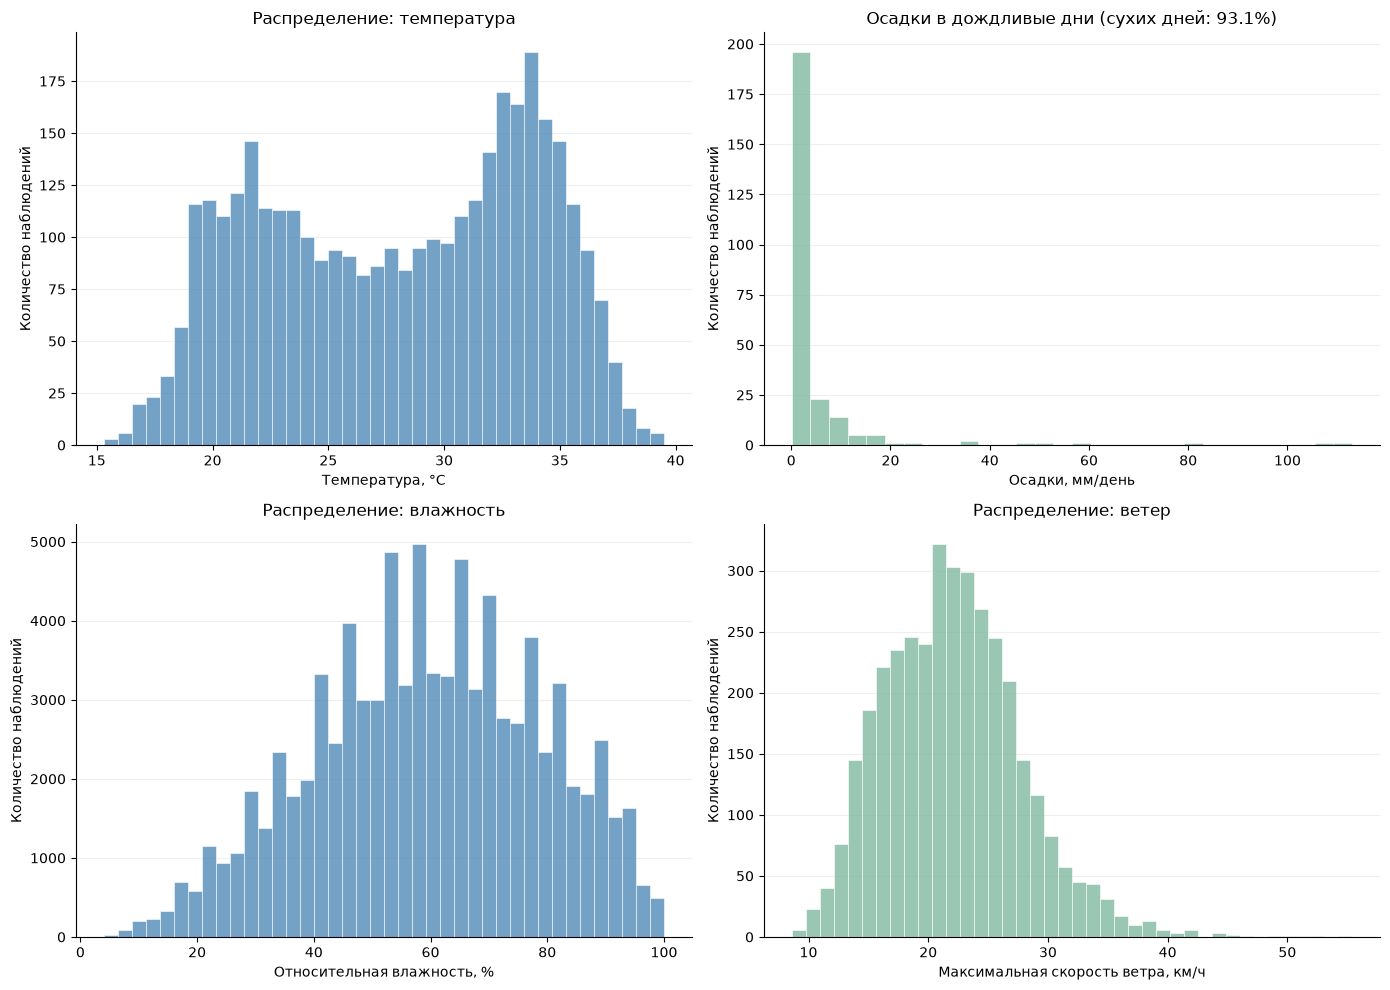

In [19]:
# Преобразуем результаты SQL-запроса в DataFrame.
df_distributions = weather_distributions.DataFrame()

df_distributions['value'] = pd.to_numeric(
    df_distributions['value'],
    errors='coerce',
)

# Определяем показатели, подписи осей и цвета.
metrics = [
    ('Температура', 'Температура, °C', '#4682B4'),
    ('Осадки', 'Осадки, мм/день', '#79B59B'),
    ('Влажность', 'Относительная влажность, %', '#4682B4'),
    ('Ветер', 'Максимальная скорость ветра, км/ч', '#79B59B'),
]

# Строим распределения погодных показателей.
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, (metric, xlabel, color) in zip(axes.flat, metrics):
    values = df_distributions.loc[
        df_distributions['metric'] == metric,
        'value',
    ].dropna()

    title = f'Распределение: {metric.lower()}'
    bins = 40

    if metric == 'Осадки':
        # Отдельно рассматриваем дни с осадками,
        # чтобы нулевые значения не скрывали распределение.
        dry_days_pct = (values == 0).mean() * 100
        values = values[values > 0]

        title = f'Осадки в дождливые дни (сухих дней: {dry_days_pct:.1f}%)'
        bins = 30

    sns.histplot(
        values,
        bins=bins,
        color=color,
        edgecolor='white',
        linewidth=0.4,
        ax=ax,
    )

    ax.set(
        title=title,
        xlabel=xlabel,
        ylabel='Количество наблюдений',
    )

    ax.grid(axis='y', alpha=0.2)
    ax.set_axisbelow(True)

    sns.despine(ax=ax)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / 'dubai_weather_distributions.png',
    dpi=300,
    bbox_inches='tight',
)

plt.show()

### Частота и интенсивность осадков

Поскольку в Дубае преобладают дни без осадков, среднее значение за весь период не отражает особенности дождливых дней. Поэтому отдельно рассчитаем их количество и долю, общую сумму осадков за десять лет, а также среднее, медианное и максимальное количество осадков за дождливый день.

Дождливым считаем день, в который зарегистрировано более 0 мм осадков.

In [20]:
%%sql rainy_days_statistics <<

-- Считаем, как часто в Дубае шли дожди и сколько осадков выпадало
-- за дождливый день. Отдельно определяем общую сумму за 10 лет.
SELECT
    COUNT(*) AS observed_days,
    COUNT(*) FILTER (
        WHERE precipitation > 0
    ) AS rainy_days,
    COUNT(*) FILTER (
        WHERE precipitation = 0
    ) AS dry_days,
    ROUND(
        100.0 * COUNT(*) FILTER (WHERE precipitation > 0)
        / NULLIF(COUNT(precipitation), 0),
        2
    ) AS rainy_days_pct,
    ROUND(SUM(precipitation)::numeric, 2) AS total_precipitation,
    ROUND(
        AVG(precipitation) FILTER (
            WHERE precipitation > 0
        )::numeric,
        2
    ) AS mean_rainy_day_precipitation,
    ROUND(
        PERCENTILE_CONT(0.5) WITHIN GROUP (
            ORDER BY precipitation
        ) FILTER (
            WHERE precipitation > 0
        )::numeric,
        2
    ) AS median_rainy_day_precipitation,
    MAX(precipitation) AS max_daily_precipitation
FROM historical_daily
WHERE city_id = 85
  AND weather_date BETWEEN '2016-11-01' AND '2026-10-31';

In [21]:
rainy_days_statistics.DataFrame().T.rename(columns={0: 'Значение'})

,Значение
observed_days,3652
rainy_days,253
dry_days,3399
rainy_days_pct,6.93
total_precipitation,1135.50
mean_rainy_day_precipitation,4.49
median_rainy_day_precipitation,0.70
max_daily_precipitation,113.0


### Вывод

За исследуемый период среднесуточная температура воздуха в Дубае составила 28,08 °C, а средняя максимальная суточная скорость ветра — 22,07 км/ч. Средняя относительная влажность достигала 59,28%.

Осадки выпадали редко: за десять лет зарегистрировано 253 дождливых дня (6,93% от общего числа). При этом половина дождливых дней характеризовалась количеством осадков не более 0,7 мм. Среднее значение составило 4,49 мм, а максимальное суточное количество осадков достигло 113 мм.

Таким образом, для Дубая характерны высокая температура воздуха, редкие осадки и значительная неравномерность их распределения. Особенно заметна разница между типичными дождливыми днями с небольшим количеством осадков и отдельными днями с интенсивными осадками.

## 3. Сезонные закономерности и межгодовые изменения

Рассмотрим, как меняются температура воздуха, количество осадков, относительная влажность и скорость ветра в Дубае в течение года, а также проследим их изменения за исследуемый период.

Для анализа сезонности рассчитаем средние показатели по календарным месяцам за десять лет. Межгодовую динамику рассмотрим отдельно, учитывая, что 2016 и 2026 годы представлены неполностью.

### Сезонная динамика температуры

Чтобы определить сезонные особенности температуры воздуха в Дубае, рассчитаем средние значения среднесуточной температуры, суточных минимумов и максимумов для каждого календарного месяца за десять лет. Это позволит сравнить температурные условия в разные месяцы года и выделить наиболее жаркие и прохладные периоды.

In [22]:
%%sql monthly_temperature <<

-- Рассчитываем среднемесячную температуру за исследуемый период.
SELECT
    EXTRACT(MONTH FROM weather_date)::int AS month,
    ROUND(AVG(temperature_mean)::numeric, 2) AS temperature_mean,
    ROUND(AVG(temperature_min)::numeric, 2) AS temperature_min,
    ROUND(AVG(temperature_max)::numeric, 2) AS temperature_max,
    COUNT(temperature_mean) AS observations
FROM historical_daily
WHERE city_id = 85
  AND weather_date BETWEEN '2016-11-01' AND '2026-10-31'
GROUP BY EXTRACT(MONTH FROM weather_date)
ORDER BY month;

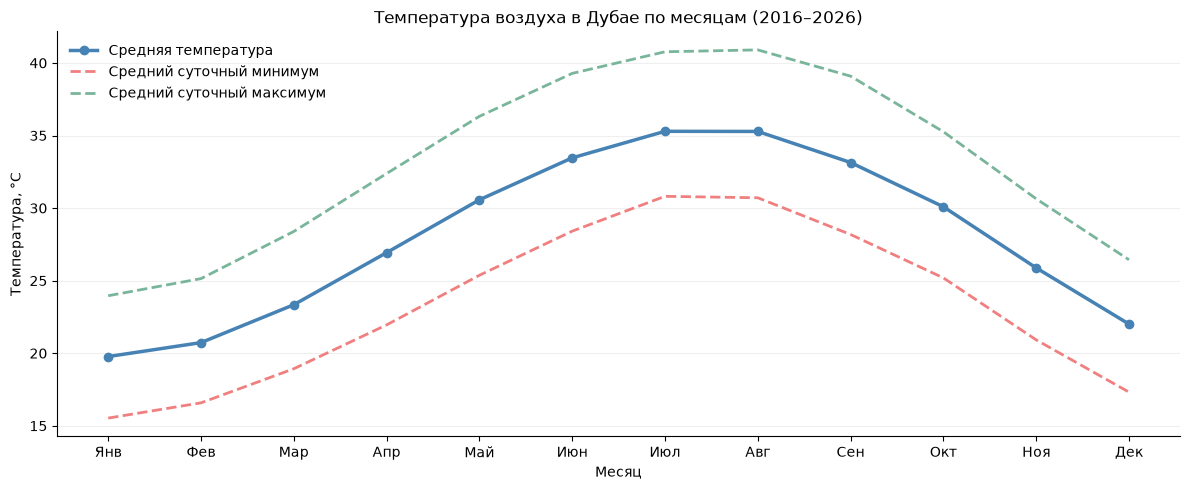

In [23]:
# Преобразуем результаты SQL-запроса в DataFrame.
df_monthly_temp = monthly_temperature.DataFrame()

# Приводим температурные показатели к числовому типу.
temperature_columns = [
    'temperature_mean',
    'temperature_min',
    'temperature_max',
]

df_monthly_temp[temperature_columns] = df_monthly_temp[
    temperature_columns
].apply(pd.to_numeric, errors='coerce')

# Названия месяцев для оси X.
month_labels = [
    'Янв', 'Фев', 'Мар', 'Апр', 'Май', 'Июн',
    'Июл', 'Авг', 'Сен', 'Окт', 'Ноя', 'Дек',
]

# Показываем, как меняется температура в течение года.
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    df_monthly_temp['month'],
    df_monthly_temp['temperature_mean'],
    color='#4682B4',
    linewidth=2.5,
    marker='o',
    markersize=6,
    label='Средняя температура',
)

ax.plot(
    df_monthly_temp['month'],
    df_monthly_temp['temperature_min'],
    color='#F08080',
    linewidth=2,
    linestyle='--',
    label='Средний суточный минимум',
)

ax.plot(
    df_monthly_temp['month'],
    df_monthly_temp['temperature_max'],
    color='#79B59B',
    linewidth=2,
    linestyle='--',
    label='Средний суточный максимум',
)

ax.set(
    title='Температура воздуха в Дубае по месяцам (2016–2026)',
    xlabel='Месяц',
    ylabel='Температура, °C',
    xticks=range(1, 13),
)

ax.set_xticklabels(month_labels)

ax.legend(frameon=False, loc='upper left')
ax.grid(axis='y', alpha=0.2)
ax.set_axisbelow(True)

sns.despine(ax=ax)

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / 'dubai_seasonal_temperature.png',
    dpi=300,
    bbox_inches='tight',
)
plt.show()

In [24]:
%%sql monthly_precipitation <<

-- Рассчитываем среднемесячные характеристики осадков.
WITH monthly_data AS (
    SELECT
        EXTRACT(YEAR FROM weather_date)::int AS year,
        EXTRACT(MONTH FROM weather_date)::int AS month,
        COUNT(*) AS observed_days,
        COUNT(*) FILTER (
            WHERE precipitation > 0
        ) AS rainy_days,
        SUM(precipitation) AS total_precipitation
    FROM historical_daily
    WHERE city_id = 85
      AND weather_date BETWEEN '2016-11-01' AND '2026-10-31'
    GROUP BY
        EXTRACT(YEAR FROM weather_date),
        EXTRACT(MONTH FROM weather_date)
)
SELECT
    month,
    ROUND(AVG(total_precipitation)::numeric, 2) AS mean_monthly_precipitation,
    ROUND(
        100.0 * SUM(rainy_days) / NULLIF(SUM(observed_days), 0),
        2
    ) AS rainy_days_pct,
    COUNT(*) AS observed_months
FROM monthly_data
GROUP BY month
ORDER BY month;

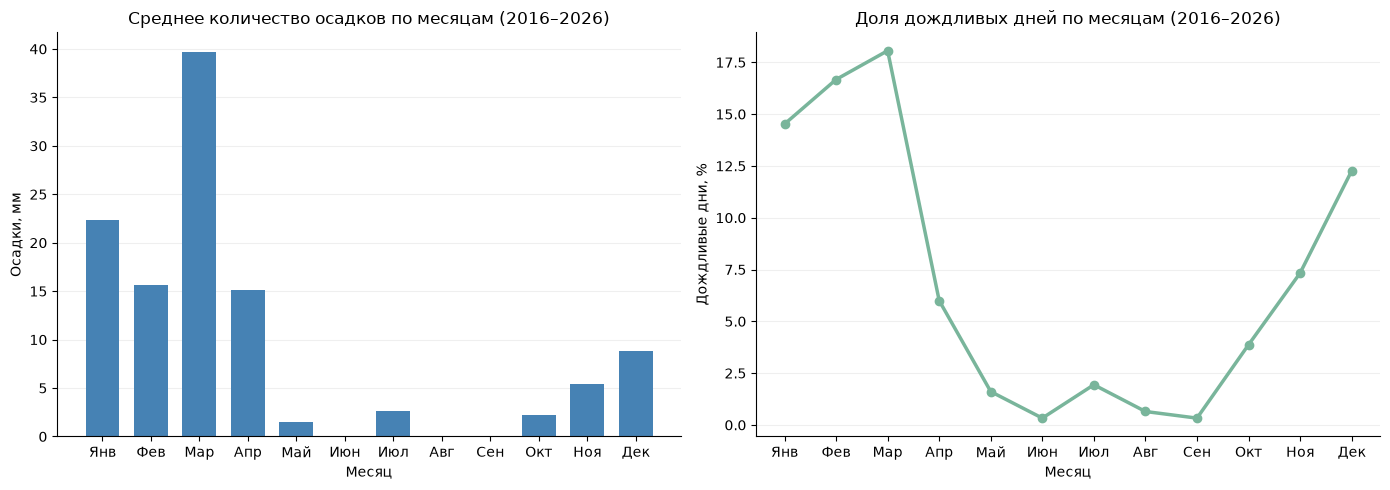

In [25]:
# Преобразуем результаты SQL-запроса в DataFrame.
df_monthly_precip = monthly_precipitation.DataFrame()

# Подготавливаем числовые показатели.
columns = [
    'mean_monthly_precipitation',
    'rainy_days_pct',
]

df_monthly_precip[columns] = df_monthly_precip[columns].apply(
    pd.to_numeric,
    errors='coerce',
)

# Подписи месяцев.
month_labels = [
    'Янв', 'Фев', 'Мар', 'Апр', 'Май', 'Июн',
    'Июл', 'Авг', 'Сен', 'Окт', 'Ноя', 'Дек',
]

# Сравниваем количество осадков и частоту дождливых дней по месяцам.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(
    df_monthly_precip['month'],
    df_monthly_precip['mean_monthly_precipitation'],
    color='#4682B4',
    width=0.7,
)

axes[0].set(
    title='Среднее количество осадков по месяцам (2016–2026)',
    xlabel='Месяц',
    ylabel='Осадки, мм',
    xticks=range(1, 13),
)
axes[0].set_xticklabels(month_labels)

axes[1].plot(
    df_monthly_precip['month'],
    df_monthly_precip['rainy_days_pct'],
    color='#79B59B',
    linewidth=2.5,
    marker='o',
    markersize=6,
)

axes[1].set(
    title='Доля дождливых дней по месяцам (2016–2026)',
    xlabel='Месяц',
    ylabel='Дождливые дни, %',
    xticks=range(1, 13),
)
axes[1].set_xticklabels(month_labels)

for ax in axes:
    ax.grid(axis='y', alpha=0.2)
    ax.set_axisbelow(True)
    sns.despine(ax=ax)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / 'dubai_seasonal_precipitation.png',
    dpi=300,
    bbox_inches='tight',
)

plt.show()

In [26]:
%%sql monthly_humidity_wind <<

-- Считаем среднюю влажность и среднюю максимальную скорость ветра
-- для каждого месяца года за весь период с 2016 по 2026 год.
WITH monthly_humidity AS (
    SELECT
        EXTRACT(
            MONTH FROM weather_time AT TIME ZONE 'Asia/Dubai'
        )::int AS month,
        AVG(humidity) AS humidity_mean,
        COUNT(humidity) AS humidity_observations
    FROM historical_hourly
    WHERE city_id = 85
      AND weather_time >= TIMESTAMP '2016-11-01 00:00:00'
                          AT TIME ZONE 'Asia/Dubai'
      AND weather_time < TIMESTAMP '2026-11-01 00:00:00'
                         AT TIME ZONE 'Asia/Dubai'
    GROUP BY
        EXTRACT(MONTH FROM weather_time AT TIME ZONE 'Asia/Dubai')
),

monthly_wind AS (
    SELECT
        EXTRACT(MONTH FROM weather_date)::int AS month,
        AVG(wind_speed_max) AS wind_speed_mean,
        COUNT(wind_speed_max) AS wind_observations
    FROM historical_daily
    WHERE city_id = 85
      AND weather_date BETWEEN '2016-11-01' AND '2026-10-31'
    GROUP BY EXTRACT(MONTH FROM weather_date)
)

SELECT
    h.month,
    ROUND(h.humidity_mean::numeric, 2) AS humidity_mean,
    ROUND(w.wind_speed_mean::numeric, 2) AS wind_speed_mean,
    h.humidity_observations,
    w.wind_observations
FROM monthly_humidity AS h
INNER JOIN monthly_wind AS w
    ON h.month = w.month
ORDER BY h.month;

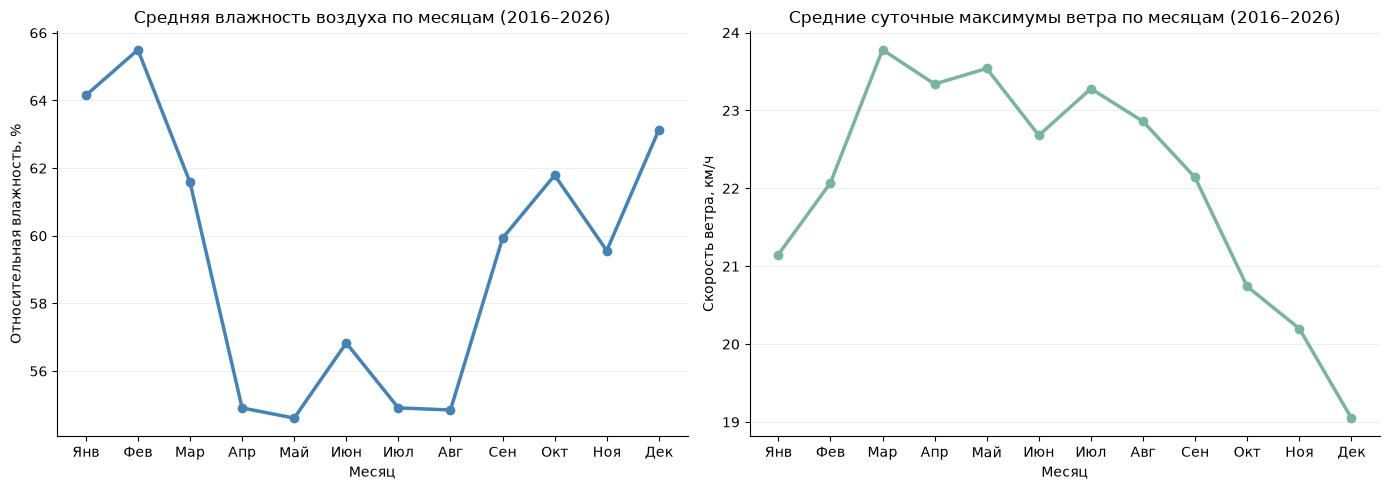

In [27]:
# Преобразуем результаты SQL-запроса в DataFrame.
df_humidity_wind = monthly_humidity_wind.DataFrame()

# Приводим показатели к числовому типу.
columns = ['humidity_mean', 'wind_speed_mean']

df_humidity_wind[columns] = df_humidity_wind[columns].apply(
    pd.to_numeric,
    errors='coerce',
)

# Названия месяцев.
month_labels = [
    'Янв', 'Фев', 'Мар', 'Апр', 'Май', 'Июн',
    'Июл', 'Авг', 'Сен', 'Окт', 'Ноя', 'Дек',
]

# Показываем, как меняются влажность и ветер в течение года.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    df_humidity_wind['month'],
    df_humidity_wind['humidity_mean'],
    color='#4682B4',
    linewidth=2.5,
    marker='o',
    markersize=6,
)

axes[0].set(
    title='Средняя влажность воздуха по месяцам (2016–2026)',
    xlabel='Месяц',
    ylabel='Относительная влажность, %',
    xticks=range(1, 13),
)

axes[1].plot(
    df_humidity_wind['month'],
    df_humidity_wind['wind_speed_mean'],
    color='#79B59B',
    linewidth=2.5,
    marker='o',
    markersize=6,
)

axes[1].set(
    title='Средние суточные максимумы ветра по месяцам (2016–2026)',
    xlabel='Месяц',
    ylabel='Скорость ветра, км/ч',
    xticks=range(1, 13),
)

for ax in axes:
    ax.set_xticklabels(month_labels)
    ax.grid(axis='y', alpha=0.2)
    ax.set_axisbelow(True)
    sns.despine(ax=ax)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / 'dubai_seasonal_humidity_wind.png',
    dpi=300,
    bbox_inches='tight',
)

plt.show()

### Изменения погодных показателей по годам

Посмотрим, как менялись температура, количество осадков, влажность и скорость ветра за десять лет.

Для сравнения используем десять полных 12-месячных периодов — с 1 ноября по 31 октября следующего года. Каждый период обозначим годом его окончания: например, 2017 год включает данные с 1 ноября 2016 года по 31 октября 2017 года.

Для каждого периода рассчитаем среднюю температуру и влажность, общую сумму осадков и среднее значение суточных максимумов скорости ветра.

In [28]:
%%sql yearly_weather <<

-- Сравниваем погодные показатели за десять полных периодов
-- с ноября по октябрь. Год обозначает окончание периода.
WITH yearly_daily AS (
    SELECT
        CASE
            WHEN EXTRACT(MONTH FROM weather_date) >= 11
                THEN EXTRACT(YEAR FROM weather_date)::int + 1
            ELSE EXTRACT(YEAR FROM weather_date)::int
        END AS year,
        COUNT(*) AS observed_days,
        ROUND(AVG(temperature_mean)::numeric, 2) AS temperature_mean,
        ROUND(SUM(precipitation)::numeric, 2) AS precipitation_total,
        ROUND(AVG(wind_speed_max)::numeric, 2) AS wind_speed_mean
    FROM historical_daily
    WHERE city_id = 85
      AND weather_date BETWEEN '2016-11-01' AND '2026-10-31'
    GROUP BY 1
),

-- Влажность считаем по тем же периодам, но из почасовых данных.
yearly_hourly AS (
    SELECT
        CASE
            WHEN EXTRACT(
                MONTH FROM weather_time AT TIME ZONE 'Asia/Dubai'
            ) >= 11
                THEN EXTRACT(
                    YEAR FROM weather_time AT TIME ZONE 'Asia/Dubai'
                )::int + 1
            ELSE EXTRACT(
                YEAR FROM weather_time AT TIME ZONE 'Asia/Dubai'
            )::int
        END AS year,
        COUNT(*) AS observed_hours,
        ROUND(AVG(humidity)::numeric, 2) AS humidity_mean
    FROM historical_hourly
    WHERE city_id = 85
      AND weather_time >= TIMESTAMP '2016-11-01 00:00:00'
                          AT TIME ZONE 'Asia/Dubai'
      AND weather_time < TIMESTAMP '2026-11-01 00:00:00'
                         AT TIME ZONE 'Asia/Dubai'
    GROUP BY 1
)

SELECT
    d.year,
    d.observed_days,
    h.observed_hours,
    d.temperature_mean,
    d.precipitation_total,
    h.humidity_mean,
    d.wind_speed_mean
FROM yearly_daily AS d
LEFT JOIN yearly_hourly AS h
    ON d.year = h.year
ORDER BY d.year;

In [29]:
yearly_weather

year,observed_days,observed_hours,temperature_mean,precipitation_total,humidity_mean,wind_speed_mean
2017,365,8760,28.12,65.20,59.86,23.26
2018,365,8760,27.80,37.80,58.30,23.48
2019,365,8760,27.80,64.10,59.33,23.94
2020,366,8784,27.55,181.60,58.91,23.93
2021,365,8760,28.11,6.70,59.57,22.92
2022,365,8760,27.87,63.20,60.02,23.28
2023,365,8760,28.21,95.80,59.98,23.38
2024,366,8784,28.24,281.30,61.33,23.22
2025,365,8760,28.62,14.80,56.55,16.88
2026,365,8760,28.44,325.00,58.95,16.40


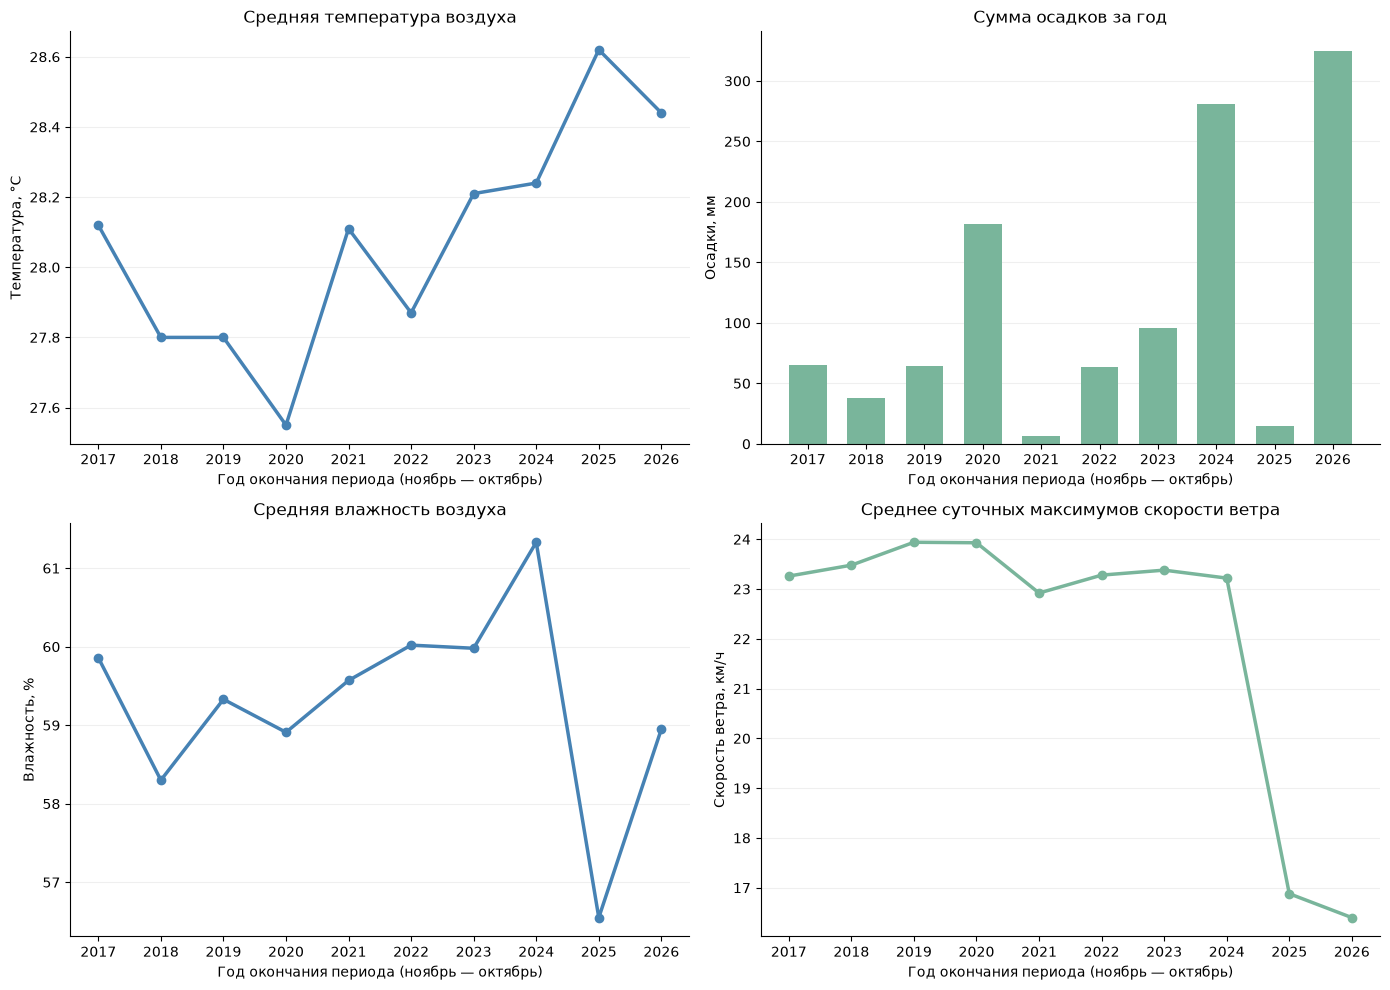

In [30]:
# Преобразуем результаты SQL-запроса в DataFrame.
df_yearly = yearly_weather.DataFrame()

# Подготавливаем числовые показатели.
columns = [
    'temperature_mean',
    'precipitation_total',
    'humidity_mean',
    'wind_speed_mean',
]

df_yearly[columns] = df_yearly[columns].apply(
    pd.to_numeric,
    errors='coerce',
)

# Показатели, подписи и цвета графиков.
metrics = [
    ('temperature_mean', 'Средняя температура воздуха', 'Температура, °C', '#4682B4'),
    ('precipitation_total', 'Сумма осадков за год', 'Осадки, мм', '#79B59B'),
    ('humidity_mean', 'Средняя влажность воздуха', 'Влажность, %', '#4682B4'),
    ('wind_speed_mean', 'Среднее суточных максимумов скорости ветра', 'Скорость ветра, км/ч', '#79B59B'),
]

# Показываем изменения погодных показателей за десять лет.
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, (column, title, ylabel, color) in zip(axes.flat, metrics):

    # Годовую сумму осадков показываем столбцами, остальные показатели — линиями.
    if column == 'precipitation_total':
        ax.bar(
            df_yearly['year'],
            df_yearly[column],
            color=color,
            width=0.65,
        )
    else:
        ax.plot(
            df_yearly['year'],
            df_yearly[column],
            color=color,
            linewidth=2.5,
            marker='o',
            markersize=6,
        )

    ax.set(
        title=title,
        xlabel='Год окончания периода (ноябрь — октябрь)',
        ylabel=ylabel,
        xticks=df_yearly['year'],
    )

    ax.grid(axis='y', alpha=0.2)
    ax.set_axisbelow(True)
    sns.despine(ax=ax)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / 'dubai_yearly_weather_dynamics.png',
    dpi=300,
    bbox_inches='tight',
)

plt.show()

### Вывод

Анализ показал, что погодные условия в Дубае заметно меняются в течение года. Температура достигает максимальных значений летом и снижается зимой. Осадки распределяются неравномерно, а влажность и скорость ветра также имеют сезонные колебания.

Средняя температура за отдельные годы находилась в пределах 27,55–28,62 °C. Самым прохладным оказался период, завершившийся в 2020 году, а самым теплым — в 2025 году. В последние годы средняя температура была выше, чем в большинстве предыдущих периодов, однако для вывода об устойчивом потеплении необходим отдельный анализ тренда.

Наиболее заметные различия между годами наблюдаются по количеству осадков. Минимальная сумма составила 6,7 мм в периоде 2021 года, максимальная — 325 мм в периоде 2026 года. Высокие значения также отмечены в 2020 и 2024 годах. Это показывает, насколько сильно годовое количество осадков может различаться даже в пределах одного десятилетия.

Средняя влажность оставалась относительно стабильной — от 56,55 до 61,33 %. При этом среднее значение суточных максимумов скорости ветра в 2025–2026 годах снизилось примерно до 16–17 км/ч против 23–24 км/ч в предыдущие годы.

Таким образом, наиболее выраженные межгодовые различия наблюдаются в количестве осадков и скорости ветра. Изменения температуры менее значительны, но заслуживают дальнейшего изучения.

## 4. Динамика осадков, частоты дождливых дней и интенсивности дождей

Рассмотрим, как менялись количество осадков и частота дождей в Дубае за период с 1 ноября 2016 года по 31 октября 2026 года.

Для каждого 12-месячного периода (ноябрь — октябрь) рассчитаем общую сумму осадков, количество и долю дождливых дней, среднее количество осадков за дождливый день и максимальное суточное количество осадков.

Это позволит сравнить не только годовые суммы осадков, но и то, насколько часто и интенсивно шли дожди.

In [31]:
%%sql yearly_precipitation <<

-- Формируем исследовательские годы с ноября по октябрь.
-- Каждый период обозначаем годом его окончания.
WITH yearly_data AS (
    SELECT
        CASE
            WHEN EXTRACT(MONTH FROM weather_date) >= 11
                THEN EXTRACT(YEAR FROM weather_date)::int + 1
            ELSE EXTRACT(YEAR FROM weather_date)::int
        END AS year,
        precipitation
    FROM historical_daily
    WHERE city_id = 85
      AND weather_date BETWEEN '2016-11-01' AND '2026-10-31'
)

-- Считаем количество дождливых дней и характеристики осадков
-- отдельно для каждого исследовательского года.
SELECT
    year,
    COUNT(*) AS observed_days,

    -- Дождливым считаем день с количеством осадков больше 0 мм.
    COUNT(*) FILTER (
        WHERE precipitation > 0
    ) AS rainy_days,

    -- Доля дождливых дней от общего количества дней в году.
    ROUND(
        100.0 * COUNT(*) FILTER (WHERE precipitation > 0)
        / NULLIF(COUNT(*), 0),
        2
    ) AS rainy_days_pct,

    -- Общее количество осадков за год.
    ROUND(SUM(precipitation)::numeric, 2) AS total_precipitation,

    -- Среднее количество осадков только за дождливые дни.
    ROUND(
        AVG(precipitation) FILTER (
            WHERE precipitation > 0
        )::numeric,
        2
    ) AS mean_rainy_day_precipitation,

    -- Наибольшее количество осадков, выпавшее за один день.
    ROUND(MAX(precipitation)::numeric, 2) AS max_daily_precipitation

FROM yearly_data
GROUP BY year
ORDER BY year;

In [32]:
yearly_precipitation

year,observed_days,rainy_days,rainy_days_pct,total_precipitation,mean_rainy_day_precipitation,max_daily_precipitation
2017,365,30,8.22,65.20,2.17,11.70
2018,365,23,6.30,37.80,1.64,8.40
2019,365,26,7.12,64.10,2.47,10.20
2020,366,35,9.56,181.60,5.19,81.90
2021,365,8,2.19,6.70,0.84,3.20
2022,365,15,4.11,63.20,4.21,17.70
2023,365,27,7.40,95.80,3.55,23.50
2024,366,32,8.74,281.30,8.79,113.00
2025,365,22,6.03,14.80,0.67,2.40
2026,365,35,9.59,325.00,9.29,108.20


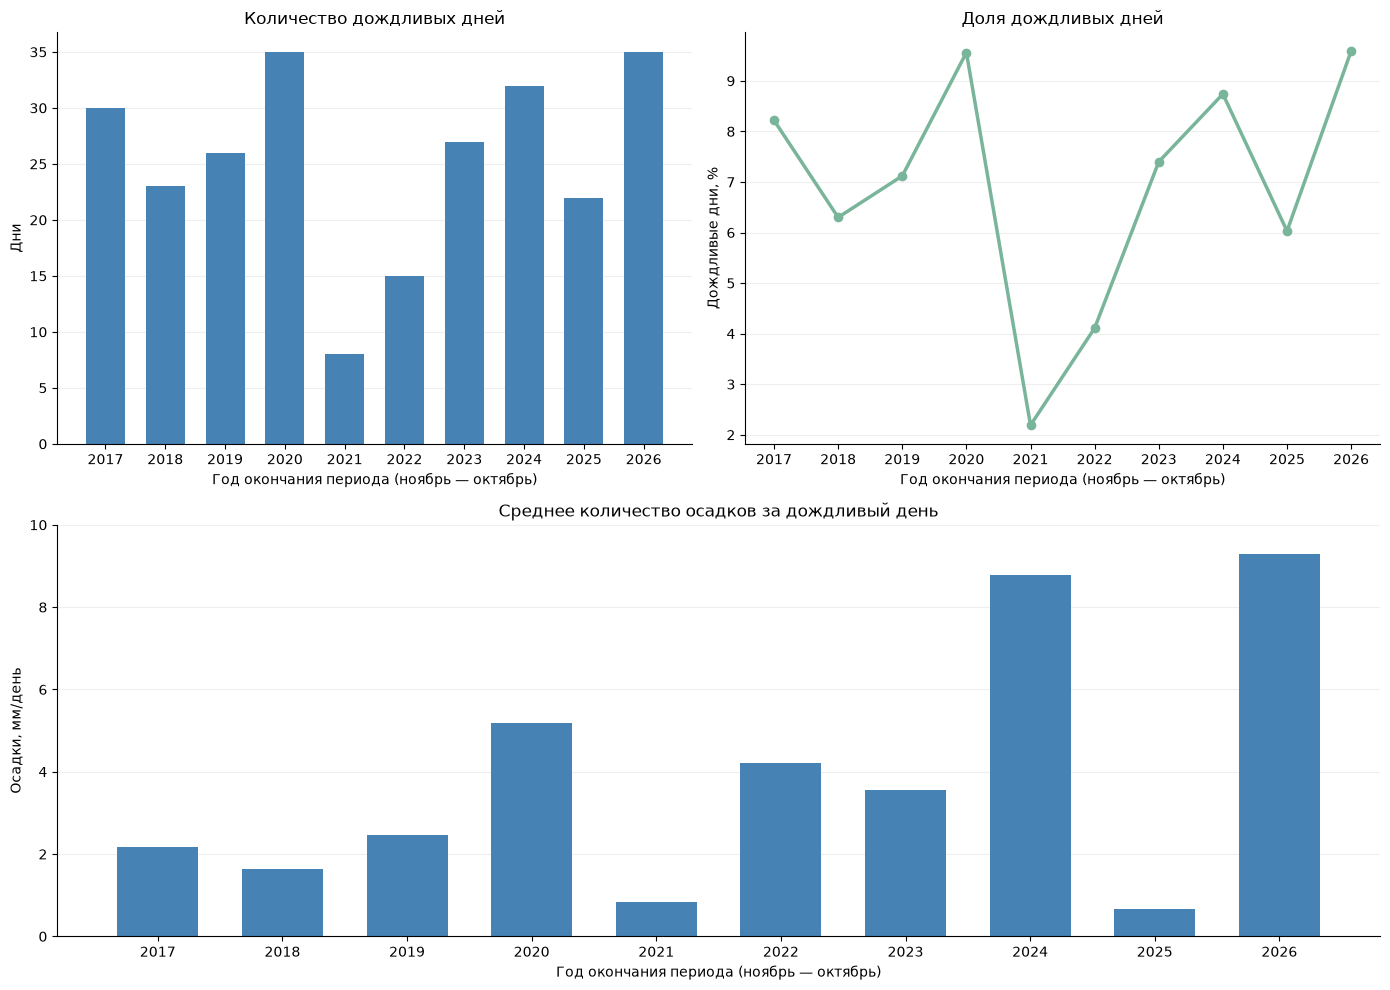

In [33]:
# Преобразуем результаты SQL-запроса в DataFrame.
df_yearly_precip = yearly_precipitation.DataFrame()

# Приводим показатели к числовому типу.
columns = [
    'rainy_days',
    'rainy_days_pct',
    'mean_rainy_day_precipitation',
]

df_yearly_precip[columns] = df_yearly_precip[columns].apply(
    pd.to_numeric,
    errors='coerce',
)

# Показатели, подписи и цвета графиков.
metrics = [
    (
        'rainy_days',
        'Количество дождливых дней',
        'Дни',
        '#4682B4',
    ),
    (
        'rainy_days_pct',
        'Доля дождливых дней',
        'Дождливые дни, %',
        '#79B59B',
    ),
    (
        'mean_rainy_day_precipitation',
        'Среднее количество осадков за дождливый день',
        'Осадки, мм/день',
        '#4682B4',
    ),
]

# Размещаем два графика сверху и один на всю ширину снизу.
fig = plt.figure(figsize=(14, 10))
gs = fig.add_gridspec(2, 2)

axes = [
    fig.add_subplot(gs[0, 0]),
    fig.add_subplot(gs[0, 1]),
    fig.add_subplot(gs[1, :]),
]

for ax, (column, title, ylabel, color) in zip(axes, metrics):

    # Количество дней и осадки показываем столбцами, долю — линией.
    if column == 'rainy_days_pct':
        ax.plot(
            df_yearly_precip['year'],
            df_yearly_precip[column],
            color=color,
            linewidth=2.5,
            marker='o',
            markersize=6,
        )
    else:
        ax.bar(
            df_yearly_precip['year'],
            df_yearly_precip[column],
            color=color,
            width=0.65,
        )

    ax.set(
        title=title,
        xlabel='Год окончания периода (ноябрь — октябрь)',
        ylabel=ylabel,
        xticks=df_yearly_precip['year'],
    )

    # Для нижнего графика задаем шкалу от 0 до 10 мм.
    if column == 'mean_rainy_day_precipitation':
        ax.set_ylim(0, 10)
        ax.set_yticks(range(0, 11, 2))

    ax.grid(axis='y', alpha=0.2)
    ax.set_axisbelow(True)
    sns.despine(ax=ax)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / 'dubai_yearly_precipitation.png',
    dpi=300,
    bbox_inches='tight',
)

plt.show()

In [34]:
%%sql precipitation_by_month <<

-- Рассчитываем месячные суммы осадков и полноту наблюдений.
WITH monthly_data AS (
    SELECT
        CASE
            WHEN EXTRACT(MONTH FROM weather_date) >= 11
                THEN EXTRACT(YEAR FROM weather_date)::int + 1
            ELSE EXTRACT(YEAR FROM weather_date)::int
        END AS year,
        EXTRACT(MONTH FROM weather_date)::int AS month,
        COUNT(*) AS observed_days,
        ROUND(SUM(precipitation)::numeric, 2) AS precipitation_total
    FROM historical_daily
    WHERE city_id = 85
      AND weather_date BETWEEN '2016-11-01' AND '2026-10-31'
    GROUP BY 1, 2
)
SELECT
    year,
    month,
    observed_days,
    EXTRACT(
        DAY FROM (
            MAKE_DATE(
                CASE WHEN month >= 11 THEN year - 1 ELSE year END,
                month,
                1
            ) + INTERVAL '1 month - 1 day'
        )
    )::int AS expected_days,
    precipitation_total
FROM monthly_data
ORDER BY year, month;

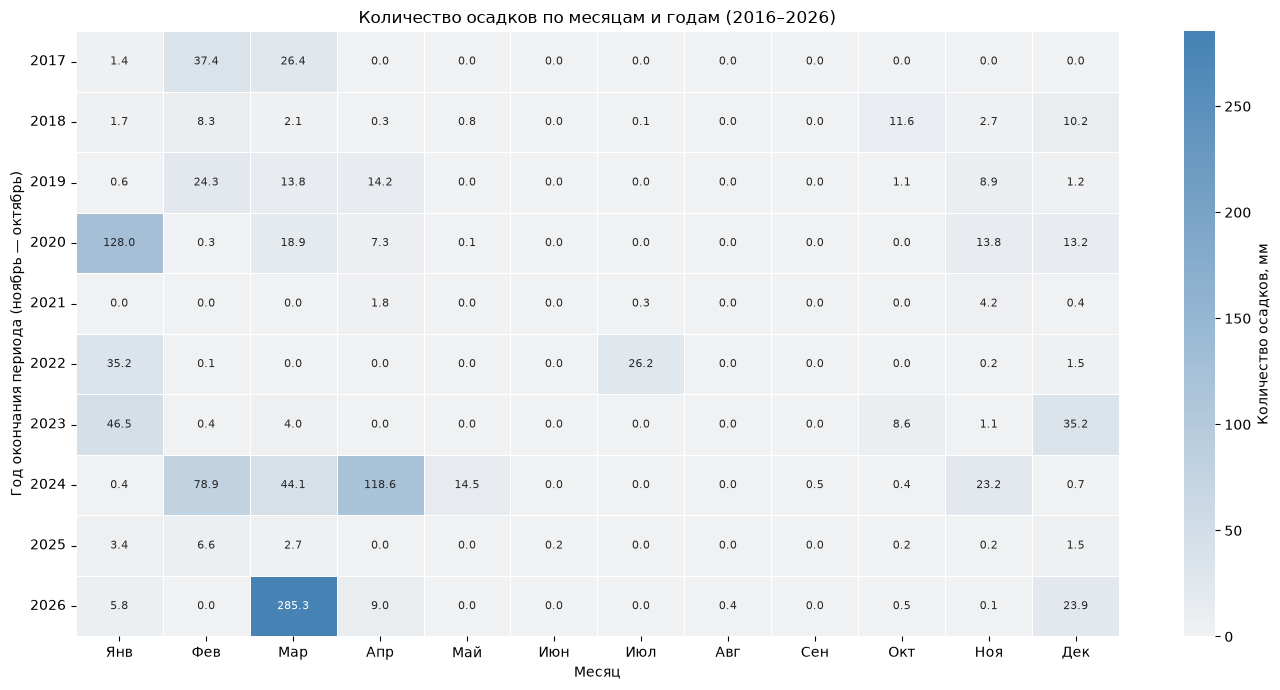

In [35]:
# Преобразуем результат SQL-запроса в DataFrame.
df_precip_month = precipitation_by_month.DataFrame()

# Подготавливаем числовые показатели.
columns = [
    'observed_days',
    'expected_days',
    'precipitation_total',
]

df_precip_month[columns] = df_precip_month[columns].apply(
    pd.to_numeric,
    errors='coerce',
)

# Исключаем неполные месяцы из визуализации.
df_precip_month['precipitation_complete'] = (
    df_precip_month['precipitation_total'].where(
        df_precip_month['observed_days']
        == df_precip_month['expected_days']
    )
)

# Формируем матрицу: строки — исследовательские годы, столбцы — месяцы.
precipitation_matrix = df_precip_month.pivot(
    index='year',
    columns='month',
    values='precipitation_complete',
).reindex(columns=range(1, 13))

# Названия месяцев.
month_labels = [
    'Янв', 'Фев', 'Мар', 'Апр', 'Май', 'Июн',
    'Июл', 'Авг', 'Сен', 'Окт', 'Ноя', 'Дек',
]

# Строим тепловую карту месячных сумм осадков.
fig, ax = plt.subplots(figsize=(14, 7))

sns.heatmap(
    precipitation_matrix,
    cmap=sns.light_palette('#4682B4', as_cmap=True),
    annot=True,
    fmt='.1f',
    annot_kws={'fontsize': 8},
    linewidths=0.5,
    cbar_kws={'label': 'Количество осадков, мм'},
    ax=ax,
)

ax.set(
    title='Количество осадков по месяцам и годам (2016–2026)',
    xlabel='Месяц',
    ylabel='Год окончания периода (ноябрь — октябрь)',
)

ax.set_xticklabels(month_labels, rotation=0)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / 'dubai_monthly_precipitation_heatmap.png',
    dpi=300,
    bbox_inches='tight',
)

plt.show()

### Дни с наибольшим количеством осадков

Рассмотрим 15 дней с максимальным количеством осадков за исследуемый период. Помимо суточной суммы осадков, сравним количество часов с осадками и погодные условия, зафиксированные в эти дни.

In [36]:
%%sql top_precipitation_days <<

-- Выбираем 15 дней с наибольшим количеством осадков
-- за период с 1 ноября 2016 года по 31 октября 2026 года.
SELECT
    weather_date,
    ROUND(precipitation::numeric, 2) AS precipitation_mm,
    ROUND(rain_sum::numeric, 2) AS rain_mm,
    precipitation_hours,
    weather_code
FROM historical_daily
WHERE city_id = 85
  AND weather_date BETWEEN '2016-11-01' AND '2026-10-31'
  AND precipitation > 0
ORDER BY precipitation DESC, weather_date
LIMIT 15;

In [37]:
top_precipitation_days.DataFrame().sort_values('weather_date')

,weather_date,precipitation_mm,rain_mm,precipitation_hours,weather_code
10,2020-01-10,18.50,18.50,21.0,63
2,2020-01-11,81.90,81.90,16.0,65
11,2022-07-27,17.70,17.70,8.0,63
8,2022-12-27,23.50,23.50,16.0,63
12,2023-01-27,17.10,17.10,19.0,63
9,2023-11-17,21.00,21.00,8.0,63
3,2024-02-12,56.90,56.90,17.0,65
6,2024-03-09,37.20,37.20,15.0,65
0,2024-04-16,113.00,113.00,19.0,65
14,2025-12-19,15.40,15.40,10.0,63


In [38]:
%%sql extreme_precipitation <<

-- Формируем исследовательские годы с ноября по октябрь.
-- Каждый период обозначаем годом его окончания.
WITH yearly_data AS (
    SELECT
        CASE
            WHEN EXTRACT(MONTH FROM weather_date) >= 11
                THEN EXTRACT(YEAR FROM weather_date)::int + 1
            ELSE EXTRACT(YEAR FROM weather_date)::int
        END AS year,
        precipitation
    FROM historical_daily
    WHERE city_id = 85
      AND weather_date BETWEEN '2016-11-01' AND '2026-10-31'
)

-- Считаем дни с количеством осадков от 10, 20 и 50 мм
-- и максимальное суточное количество осадков за каждый год.
SELECT
    year,
    COUNT(*) AS observed_days,

    COUNT(*) FILTER (
        WHERE precipitation >= 10
    ) AS days_ge_10mm,

    COUNT(*) FILTER (
        WHERE precipitation >= 20
    ) AS days_ge_20mm,

    COUNT(*) FILTER (
        WHERE precipitation >= 50
    ) AS days_ge_50mm,

    ROUND(MAX(precipitation)::numeric, 2) AS max_daily_precipitation

FROM yearly_data
GROUP BY year
ORDER BY year;

In [39]:
extreme_precipitation

year,observed_days,days_ge_10mm,days_ge_20mm,days_ge_50mm,max_daily_precipitation
2017,365,1,0,0,11.70
2018,365,0,0,0,8.40
2019,365,1,0,0,10.20
2020,366,3,1,1,81.90
2021,365,0,0,0,3.20
2022,365,2,0,0,17.70
2023,365,4,1,0,23.50
2024,366,5,4,2,113.00
2025,365,0,0,0,2.40
2026,365,7,4,2,108.20


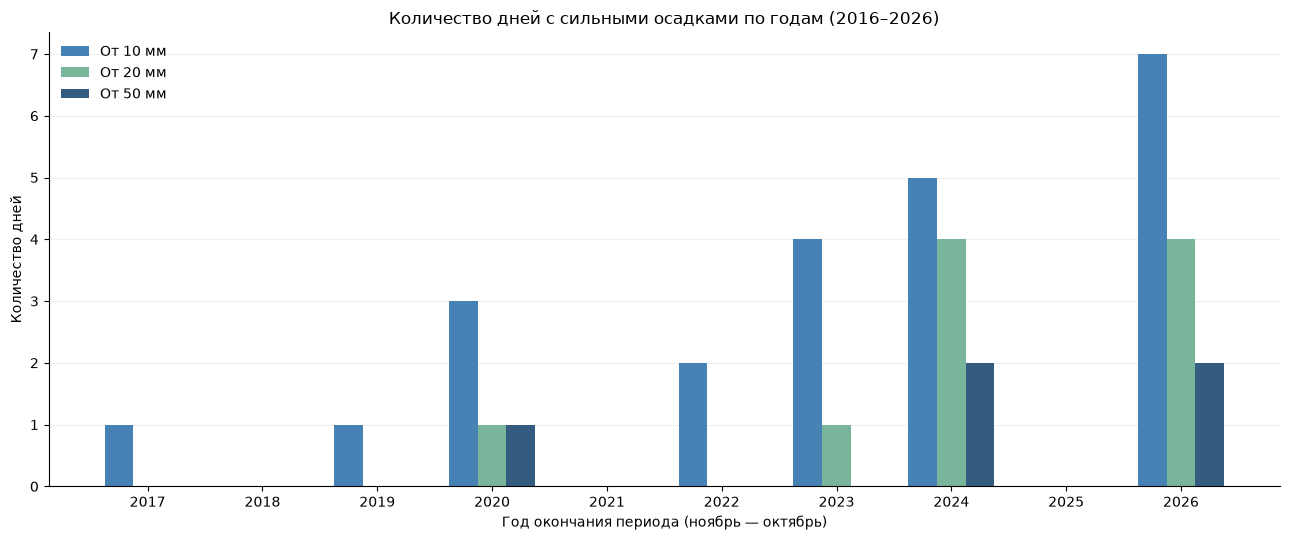

In [40]:
# Преобразуем результаты SQL-запроса в DataFrame.
df_extreme = extreme_precipitation.DataFrame()

# Подготавливаем числовые показатели.
columns = [
    'days_ge_10mm',
    'days_ge_20mm',
    'days_ge_50mm',
]

df_extreme[columns] = df_extreme[columns].apply(
    pd.to_numeric,
    errors='coerce',
)

# Пороговые значения осадков, подписи и цвета.
metrics = [
    (-0.25, 'days_ge_10mm', 'От 10 мм', '#4682B4'),
    (0, 'days_ge_20mm', 'От 20 мм', '#79B59B'),
    (0.25, 'days_ge_50mm', 'От 50 мм', '#345C80'),
]

# Сравниваем количество дней с сильными осадками по годам.
fig, ax = plt.subplots(figsize=(13, 5.5))

x = range(len(df_extreme))
width = 0.25

for offset, column, label, color in metrics:
    ax.bar(
        [position + offset for position in x],
        df_extreme[column],
        width=width,
        label=label,
        color=color,
    )

ax.set(
    title='Количество дней с сильными осадками по годам (2016–2026)',
    xlabel='Год окончания периода (ноябрь — октябрь)',
    ylabel='Количество дней',
    xticks=list(x),
)

ax.set_xticklabels(df_extreme['year'])

# Оставляем на оси Y только целые значения.
ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))

ax.legend(frameon=False)
ax.grid(axis='y', alpha=0.2)
ax.set_axisbelow(True)
sns.despine(ax=ax)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / 'dubai_extreme_precipitation.png',
    dpi=300,
    bbox_inches='tight',
)

plt.show()

### Вывод

За исследуемый период осадки в Дубае распределялись крайне неравномерно. Годовые суммы существенно различались, а наибольшее количество осадков нередко приходилось на отдельные дни с сильными дождями.

Максимальное суточное количество осадков зарегистрировано 16 апреля 2024 года — 113 мм. Высокие значения также наблюдались 27 марта 2026 года (108,2 мм) и 11 января 2020 года (81,9 мм). Особенно выделяется март 2026 года: за пять дней подряд, с 23 по 27 марта, выпало 258,6 мм осадков.

Дни с количеством осадков от 20 мм встречались редко. Наибольшее их число отмечено в 2024 и 2026 годах — по четыре дня, причем в каждом из этих периодов дважды выпадало не менее 50 мм за сутки. В 2025 году, напротив, не было ни одного дня с осадками от 10 мм.

Таким образом, различия между годами связаны не только с частотой дождливых дней, но и с интенсивностью отдельных дождей. Даже несколько дней с большим количеством осадков могут существенно повлиять на годовую сумму.

## 5. Температурные аномалии и экстремальная жара

Рассмотрим температурные аномалии и периоды экстремальной жары в Дубае с 1 ноября 2016 года по 31 октября 2026 года.

В рамках раздела проанализируем:

- отклонения среднесуточной температуры от средних значений для соответствующего календарного дня;
- изменение температурных аномалий по годам;
- количество дней с экстремально высокой температурой;
- продолжительность последовательных периодов жары;
- изменение минимальных и максимальных температур.

Для расчета температурных аномалий используем среднюю температуру каждого календарного дня за исследуемые десять лет.

### Температурные аномалии

Чтобы определить, насколько температура отклонялась от обычных значений, сначала рассчитаем среднюю температуру для каждого календарного дня за десять лет.

Затем сравним с ней фактическую температуру. Положительное отклонение означает, что день был теплее среднего для этой даты, отрицательное — холоднее.

**29 февраля исключим из расчета аномалий**, поскольку за исследуемый период эта дата встречается только дважды — в 2020 и 2024 годах. Для остальных календарных дней доступно по десять наблюдений. Среднее всего по двум дням менее надежно для сравнения.

Для наглядности на графике используем скользящее среднее за 90 дней, чтобы увидеть общую динамику без ежедневных колебаний.

In [41]:
%%sql temperature_anomalies <<

-- Рассчитываем среднюю температуру каждого календарного дня за десять лет.
WITH daily_norm AS (
    SELECT
        EXTRACT(MONTH FROM weather_date)::int AS month,
        EXTRACT(DAY FROM weather_date)::int AS day,
        AVG(temperature_mean) AS temperature_norm,
        COUNT(temperature_mean) AS norm_observations
    FROM historical_daily
    WHERE city_id = 85
      AND weather_date BETWEEN '2016-11-01' AND '2026-10-31'
      AND temperature_mean IS NOT NULL
      AND TO_CHAR(weather_date, 'MM-DD') <> '02-29'
    GROUP BY
        EXTRACT(MONTH FROM weather_date),
        EXTRACT(DAY FROM weather_date)
)

-- Рассчитываем отклонение фактической температуры от среднего значения.
SELECT
    d.weather_date,
    EXTRACT(YEAR FROM d.weather_date)::int AS calendar_year,
    CASE
        WHEN EXTRACT(MONTH FROM d.weather_date) >= 11
            THEN EXTRACT(YEAR FROM d.weather_date)::int + 1
        ELSE EXTRACT(YEAR FROM d.weather_date)::int
    END AS year,
    ROUND(d.temperature_mean::numeric, 2) AS temperature_mean,
    ROUND(n.temperature_norm::numeric, 2) AS temperature_norm,
    ROUND(
        (d.temperature_mean - n.temperature_norm)::numeric,
        2
    ) AS temperature_anomaly,
    n.norm_observations
FROM historical_daily AS d
INNER JOIN daily_norm AS n
    ON EXTRACT(MONTH FROM d.weather_date) = n.month
   AND EXTRACT(DAY FROM d.weather_date) = n.day
WHERE d.city_id = 85
  AND d.weather_date BETWEEN '2016-11-01' AND '2026-10-31'
  AND d.temperature_mean IS NOT NULL
ORDER BY d.weather_date;

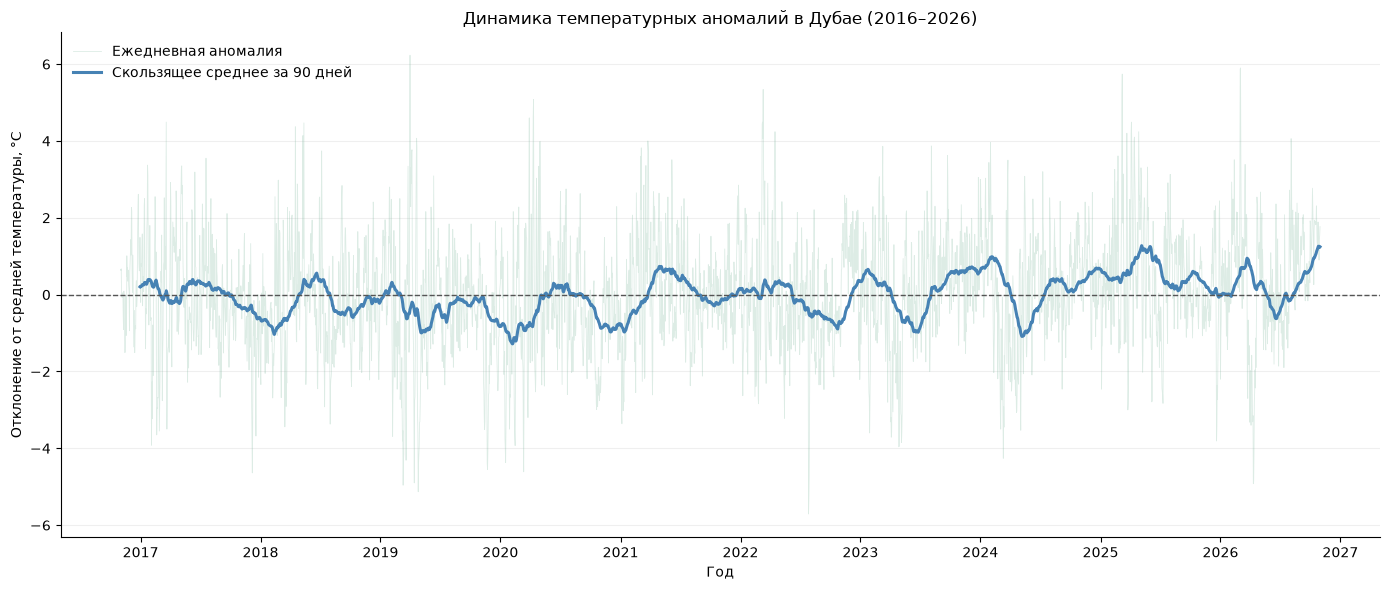

In [42]:
# Преобразуем результаты SQL-запроса в DataFrame.
df_anomalies = temperature_anomalies.DataFrame()

# Подготавливаем даты и числовые значения.
df_anomalies['weather_date'] = pd.to_datetime(
    df_anomalies['weather_date']
)

df_anomalies['temperature_anomaly'] = pd.to_numeric(
    df_anomalies['temperature_anomaly'],
    errors='coerce',
)

df_anomalies = (
    df_anomalies
    .sort_values('weather_date')
    .set_index('weather_date')
)

# Рассчитываем скользящее среднее за 90 календарных дней.
df_anomalies['anomaly_rolling_90d'] = (
    df_anomalies['temperature_anomaly']
    .rolling('90D', min_periods=60)
    .mean()
)

# Строим динамику температурных аномалий.
fig, ax = plt.subplots(figsize=(14, 6))

# Ежедневные отклонения показываем полупрозрачной линией.
ax.plot(
    df_anomalies.index,
    df_anomalies['temperature_anomaly'],
    color='#79B59B',
    linewidth=0.6,
    alpha=0.25,
    label='Ежедневная аномалия',
)

# Скользящее среднее выделяем более заметной линией.
ax.plot(
    df_anomalies.index,
    df_anomalies['anomaly_rolling_90d'],
    color='#4682B4',
    linewidth=2.2,
    label='Скользящее среднее за 90 дней',
)

ax.axhline(
    0,
    color='#555555',
    linestyle='--',
    linewidth=1,
)

ax.set(
    title='Динамика температурных аномалий в Дубае (2016–2026)',
    xlabel='Год',
    ylabel='Отклонение от средней температуры, °C',
)

ax.legend(frameon=False)
ax.grid(axis='y', alpha=0.2)
ax.set_axisbelow(True)
sns.despine(ax=ax)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / 'dubai_temperature_anomalies.png',
    dpi=300,
    bbox_inches='tight',
)

plt.show()

На графике заметны значительные ежедневные колебания температуры относительно средних значений для соответствующих календарных дней. Отдельные отклонения достигают примерно ±6 °C, однако большинство находится в пределах ±2 °C.

Скользящее среднее за 90 дней позволяет увидеть более продолжительные периоды отклонений. Наиболее заметные отрицательные аномалии наблюдались в 2018–2020 годах, когда сглаженные значения местами опускались ниже −1 °C.

Начиная с 2024 года положительные аномалии встречаются чаще и сохраняются дольше. Особенно это заметно в 2025 году и во второй половине 2026 года. Для более точной оценки этих изменений далее сравним средние температурные аномалии по годам.

In [43]:
%%sql yearly_temperature_anomalies <<

-- Рассчитываем среднюю температурную аномалию за каждый исследовательский год.
WITH yearly_data AS (
    SELECT
        year,
        temperature_anomaly
    FROM (
        SELECT
            CASE
                WHEN EXTRACT(MONTH FROM weather_date) >= 11
                    THEN EXTRACT(YEAR FROM weather_date)::int + 1
                ELSE EXTRACT(YEAR FROM weather_date)::int
            END AS year,
            temperature_anomaly
        FROM (
            SELECT
                weather_date,
                temperature_mean - AVG(temperature_mean) OVER (
                    PARTITION BY
                        EXTRACT(MONTH FROM weather_date),
                        EXTRACT(DAY FROM weather_date)
                ) AS temperature_anomaly
            FROM historical_daily
            WHERE city_id = 85
              AND weather_date BETWEEN '2016-11-01' AND '2026-10-31'
              AND temperature_mean IS NOT NULL
              AND TO_CHAR(weather_date, 'MM-DD') <> '02-29'
        ) AS daily_anomalies
    ) AS anomalies_with_year
)

SELECT
    year,
    COUNT(*) AS observed_days,
    ROUND(AVG(temperature_anomaly)::numeric, 2) AS mean_anomaly,
    ROUND(MIN(temperature_anomaly)::numeric, 2) AS min_anomaly,
    ROUND(MAX(temperature_anomaly)::numeric, 2) AS max_anomaly
FROM yearly_data
GROUP BY year
ORDER BY year;

In [44]:
yearly_temperature_anomalies

year,observed_days,mean_anomaly,min_anomaly,max_anomaly
2017,365,0.04,-3.92,4.49
2018,365,-0.28,-4.64,4.47
2019,365,-0.28,-5.13,6.23
2020,365,-0.51,-4.61,5.08
2021,365,0.03,-3.36,4.00
2022,365,-0.21,-5.71,5.34
2023,365,0.13,-3.96,3.87
2024,365,0.18,-4.26,3.96
2025,365,0.54,-3.00,5.74
2026,365,0.36,-4.92,5.90


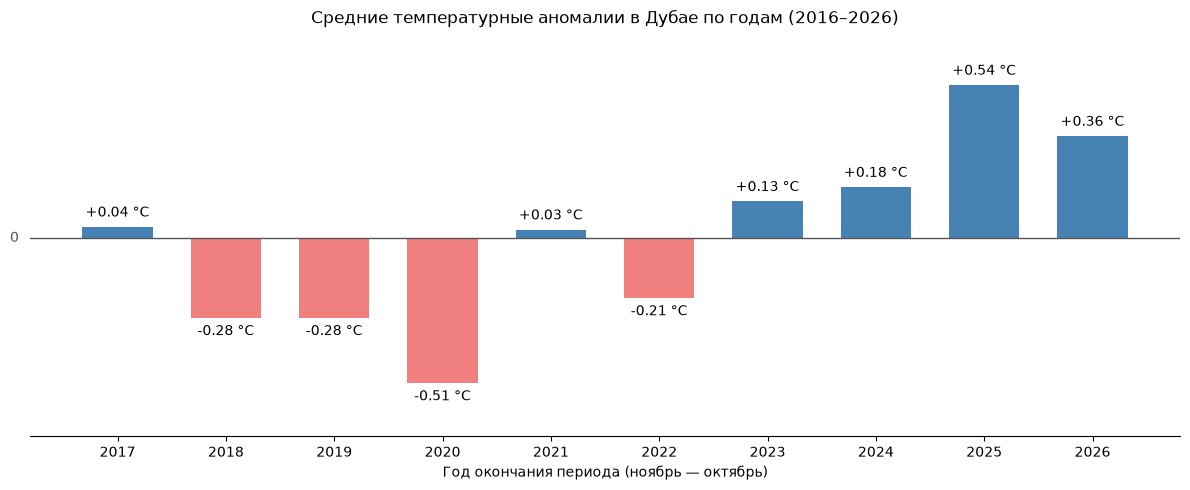

In [45]:
# Преобразуем результаты SQL-запроса в DataFrame.
df_yearly_anomalies = yearly_temperature_anomalies.DataFrame()

df_yearly_anomalies['year'] = pd.to_numeric(
    df_yearly_anomalies['year']
).astype(int)

df_yearly_anomalies['mean_anomaly'] = pd.to_numeric(
    df_yearly_anomalies['mean_anomaly'],
    errors='coerce',
)

# Выбираем цвет в зависимости от знака аномалии.
colors = [
    '#4682B4' if value >= 0 else '#F08080'
    for value in df_yearly_anomalies['mean_anomaly']
]

# Строим средние температурные аномалии по годам.
fig, ax = plt.subplots(figsize=(12, 5))

bars = ax.bar(
    df_yearly_anomalies['year'].astype(str),
    df_yearly_anomalies['mean_anomaly'],
    color=colors,
    width=0.65,
)

# Подписываем значения над положительными и под отрицательными столбцами.
for bar, value in zip(bars, df_yearly_anomalies['mean_anomaly']):
    ax.annotate(
        f'{value:+.2f} °C',
        xy=(bar.get_x() + bar.get_width() / 2, value),
        xytext=(0, 5 if value >= 0 else -5),
        textcoords='offset points',
        ha='center',
        va='bottom' if value >= 0 else 'top',
        fontsize=10,
    )

# Нулевая линия.
ax.axhline(
    0,
    color='#555555',
    linewidth=1,
)

# Подписываем ноль слева от линии.
ax.annotate(
    '0',
    xy=(0, 0),
    xycoords=('axes fraction', 'data'),
    xytext=(-8, 0),
    textcoords='offset points',
    ha='right',
    va='center',
    fontsize=10,
    color='#555555',
)

ax.set(
    title='Средние температурные аномалии в Дубае по годам (2016–2026)',
    xlabel='Год окончания периода (ноябрь — октябрь)',
)

# Убираем ось Y, оставляя только подпись нуля.
ax.set_yticks([])
ax.tick_params(axis='y', left=False, labelleft=False)

ax.margins(y=0.18)
sns.despine(ax=ax, left=True)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / 'dubai_yearly_temperature_anomalies.png',
    dpi=300,
    bbox_inches='tight',
)

plt.show()

### Дни с экстремально высокой температурой

Посмотрим, сколько дней в каждом исследовательском году максимальная температура достигала 40 °C и 45 °C.

Для каждого периода рассчитаем количество и долю таких дней, а также максимальную зарегистрированную температуру. Это позволит сравнить частоту сильной жары по годам.

In [46]:
%%sql extreme_heat_days <<

-- Формируем исследовательские годы с ноября по октябрь.
WITH yearly_data AS (
    SELECT
        CASE
            WHEN EXTRACT(MONTH FROM weather_date) >= 11
                THEN EXTRACT(YEAR FROM weather_date)::int + 1
            ELSE EXTRACT(YEAR FROM weather_date)::int
        END AS year,
        weather_date,
        temperature_max
    FROM historical_daily
    WHERE city_id = 85
      AND weather_date BETWEEN '2016-11-01' AND '2026-10-31'
)
SELECT
    year,
    COUNT(temperature_max) AS observed_days,
    COUNT(*) FILTER (
        WHERE temperature_max >= 40
    ) AS days_ge_40,
    COUNT(*) FILTER (
        WHERE temperature_max >= 45
    ) AS days_ge_45,
    ROUND(
        100.0 * COUNT(*) FILTER (WHERE temperature_max >= 40)
        / NULLIF(COUNT(temperature_max), 0),
        2
    ) AS days_ge_40_pct,
    ROUND(
        100.0 * COUNT(*) FILTER (WHERE temperature_max >= 45)
        / NULLIF(COUNT(temperature_max), 0),
        2
    ) AS days_ge_45_pct,
    ROUND(MAX(temperature_max)::numeric, 2) AS maximum_temperature
FROM yearly_data
GROUP BY year
ORDER BY year;

In [47]:
extreme_heat_days

year,observed_days,days_ge_40,days_ge_45,days_ge_40_pct,days_ge_45_pct,maximum_temperature
2017,365,75,5,20.55,1.37,46.80
2018,365,49,3,13.42,0.82,47.30
2019,365,51,3,13.97,0.82,46.30
2020,366,70,0,19.13,0.00,44.40
2021,365,67,1,18.36,0.27,46.00
2022,365,61,1,16.71,0.27,46.10
2023,365,69,3,18.90,0.82,46.20
2024,366,65,3,17.76,0.82,46.20
2025,365,82,9,22.47,2.47,46.60
2026,365,54,3,14.79,0.82,45.90


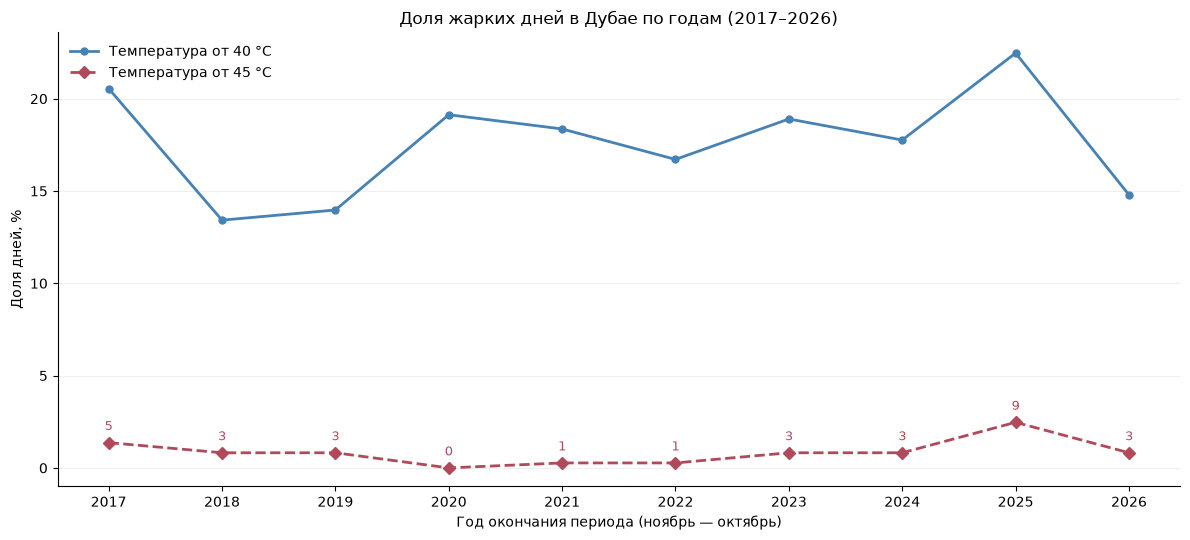

In [48]:
# Преобразуем результаты SQL-запроса в DataFrame.
df_heat = extreme_heat_days.DataFrame()

columns = [
    'year',
    'days_ge_40',
    'days_ge_45',
    'days_ge_40_pct',
    'days_ge_45_pct',
]

df_heat[columns] = df_heat[columns].apply(
    pd.to_numeric,
    errors='coerce',
)

df_heat = df_heat.sort_values('year')

# Строим динамику доли жарких дней по годам.
fig, ax = plt.subplots(figsize=(12, 5.5))

ax.plot(
    df_heat['year'],
    df_heat['days_ge_40_pct'],
    color='#4682B4',
    linewidth=2,
    marker='o',
    markersize=5,
    label='Температура от 40 °C',
)

ax.plot(
    df_heat['year'],
    df_heat['days_ge_45_pct'],
    color='#B04A5A',
    linewidth=2,
    linestyle='--',
    marker='D',
    markersize=6,
    label='Температура от 45 °C',
)

# Подписываем количество дней с температурой от 45 °C.
for _, row in df_heat.iterrows():
    ax.annotate(
        f'{int(row["days_ge_45"])}',
        xy=(row['year'], row['days_ge_45_pct']),
        xytext=(0, 9),
        textcoords='offset points',
        ha='center',
        fontsize=9,
        color='#B04A5A',
    )

ax.set(
    title='Доля жарких дней в Дубае по годам (2017–2026)',
    xlabel='Год окончания периода (ноябрь — октябрь)',
    ylabel='Доля дней, %',
    xticks=df_heat['year'],
)

ax.set_ylim(bottom=-1)

ax.legend(frameon=False)
ax.grid(axis='y', alpha=0.2)
ax.set_axisbelow(True)
sns.despine(ax=ax)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / 'dubai_extreme_heat_days.png',
    dpi=300,
    bbox_inches='tight',
)

plt.show()

### Продолжительные периоды жары

Посмотрим, как часто в Дубае наблюдались периоды продолжительной жары. Будем считать таким периодом не менее пяти дней подряд с максимальной температурой от 40 °C.

Для каждого периода определим даты начала и окончания, продолжительность, максимальную и среднюю температуру.

In [49]:
%%sql heatwaves <<

-- Отбираем дни с температурой от 40 °C.
WITH hot_days AS (
    SELECT
        weather_date,
        temperature_max
    FROM historical_daily
    WHERE city_id = 85
      AND weather_date BETWEEN '2016-11-01' AND '2026-10-31'
      AND temperature_max >= 40
),

-- Объединяем последовательные календарные дни в группы.
numbered_days AS (
    SELECT
        weather_date,
        temperature_max,
        weather_date
            - ROW_NUMBER() OVER (
                ORDER BY weather_date
            )::int AS heatwave_group
    FROM hot_days
),

-- Рассчитываем показатели для периодов продолжительностью от трех дней.
heatwave_periods AS (
    SELECT
        MIN(weather_date) AS start_date,
        MAX(weather_date) AS end_date,
        COUNT(*) AS duration_days,
        ROUND(MAX(temperature_max)::numeric, 2) AS max_temperature,
        ROUND(AVG(temperature_max)::numeric, 2) AS mean_max_temperature
    FROM numbered_days
    GROUP BY heatwave_group
    HAVING COUNT(*) >= 5
)

SELECT
    CASE
        WHEN EXTRACT(MONTH FROM start_date) >= 11
            THEN EXTRACT(YEAR FROM start_date)::int + 1
        ELSE EXTRACT(YEAR FROM start_date)::int
    END AS year,
    start_date,
    end_date,
    duration_days,
    max_temperature,
    mean_max_temperature
FROM heatwave_periods
ORDER BY start_date;

In [50]:
heatwaves

year,start_date,end_date,duration_days,max_temperature,mean_max_temperature
2017,2017-07-06,2017-07-29,24,46.80,43.34
2017,2017-08-02,2017-08-15,14,44.90,43.12
2018,2018-06-03,2018-06-07,5,41.60,41.22
2018,2018-07-04,2018-07-08,5,44.50,42.46
2018,2018-09-02,2018-09-07,6,43.90,42.83
2019,2019-06-25,2019-06-30,6,42.50,41.23
2019,2019-07-20,2019-07-24,5,42.90,41.50
2019,2019-07-26,2019-08-01,7,43.20,42.07
2020,2020-07-08,2020-07-22,15,44.10,42.56
2020,2020-08-22,2020-08-28,7,42.60,41.43


In [51]:
# Преобразуем результаты SQL-запроса в DataFrame.
df_heatwaves = heatwaves.DataFrame()

columns = [
    'year',
    'duration_days',
    'max_temperature',
    'mean_max_temperature',
]

df_heatwaves[columns] = df_heatwaves[columns].apply(
    pd.to_numeric,
    errors='coerce',
)

# Рассчитываем показатели продолжительной жары по годам.
df_heatwaves_yearly = (
    df_heatwaves
    .groupby('year', as_index=False)
    .agg(
        heatwave_count=('duration_days', 'count'),
        max_duration=('duration_days', 'max'),
        total_heatwave_days=('duration_days', 'sum'),
    )
)

display(df_heatwaves_yearly)

,year,heatwave_count,max_duration,total_heatwave_days
0,2017,2,24,38
1,2018,3,6,16
2,2019,3,7,18
3,2020,3,15,29
4,2021,5,11,34
5,2022,5,10,33
6,2023,4,11,32
7,2024,4,9,30
8,2025,9,13,62
9,2026,3,14,30


In [52]:
%%sql yearly_heatwaves <<

-- Сравниваем периоды жары от 5 дней подряд с температурой >= 40 °C.

WITH research_years AS (
    SELECT
        GENERATE_SERIES(2017, 2026) AS year
),

hot_days AS (
    SELECT
        weather_date,
        temperature_max
    FROM historical_daily
    WHERE city_id = 85
      AND weather_date BETWEEN '2016-11-01' AND '2026-10-31'
      AND temperature_max >= 40
),

numbered_days AS (
    -- Группируем последовательные жаркие дни.
    SELECT
        weather_date,
        temperature_max,
        weather_date
            - ROW_NUMBER() OVER (
                ORDER BY weather_date
            )::int AS heatwave_group
    FROM hot_days
),

heatwave_periods AS (
    SELECT
        MIN(weather_date) AS start_date,
        COUNT(*) AS duration_days,
        MAX(temperature_max) AS max_temperature
    FROM numbered_days
    GROUP BY heatwave_group
    HAVING COUNT(*) >= 5
),

heatwave_data AS (
    SELECT
        CASE
            WHEN EXTRACT(MONTH FROM start_date) >= 11
                THEN EXTRACT(YEAR FROM start_date)::int + 1
            ELSE EXTRACT(YEAR FROM start_date)::int
        END AS year,
        duration_days,
        max_temperature
    FROM heatwave_periods
)

SELECT
    y.year,
    COUNT(h.duration_days) AS heatwave_count,
    COALESCE(SUM(h.duration_days), 0) AS total_heatwave_days,
    COALESCE(MAX(h.duration_days), 0) AS max_heatwave_duration,
    ROUND(
        AVG(h.duration_days)::numeric,
        2
    ) AS mean_heatwave_duration,
    ROUND(
        MAX(h.max_temperature)::numeric,
        2
    ) AS max_heatwave_temperature

FROM research_years AS y
LEFT JOIN heatwave_data AS h
    ON y.year = h.year
GROUP BY y.year
ORDER BY y.year;

In [53]:
yearly_heatwaves

year,heatwave_count,total_heatwave_days,max_heatwave_duration,mean_heatwave_duration,max_heatwave_temperature
2017,2,38,24,19.00,46.80
2018,3,16,6,5.33,44.50
2019,3,18,7,6.00,43.20
2020,3,29,15,9.67,44.40
2021,5,34,11,6.80,44.30
2022,5,33,10,6.60,46.10
2023,4,32,11,8.00,46.10
2024,4,30,9,7.50,46.20
2025,9,62,13,6.89,46.60
2026,3,30,14,10.00,45.40


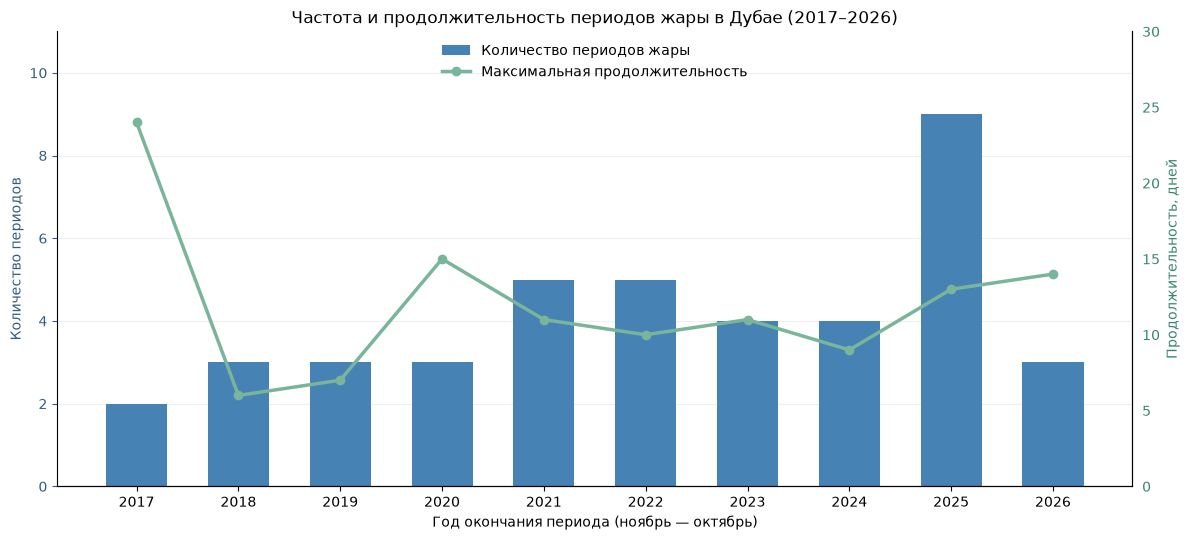

In [54]:
# Преобразуем результаты SQL-запроса в DataFrame.
df_heatwaves = yearly_heatwaves.DataFrame()

columns = [
    'year',
    'heatwave_count',
    'max_heatwave_duration',
]

df_heatwaves[columns] = df_heatwaves[columns].apply(
    pd.to_numeric,
    errors='coerce',
)

df_heatwaves = df_heatwaves.sort_values('year')

# Совмещаем количество периодов жары и максимальную продолжительность.
fig, ax1 = plt.subplots(figsize=(12, 5.5))

ax1.bar(
    df_heatwaves['year'],
    df_heatwaves['heatwave_count'],
    color='#4682B4',
    width=0.6,
    label='Количество периодов жары',
)

ax1.set(
    xlabel='Год окончания периода (ноябрь — октябрь)',
    ylabel='Количество периодов',
    xticks=df_heatwaves['year'],
)

ax1.set_ylim(0, 11)
ax1.set_yticks(range(0, 12, 2))
ax1.yaxis.label.set_color('#345C80')
ax1.tick_params(axis='y', colors='#345C80')

# Вторая ось показывает максимальную продолжительность в днях.
ax2 = ax1.twinx()

ax2.plot(
    df_heatwaves['year'],
    df_heatwaves['max_heatwave_duration'],
    color='#79B59B',
    linewidth=2.5,
    marker='o',
    markersize=6,
    label='Максимальная продолжительность',
)

ax2.set_ylabel('Продолжительность, дней')
ax2.set_ylim(0, 30)
ax2.set_yticks(range(0, 31, 5))
ax2.yaxis.label.set_color('#39866D')
ax2.tick_params(axis='y', colors='#39866D')

ax1.set_title(
    'Частота и продолжительность периодов жары в Дубае (2017–2026)'
)

# Объединяем легенды обеих осей.
handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    handles1 + handles2,
    labels1 + labels2,
    frameon=False,
    loc='upper center',
)

ax1.grid(axis='y', alpha=0.2)
ax1.set_axisbelow(True)

sns.despine(ax=ax1, right=False)
sns.despine(ax=ax2, left=True, right=False)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / 'dubai_yearly_heatwaves.png',
    dpi=300,
    bbox_inches='tight',
)

plt.show()

### Вывод

Температурные аномалии в Дубае заметно различались по годам. Наиболее выраженная отрицательная среднегодовая аномалия наблюдалась в 2020 году (−0,51 °C), а положительная — в 2025 году (+0,54 °C). В 2023–2026 годах средние аномалии оставались положительными, однако десятилетнего периода недостаточно, чтобы уверенно говорить об устойчивом климатическом тренде.

Частота экстремально жарких дней также менялась. В 2025 году максимальная температура достигала 40 °C и выше в течение 82 дней, из них 9 дней — не ниже 45 °C. При этом абсолютный температурный максимум за исследуемый период был зарегистрирован в 2018 году и составил 47,3 °C.

Анализ продолжительных периодов жары (не менее пяти дней подряд с температурой от 40 °C) показал, что в 2025 году наблюдалось наибольшее количество таких периодов — 9, общей продолжительностью 62 дня. Самый длительный непрерывный период жары отмечен в 2017 году — 24 дня. Таким образом, высокая частота жарких дней не обязательно означает рекордную продолжительность отдельного периода жары.

## 6. Взаимосвязи между температурой, осадками, влажностью и ветром

Рассмотрим, как связаны между собой основные погодные показатели в Дубае за период с 1 ноября 2016 года по 31 октября 2026 года.

В рамках раздела проанализируем:

- связь годового количества осадков со средней температурой;
- различия температуры в дождливые и сухие дни;
- изменение температуры до и после дождливых дней;
- взаимосвязи температуры, влажности, осадков и ветра;
- влияние сезонности на выявленные зависимости.

При интерпретации результатов будем учитывать, что наличие корреляции не означает причинно-следственную связь.

In [55]:
%%sql temperature_precipitation_yearly <<

-- Сопоставляем температуру и осадки за исследовательские годы (ноябрь — октябрь).
WITH yearly_data AS (
    SELECT
        CASE
            WHEN EXTRACT(MONTH FROM weather_date) >= 11
                THEN EXTRACT(YEAR FROM weather_date)::int + 1
            ELSE EXTRACT(YEAR FROM weather_date)::int
        END AS year,
        temperature_mean,
        precipitation
    FROM historical_daily
    WHERE city_id = 85
      AND weather_date BETWEEN '2016-11-01' AND '2026-10-31'
)

SELECT
    year,
    ROUND(AVG(temperature_mean)::numeric, 2) AS temperature_mean,
    ROUND(SUM(precipitation)::numeric, 2) AS precipitation_total,
    ROUND(
        100.0 * COUNT(*) FILTER (WHERE precipitation > 0)
        / NULLIF(COUNT(precipitation), 0),
        2
    ) AS rainy_days_pct
FROM yearly_data
GROUP BY year
ORDER BY year;

In [56]:
temperature_precipitation_yearly 

year,temperature_mean,precipitation_total,rainy_days_pct
2017,28.12,65.20,8.22
2018,27.80,37.80,6.30
2019,27.80,64.10,7.12
2020,27.55,181.60,9.56
2021,28.11,6.70,2.19
2022,27.87,63.20,4.11
2023,28.21,95.80,7.40
2024,28.24,281.30,8.74
2025,28.62,14.80,6.03
2026,28.44,325.00,9.59


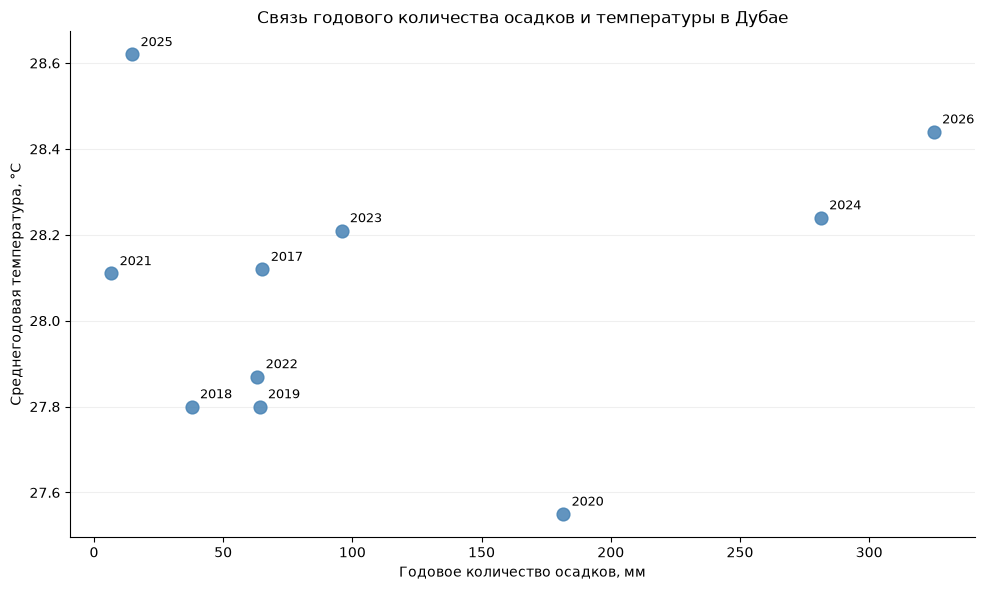

In [57]:
# Преобразуем результаты SQL-запроса в DataFrame.
df_temp_precip = temperature_precipitation_yearly.DataFrame()

columns = [
    'year',
    'temperature_mean',
    'precipitation_total',
    'rainy_days_pct',
]

df_temp_precip[columns] = df_temp_precip[columns].apply(
    pd.to_numeric,
    errors='coerce',
)

df_temp_precip = df_temp_precip.sort_values('year')

# Сопоставляем годовое количество осадков и среднюю температуру.
fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    df_temp_precip['precipitation_total'],
    df_temp_precip['temperature_mean'],
    color='#4682B4',
    s=85,
    alpha=0.85,
)

# Подписываем исследовательские годы.
for _, row in df_temp_precip.iterrows():
    ax.annotate(
        str(int(row['year'])),
        (
            row['precipitation_total'],
            row['temperature_mean'],
        ),
        xytext=(6, 6),
        textcoords='offset points',
        fontsize=9,
    )

ax.set(
    title='Связь годового количества осадков и температуры в Дубае',
    xlabel='Годовое количество осадков, мм',
    ylabel='Среднегодовая температура, °C',
)

ax.grid(axis='y', alpha=0.2)
ax.set_axisbelow(True)
sns.despine(ax=ax)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / 'dubai_temperature_precipitation_yearly.png',
    dpi=300,
    bbox_inches='tight',
)

plt.show()

Сопоставление годового количества осадков и средней температуры не выявило очевидной зависимости между этими показателями. Высокие суммы осадков наблюдались как в относительно прохладном 2020 году, так и в теплом 2026 году. Для более подробного анализа рассмотрим температуру непосредственно в дождливые и сухие дни с учетом сезонности.

### Корреляция годовых погодных показателей

Чтобы оценить взаимосвязи количественно, рассчитаем коэффициенты корреляции Пирсона и Спирмена для средней температуры, годовой суммы осадков и доли дождливых дней.

Дополнительно проверим статистическую значимость полученных связей с помощью p-value. Поскольку анализ охватывает всего десять исследовательских лет, результаты следует интерпретировать с осторожностью.

In [58]:
# Используем годовые показатели из предыдущего SQL-запроса.
df_corr = df_temp_precip.copy()

metric_pairs = [
    (
        'temperature_mean',
        'precipitation_total',
        'Температура — сумма осадков',
    ),
    (
        'temperature_mean',
        'rainy_days_pct',
        'Температура — доля дождливых дней',
    ),
    (
        'precipitation_total',
        'rainy_days_pct',
        'Сумма осадков — доля дождливых дней',
    ),
]

results = []

# Рассчитываем корреляции для каждой пары показателей.
for x_col, y_col, label in metric_pairs:
    data = df_corr[[x_col, y_col]].dropna()

    if len(data) < 3 or (data.nunique() < 2).any():
        pearson_r = pearson_p = None
        spearman_r = spearman_p = None
    else:
        pearson_r, pearson_p = pearsonr(
            data[x_col],
            data[y_col],
        )
        spearman_r, spearman_p = spearmanr(
            data[x_col],
            data[y_col],
        )

    results.append({
        'Показатели': label,
        'Количество лет': len(data),
        'Пирсон r': pearson_r,
        'Пирсон p-value': pearson_p,
        'Спирмен ρ': spearman_r,
        'Спирмен p-value': spearman_p,
    })

df_yearly_correlations = pd.DataFrame(results)

display(df_yearly_correlations.round(4))

,Показатели,Количество лет,Пирсон r,Пирсон p-value,Спирмен ρ,Спирмен p-value
0,Температура — сумма осадков,10,0.1588,0.6612,0.1641,0.6505
1,Температура — доля дождливых дней,10,0.0076,0.9833,0.1216,0.7379
2,Сумма осадков — доля дождливых дней,10,0.7335,0.0158,0.9394,0.0001


Корреляционный анализ не выявил статистически значимой связи средней годовой температуры ни с суммой осадков, ни с долей дождливых дней. Коэффициенты корреляции Пирсона составили 0,16 и 0,01 соответственно.

Между годовой суммой осадков и долей дождливых дней обнаружена сильная положительная связь: коэффициент Пирсона составил 0,73, Спирмена — 0,94. Это означает, что годы с большей долей дождливых дней, как правило, характеризовались и большим общим количеством осадков.

Результаты основаны на десяти годовых наблюдениях. Для более подробного изучения связи температуры и осадков далее рассмотрим ежедневные показатели с учетом сезонности.

### Взаимосвязь температуры и осадков с учетом сезонности

Температура и количество осадков в Дубае существенно различаются в зависимости от времени года. Чтобы сезонные колебания не искажали результаты, сравним показатели каждого месяца со средними значениями того же календарного месяца за десять лет.

Рассчитаем отклонения среднемесячной температуры и месячной суммы осадков от соответствующих средних значений. Затем проверим, связаны ли между собой эти отклонения.

In [59]:
%%sql monthly_weather_anomalies <<

-- Сравниваем месяцы с их сезонной нормой:
-- январь с другими январями, февраль с февралами и т. д.
WITH monthly_data AS (
    SELECT
        DATE_TRUNC('month', weather_date)::date AS month_date,
        EXTRACT(MONTH FROM weather_date)::int AS month,
        COUNT(*) AS observed_days,
        COUNT(temperature_mean) AS temperature_days,
        COUNT(precipitation) AS precipitation_days,
        AVG(temperature_mean) AS temperature_mean,
        SUM(precipitation) AS precipitation_total
    FROM historical_daily
    WHERE city_id = 85
      AND weather_date BETWEEN '2016-11-01' AND '2026-10-31'
    GROUP BY 1, 2
),

complete_months AS (
    -- Исключаем неполные месяцы, чтобы не занижать суммы осадков.
    SELECT *
    FROM monthly_data
    WHERE observed_days = EXTRACT(
        DAY FROM (
            month_date + INTERVAL '1 month - 1 day'
        )
    )::int
      AND temperature_days = observed_days
      AND precipitation_days = observed_days
),

monthly_norms AS (
    -- Рассчитываем средние показатели отдельно для каждого месяца года.
    SELECT
        month,
        AVG(temperature_mean) AS temperature_norm,
        AVG(precipitation_total) AS precipitation_norm,
        COUNT(*) AS norm_months
    FROM complete_months
    GROUP BY month
)

SELECT
    m.month_date,
    m.month,
    ROUND(m.temperature_mean::numeric, 2) AS temperature_mean,
    ROUND(m.precipitation_total::numeric, 2) AS precipitation_total,
    ROUND(
        (m.temperature_mean - n.temperature_norm)::numeric,
        2
    ) AS temperature_anomaly,
    ROUND(
        (m.precipitation_total - n.precipitation_norm)::numeric,
        2
    ) AS precipitation_anomaly,
    n.norm_months
FROM complete_months AS m
INNER JOIN monthly_norms AS n
    ON m.month = n.month
ORDER BY m.month_date;

Рассчитаем корреляции Пирсона и Спирмена между месячными аномалиями температуры и осадков. В отличие от сравнения исходных показателей, здесь учитываются сезонные различия: каждый месяц сопоставляется со средними значениями соответствующего календарного месяца за десять лет.

Это позволит проверить, связаны ли необычно дождливые месяцы с отклонениями температуры от характерных для них значений.

In [60]:
# Проверяем связь месячных аномалий температуры и осадков.
df_monthly_anomalies = monthly_weather_anomalies.DataFrame()

columns = [
    'temperature_anomaly',
    'precipitation_anomaly',
]

df_monthly_anomalies[columns] = df_monthly_anomalies[
    columns
].apply(pd.to_numeric, errors='coerce')

df_monthly_anomalies['month_date'] = pd.to_datetime(
    df_monthly_anomalies['month_date']
)

# Исключаем месяцы с отсутствующими значениями.
df_monthly_corr = df_monthly_anomalies.dropna(
    subset=columns
)

if (
    len(df_monthly_corr) >= 3
    and (df_monthly_corr[columns].nunique() >= 2).all()
):
    pearson_r, pearson_p = pearsonr(
        df_monthly_corr['precipitation_anomaly'],
        df_monthly_corr['temperature_anomaly'],
    )

    spearman_r, spearman_p = spearmanr(
        df_monthly_corr['precipitation_anomaly'],
        df_monthly_corr['temperature_anomaly'],
    )

    df_monthly_correlations = pd.DataFrame([{
        'Количество месяцев': len(df_monthly_corr),
        'Пирсон r': pearson_r,
        'Пирсон p-value': pearson_p,
        'Спирмен ρ': spearman_r,
        'Спирмен p-value': spearman_p,
    }])

    display(df_monthly_correlations.round(4))

else:
    print('Недостаточно данных для расчёта корреляции.')

,Количество месяцев,Пирсон r,Пирсон p-value,Спирмен ρ,Спирмен p-value
0,120,-0.0943,0.3058,-0.2373,0.0091


После учета сезонности обнаружена слабая отрицательная связь между месячными аномалиями температуры и осадков. Коэффициент Спирмена составил −0,24 (p = 0,009), что указывает на тенденцию к более низким температурным аномалиям в месяцах с повышенным количеством осадков.

При этом коэффициент Пирсона составил −0,09 (p = 0,306), поэтому статистически значимой линейной связи не выявлено.

Таким образом, связь температуры и осадков проявляется слабо и зависит от метода оценки. Полученные результаты не позволяют утверждать, что увеличение осадков непосредственно приводит к снижению температуры.

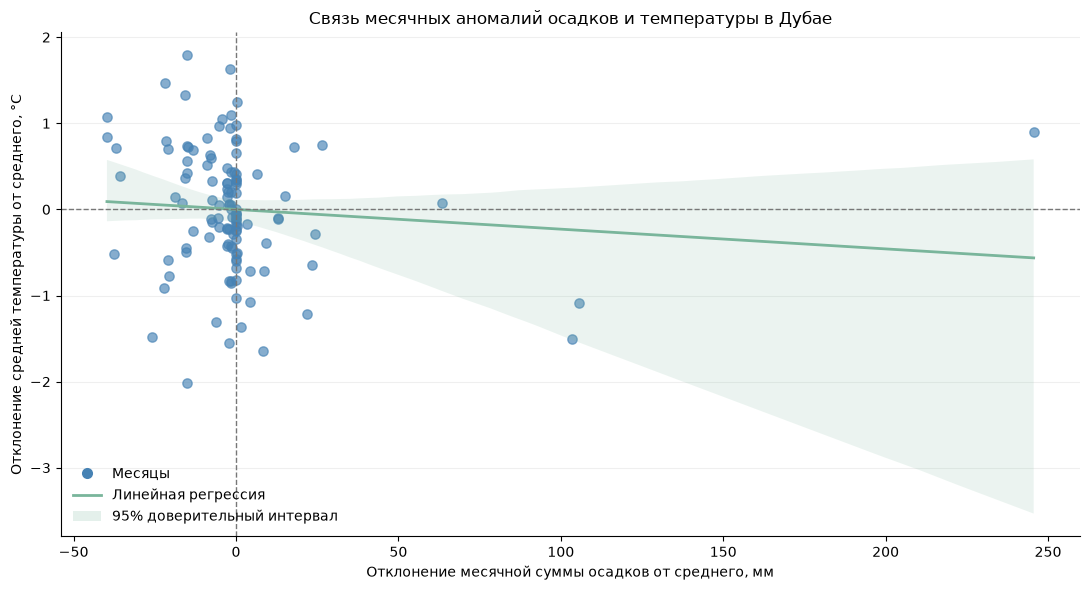

In [61]:
# Сравниваем месячные аномалии температуры и осадков.
fig, ax = plt.subplots(figsize=(11, 6))

sns.regplot(
    data=df_monthly_corr,
    x='precipitation_anomaly',
    y='temperature_anomaly',
    scatter_kws={
        'color': '#4682B4',
        'alpha': 0.65,
        's': 45,
    },
    line_kws={
        'color': '#79B59B',
        'linewidth': 2,
    },
    ci=95,
    ax=ax,
)

# Нулевые линии обозначают средние значения для календарного месяца.
ax.axhline(
    0,
    color='#777777',
    linestyle='--',
    linewidth=1,
)

ax.axvline(
    0,
    color='#777777',
    linestyle='--',
    linewidth=1,
)

ax.set(
    title='Связь месячных аномалий осадков и температуры в Дубае',
    xlabel='Отклонение месячной суммы осадков от среднего, мм',
    ylabel='Отклонение средней температуры от среднего, °C',
)

legend_elements = [
    Line2D(
        [0], [0],
        marker='o',
        linestyle='None',
        markerfacecolor='#4682B4',
        markeredgecolor='none',
        markersize=8,
        label='Месяцы',
    ),
    Line2D(
        [0], [0],
        color='#79B59B',
        linewidth=2,
        label='Линейная регрессия',
    ),
    Patch(
        facecolor='#79B59B',
        alpha=0.2,
        label='95% доверительный интервал',
    ),
]

ax.legend(
    handles=legend_elements,
    frameon=False,
    loc='lower left',
)

ax.grid(axis='y', alpha=0.2)
ax.set_axisbelow(True)
sns.despine(ax=ax)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / 'dubai_monthly_temperature_precipitation_correlation.png',
    dpi=300,
    bbox_inches='tight',
)

plt.show()

График показывает, что большинство месяцев характеризуется небольшими отклонениями количества осадков от средних сезонных значений. При этом температурные аномалии существенно различаются даже при близком количестве осадков.

Линия регрессии имеет небольшой отрицательный наклон, однако линейная связь статистически незначима (r = −0,09; p = 0,306). Корреляция Спирмена указывает на слабую отрицательную зависимость (ρ = −0,24; p = 0,009).

Отдельные месяцы с экстремально большим количеством осадков заметно выделяются на графике. Из-за небольшого числа таких наблюдений неопределенность оценки возрастает. В целом результаты не показывают устойчивой линейной зависимости между месячными аномалиями температуры и осадков.

### Температура в дождливые и сухие дни

Сравним температуру в дни с осадками и без них. Поскольку дожди в Дубае чаще наблюдаются в прохладное время года, будем использовать температурные аномалии относительно средней температуры соответствующего календарного месяца.

Это позволит оценить, отличаются ли дождливые дни от сухих по температуре с учетом сезонных колебаний.

In [62]:
%%sql rainy_dry_temperature <<

-- Сравниваем дождливые и сухие дни с учетом сезонности.
WITH monthly_norm AS (
    SELECT
        EXTRACT(MONTH FROM weather_date)::int AS month,
        AVG(temperature_mean) AS temperature_norm
    FROM historical_daily
    WHERE city_id = 85
      AND weather_date BETWEEN '2016-11-01' AND '2026-10-31'
      AND temperature_mean IS NOT NULL
    GROUP BY 1
),

daily_data AS (
    SELECT
        d.weather_date,
        d.temperature_mean,
        d.precipitation,
        d.temperature_mean - n.temperature_norm AS temperature_anomaly,
        CASE
            WHEN d.precipitation > 0 THEN 'Дождливый день'
            ELSE 'Сухой день'
        END AS day_type
    FROM historical_daily AS d
    INNER JOIN monthly_norm AS n
        ON EXTRACT(MONTH FROM d.weather_date) = n.month
    WHERE d.city_id = 85
      AND d.weather_date BETWEEN '2016-11-01' AND '2026-10-31'
      AND d.temperature_mean IS NOT NULL
      AND d.precipitation IS NOT NULL
)

SELECT
    weather_date,
    day_type,
    ROUND(temperature_mean::numeric, 2) AS temperature_mean,
    ROUND(temperature_anomaly::numeric, 2) AS temperature_anomaly,
    ROUND(precipitation::numeric, 2) AS precipitation
FROM daily_data
ORDER BY weather_date;

day_type,days,mean,median,std
Сухой день,3399,-0.010000,-0.040000,1.740000
Дождливый день,253,0.080000,0.230000,1.990000


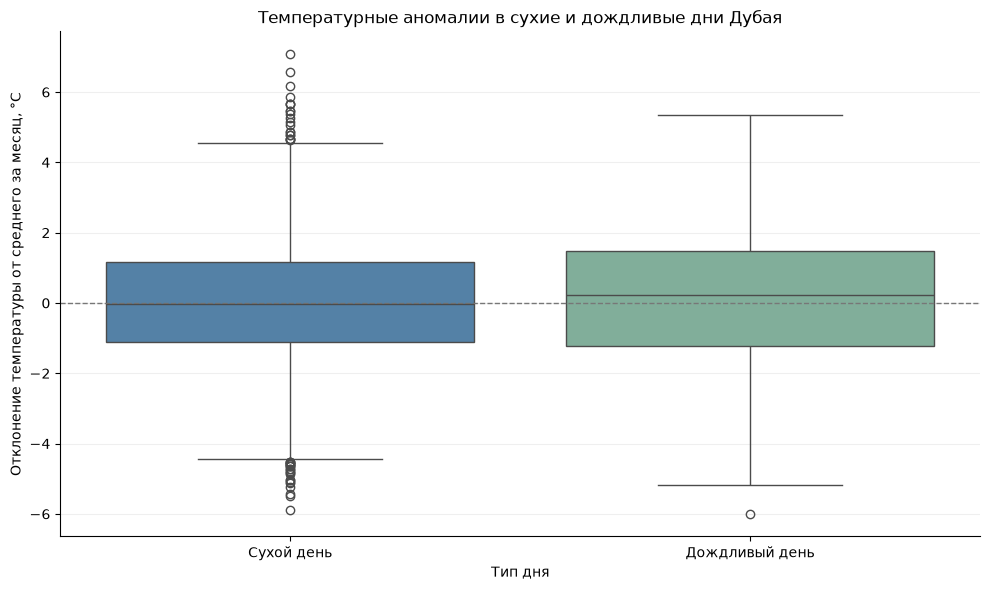

In [63]:
# Сравниваем температурные аномалии в сухие и дождливые дни.
df_rainy_dry = rainy_dry_temperature.DataFrame()

columns = [
    'temperature_anomaly',
    'precipitation',
]

df_rainy_dry[columns] = df_rainy_dry[columns].apply(
    pd.to_numeric,
    errors='coerce',
)

day_order = ['Сухой день', 'Дождливый день']

# Рассчитываем статистику для каждой группы.
df_rainy_dry_stats = (
    df_rainy_dry
    .groupby('day_type')['temperature_anomaly']
    .agg(
        days='count',
        mean='mean',
        median='median',
        std='std',
    )
    .reindex(day_order)
    .reset_index()
    .round(2)
)

display(
    df_rainy_dry_stats.style.hide(axis='index')
)

# Сравниваем распределения температурных аномалий.
fig, ax = plt.subplots(figsize=(10, 6))

sns.boxplot(
    data=df_rainy_dry,
    x='day_type',
    y='temperature_anomaly',
    order=day_order,
    hue='day_type',
    hue_order=day_order,
    palette={
        'Сухой день': '#4682B4',
        'Дождливый день': '#79B59B',
    },
    legend=False,
    ax=ax,
)

ax.axhline(
    0,
    color='#777777',
    linestyle='--',
    linewidth=1,
)

ax.set(
    title='Температурные аномалии в сухие и дождливые дни Дубая',
    xlabel='Тип дня',
    ylabel='Отклонение температуры от среднего за месяц, °C',
)

ax.grid(axis='y', alpha=0.2)
ax.set_axisbelow(True)
sns.despine(ax=ax)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / 'dubai_rainy_dry_temperature.png',
    dpi=300,
    bbox_inches='tight',
)

plt.show()

Сравнение температурных аномалий показало, что дождливые дни в Дубае не обязательно холоднее сухих. Средняя аномалия в дождливые дни составила +0,08 °C, в сухие — −0,01 °C. Медианные значения также немного выше в дождливые дни: +0,23 °C против −0,04 °C.

Разброс температурных аномалий в дождливые дни несколько больше, однако распределения двух групп существенно перекрываются. Таким образом, заметного снижения среднесуточной температуры непосредственно в дождливые дни не наблюдается.

### Температура до и после дождя

Рассмотрим, как меняется температура за три дня до и после дождя. Для анализа выберем только отдельные дождливые дни, когда в течение трех суток до и после осадков не было.

Для каждого такого случая рассчитаем температурные аномалии относительно среднего значения соответствующего календарного месяца. Это позволит сравнить температуру до дождя, в день осадков и после него с учетом сезонности.

In [64]:
%%sql temperature_around_rain <<

-- Анализируем температуру за 3 дня до и после дождя.
-- Дождливый день считаем изолированным, если в соседние
-- 3 дня до и после него осадки отсутствовали.
-- Используем температурные аномалии для устранения сезонности.

WITH daily_data AS (
    SELECT
        weather_date,
        temperature_mean,
        precipitation,
        EXTRACT(MONTH FROM weather_date)::int AS month
    FROM historical_daily
    WHERE city_id = 85
      AND weather_date BETWEEN '2016-11-01' AND '2026-10-31'
),

monthly_norm AS (
    SELECT
        month,
        AVG(temperature_mean) AS temperature_norm
    FROM daily_data
    GROUP BY month
),

rain_events AS (
    -- Выбираем дождливые дни с полным семидневным окном
    -- и без других дождей в пределах этого окна.
    SELECT
        d.weather_date AS rain_date
    FROM daily_data AS d
    INNER JOIN daily_data AS w
        ON w.weather_date BETWEEN
            d.weather_date - 3 AND d.weather_date + 3
    WHERE d.precipitation > 0
    GROUP BY d.weather_date
    HAVING COUNT(*) = 7
       AND COUNT(w.temperature_mean) = 7
       AND COUNT(w.precipitation) = 7
       AND COUNT(*) FILTER (
           WHERE w.precipitation > 0
       ) = 1
),

event_temperatures AS (
    SELECT
        e.rain_date,
        (d.weather_date - e.rain_date) AS day_offset,
        d.temperature_mean - n.temperature_norm AS temperature_anomaly
    FROM rain_events AS e
    INNER JOIN daily_data AS d
        ON d.weather_date BETWEEN
            e.rain_date - 3 AND e.rain_date + 3
    INNER JOIN monthly_norm AS n
        ON d.month = n.month
)

SELECT
    day_offset,
    COUNT(*) AS observations,
    ROUND(AVG(temperature_anomaly)::numeric, 3) AS mean_anomaly,
    ROUND(STDDEV_SAMP(temperature_anomaly)::numeric, 3) AS std_anomaly
FROM event_temperatures
GROUP BY day_offset
ORDER BY day_offset;

In [65]:
temperature_around_rain

day_offset,observations,mean_anomaly,std_anomaly
-3,61,0.129,1.937
-2,61,0.088,1.863
-1,61,0.120,1.602
0,61,0.075,1.747
1,61,-0.193,1.925
2,61,-0.461,1.860
3,61,-0.316,1.902


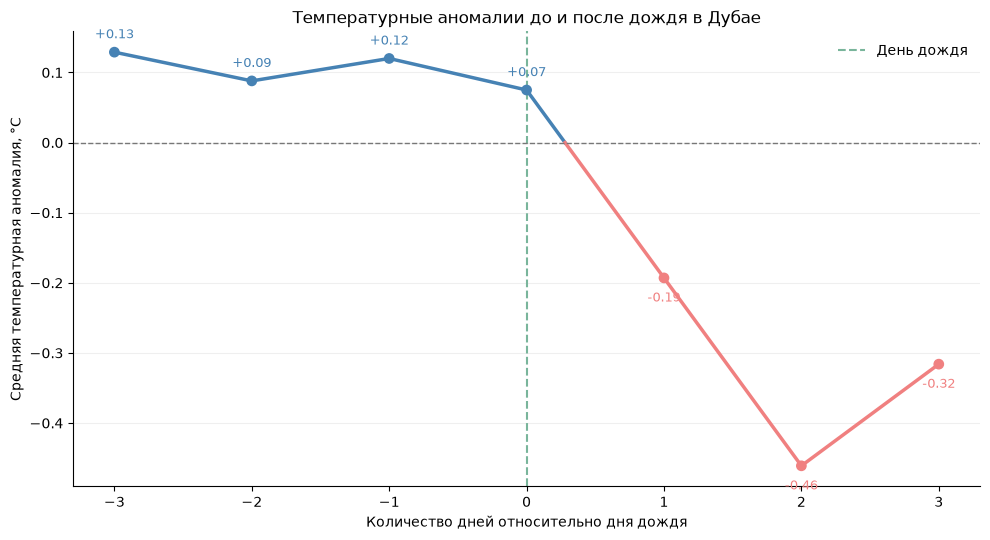

In [66]:
# Сравниваем температурные аномалии до и после дождя.
df_rain_effect = temperature_around_rain.DataFrame()

columns = [
    'day_offset',
    'mean_anomaly',
    'std_anomaly',
]

df_rain_effect[columns] = df_rain_effect[columns].apply(
    pd.to_numeric,
    errors='coerce',
)

df_rain_effect = df_rain_effect.sort_values('day_offset')

x = df_rain_effect['day_offset'].to_numpy()
y = df_rain_effect['mean_anomaly'].to_numpy()

fig, ax = plt.subplots(figsize=(10, 5.5))

# Разделяем линию на положительные и отрицательные участки.
for i in range(len(x) - 1):
    x1, x2 = x[i], x[i + 1]
    y1, y2 = y[i], y[i + 1]

    if y1 >= 0 and y2 >= 0:
        ax.plot(
            [x1, x2], [y1, y2],
            color='#4682B4',
            linewidth=2.5,
        )

    elif y1 <= 0 and y2 <= 0:
        ax.plot(
            [x1, x2], [y1, y2],
            color='#F08080',
            linewidth=2.5,
        )

    else:
        # Находим точку пересечения линии с нулём.
        x_zero = x1 - y1 * (x2 - x1) / (y2 - y1)

        ax.plot(
            [x1, x_zero], [y1, 0],
            color='#4682B4' if y1 > 0 else '#F08080',
            linewidth=2.5,
        )

        ax.plot(
            [x_zero, x2], [0, y2],
            color='#F08080' if y2 < 0 else '#4682B4',
            linewidth=2.5,
        )

# Окрашиваем точки в зависимости от знака аномалии.
point_colors = [
    '#4682B4' if value >= 0 else '#F08080'
    for value in y
]

ax.scatter(
    x,
    y,
    c=point_colors,
    s=45,
    zorder=3,
)

# Отмечаем день дождя и нулевую температурную аномалию.
ax.axvline(
    0,
    color='#79B59B',
    linestyle='--',
    linewidth=1.5,
    label='День дождя',
)

ax.axhline(
    0,
    color='#777777',
    linestyle='--',
    linewidth=1,
)

# Подписываем средние температурные аномалии.
for day, value, color in zip(x, y, point_colors):
    ax.annotate(
        f'{value:+.2f}',
        (day, value),
        xytext=(0, 10 if value >= 0 else -17),
        textcoords='offset points',
        ha='center',
        fontsize=9,
        color=color,
    )

ax.set(
    title='Температурные аномалии до и после дождя в Дубае',
    xlabel='Количество дней относительно дня дождя',
    ylabel='Средняя температурная аномалия, °C',
    xticks=range(-3, 4),
)

ax.legend(frameon=False)
ax.grid(axis='y', alpha=0.2)
ax.set_axisbelow(True)
sns.despine(ax=ax)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / 'dubai_temperature_around_rain.png',
    dpi=300,
    bbox_inches='tight',
)

plt.show()

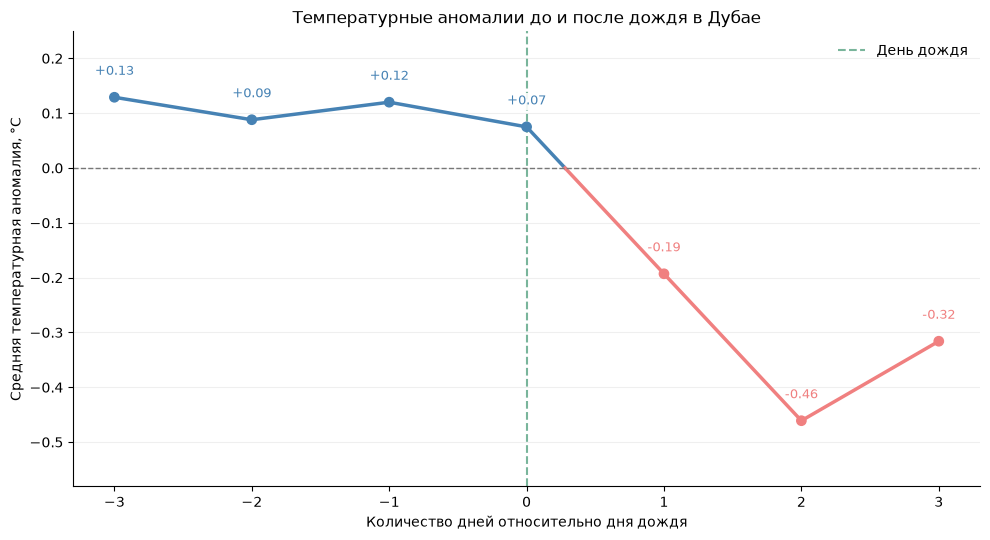

In [67]:
# Сравниваем температурные аномалии до и после дождя.
df_rain_effect = temperature_around_rain.DataFrame()

columns = [
    'day_offset',
    'mean_anomaly',
    'std_anomaly',
]

df_rain_effect[columns] = df_rain_effect[columns].apply(
    pd.to_numeric,
    errors='coerce',
)

df_rain_effect = df_rain_effect.sort_values('day_offset')

x = df_rain_effect['day_offset'].to_numpy()
y = df_rain_effect['mean_anomaly'].to_numpy()

fig, ax = plt.subplots(figsize=(10, 5.5))

# Окрашиваем линию в зависимости от знака аномалии.
for i in range(len(x) - 1):
    x1, x2 = x[i], x[i + 1]
    y1, y2 = y[i], y[i + 1]

    if y1 >= 0 and y2 >= 0:
        ax.plot(
            [x1, x2], [y1, y2],
            color='#4682B4',
            linewidth=2.5,
        )

    elif y1 <= 0 and y2 <= 0:
        ax.plot(
            [x1, x2], [y1, y2],
            color='#F08080',
            linewidth=2.5,
        )

    else:
        # Находим пересечение линии с нулем.
        x_zero = x1 - y1 * (x2 - x1) / (y2 - y1)

        ax.plot(
            [x1, x_zero], [y1, 0],
            color='#4682B4' if y1 > 0 else '#F08080',
            linewidth=2.5,
        )

        ax.plot(
            [x_zero, x2], [0, y2],
            color='#F08080' if y2 < 0 else '#4682B4',
            linewidth=2.5,
        )

point_colors = [
    '#4682B4' if value >= 0 else '#F08080'
    for value in y
]

ax.scatter(
    x,
    y,
    c=point_colors,
    s=45,
    zorder=3,
)

# Отмечаем день дождя и нулевую аномалию.
ax.axvline(
    0,
    color='#79B59B',
    linestyle='--',
    linewidth=1.5,
    label='День дождя',
)

ax.axhline(
    0,
    color='#777777',
    linestyle='--',
    linewidth=1,
)

# Подписываем значения
for day, value, color in zip(x, y, point_colors):
    ax.annotate(
        f'{value:+.2f}',
        (day, value),
        xytext=(0, 14),
        textcoords='offset points',
        ha='center',
        va='bottom',
        fontsize=9,
        color=color,
        bbox=(
            {
                'facecolor': 'white',
                'edgecolor': 'none',
                'alpha': 0.9,
                'pad': 1.5,
            }
            if day == 0 else None
        ),
        zorder=4,
    )

ax.set(
    title='Температурные аномалии до и после дождя в Дубае',
    xlabel='Количество дней относительно дня дождя',
    ylabel='Средняя температурная аномалия, °C',
    xticks=range(-3, 4),
)

# Добавляем пространство для подписей.
ax.set_ylim(y.min() - 0.12, y.max() + 0.12)

ax.legend(frameon=False)
ax.grid(axis='y', alpha=0.2)
ax.set_axisbelow(True)
sns.despine(ax=ax)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / 'dubai_temperature_around_rain.png',
    dpi=300,
    bbox_inches='tight',
)

plt.show()

### Взаимосвязи основных погодных показателей

Рассмотрим взаимосвязи температуры, осадков, влажности и скорости ветра на основе ежедневных наблюдений.

Для каждого показателя рассчитаем отклонение от среднего значения соответствующего календарного месяца за десять лет. Это позволит уменьшить влияние сезонности и оценить связи между погодными показателями.

In [68]:
%%sql weather_correlations <<

-- Рассчитываем дневные показатели и их отклонения от средних
-- значений соответствующего календарного месяца.
WITH hourly_daily AS (
    SELECT
        (weather_time AT TIME ZONE 'Asia/Dubai')::date AS weather_date,
        AVG(humidity) AS humidity_mean,
        AVG(wind_speed) AS wind_speed_mean,
        COUNT(*) AS observed_hours,
        COUNT(humidity) AS humidity_hours,
        COUNT(wind_speed) AS wind_hours
    FROM historical_hourly
    WHERE city_id = 85
      AND weather_time >= (
          TIMESTAMP '2016-11-01 00:00:00'
          AT TIME ZONE 'Asia/Dubai'
      )
      AND weather_time < (
          TIMESTAMP '2026-11-01 00:00:00'
          AT TIME ZONE 'Asia/Dubai'
      )
    GROUP BY 1
),

daily_data AS (
    SELECT
        d.weather_date,
        EXTRACT(MONTH FROM d.weather_date)::int AS month,
        d.temperature_mean,
        d.precipitation,
        h.humidity_mean,
        h.wind_speed_mean
    FROM historical_daily AS d
    INNER JOIN hourly_daily AS h
        ON d.weather_date = h.weather_date
    WHERE d.city_id = 85
      AND d.weather_date BETWEEN '2016-11-01' AND '2026-10-31'
      AND h.observed_hours = 24
      AND h.humidity_hours = 24
      AND h.wind_hours = 24
      AND d.temperature_mean IS NOT NULL
      AND d.precipitation IS NOT NULL
),

seasonal_norms AS (
    SELECT
        month,
        AVG(temperature_mean) AS temperature_norm,
        AVG(precipitation) AS precipitation_norm,
        AVG(humidity_mean) AS humidity_norm,
        AVG(wind_speed_mean) AS wind_norm
    FROM daily_data
    GROUP BY month
)

SELECT
    d.weather_date,
    ROUND(
        (d.temperature_mean - n.temperature_norm)::numeric, 3
    ) AS temperature_anomaly,
    ROUND(
        (d.precipitation - n.precipitation_norm)::numeric, 3
    ) AS precipitation_anomaly,
    ROUND(
        (d.humidity_mean - n.humidity_norm)::numeric, 3
    ) AS humidity_anomaly,
    ROUND(
        (d.wind_speed_mean - n.wind_norm)::numeric, 3
    ) AS wind_anomaly
FROM daily_data AS d
INNER JOIN seasonal_norms AS n
    ON d.month = n.month
ORDER BY d.weather_date;

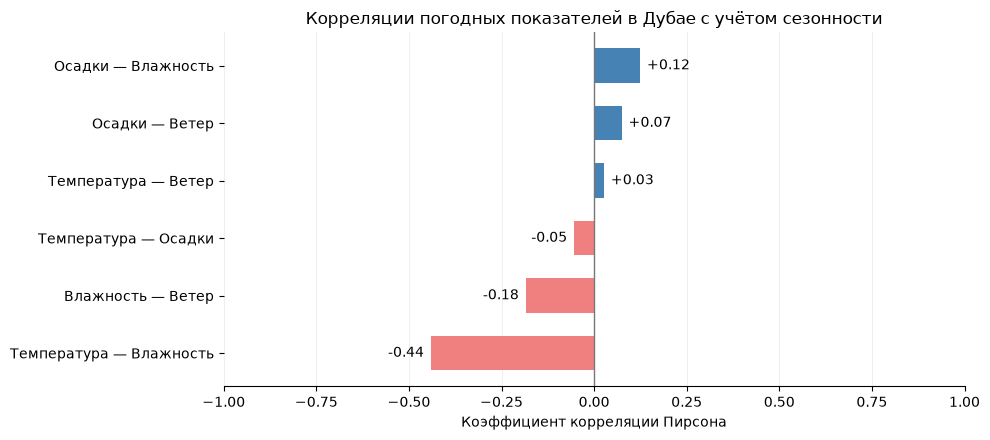

In [69]:
# Рассчитываем корреляции погодных показателей с учетом сезонности.
df_weather_corr = weather_correlations.DataFrame()

columns = [
    'temperature_anomaly',
    'precipitation_anomaly',
    'humidity_anomaly',
    'wind_anomaly',
]

df_weather_corr[columns] = df_weather_corr[columns].apply(
    pd.to_numeric,
    errors='coerce',
)

corr_matrix = df_weather_corr[columns].corr(method='pearson')

# Оставляем только уникальные пары показателей.
labels = {
    'temperature_anomaly': 'Температура',
    'precipitation_anomaly': 'Осадки',
    'humidity_anomaly': 'Влажность',
    'wind_anomaly': 'Ветер',
}

pairs = []

for i, first in enumerate(columns):
    for second in columns[i + 1:]:
        pairs.append({
            'pair': f'{labels[first]} — {labels[second]}',
            'correlation': corr_matrix.loc[first, second],
        })

df_pairs = pd.DataFrame(pairs).dropna()
df_pairs = df_pairs.sort_values('correlation')

# Отрицательные и положительные корреляции выделяем разными цветами.
colors = [
    '#F08080' if value < 0 else '#4682B4'
    for value in df_pairs['correlation']
]

fig, ax = plt.subplots(figsize=(10, 4.5))

bars = ax.barh(
    df_pairs['pair'],
    df_pairs['correlation'],
    color=colors,
    height=0.6,
)

ax.bar_label(
    bars,
    fmt='%+.2f',
    padding=5,
    fontsize=10,
)

ax.axvline(
    0,
    color='#777777',
    linewidth=1,
)

ax.set(
    title='Корреляции погодных показателей в Дубае с учётом сезонности',
    xlabel='Коэффициент корреляции Пирсона',
    ylabel='',
)

ax.set_xlim(-1, 1)
ax.grid(axis='x', alpha=0.2)
ax.set_axisbelow(True)
sns.despine(ax=ax, left=True)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / 'dubai_weather_correlations.png',
    dpi=300,
    bbox_inches='tight',
)

plt.show()

Наиболее выраженная взаимосвязь обнаружена между температурой и влажностью: коэффициент корреляции Пирсона составил −0,44. Это означает, что дни с температурой выше среднего для соответствующего месяца чаще характеризовались пониженной относительной влажностью.

Между влажностью и скоростью ветра наблюдается слабая отрицательная связь (r = −0,18), а между осадками и влажностью — слабая положительная (r = +0,12).

Корреляции остальных показателей близки к нулю. В частности, связь температуры и осадков на ежедневных данных оказалась очень слабой (r = −0,05).

Таким образом, после учета сезонности наиболее заметная взаимосвязь наблюдается между температурой и относительной влажностью. Для остальных пар линейные зависимости выражены слабо или практически отсутствуют.

### Связь осадков с температурой в последующие дни

Проверим, связаны ли отклонения суточного количества осадков от средних сезонных значений с температурными аномалиями в тот же день и через 1–5 дней.

Для каждого временного сдвига рассчитаем коэффициент корреляции Пирсона. В отличие от анализа отдельных дождливых дней, здесь используются все доступные ежедневные наблюдения.

In [70]:
%%sql precipitation_temperature_lags <<

-- Проверяем связь количества осадков с температурой
-- в тот же день и через 1–5 календарных дней.
WITH daily_data AS (
    SELECT
        weather_date,
        EXTRACT(MONTH FROM weather_date)::int AS month,
        temperature_mean,
        precipitation
    FROM historical_daily
    WHERE city_id = 85
      AND weather_date BETWEEN '2016-11-01' AND '2026-10-31'
),

monthly_norm AS (
    -- Устраняем сезонность относительно календарного месяца.
    SELECT
        month,
        AVG(temperature_mean) AS temperature_norm,
        AVG(precipitation) AS precipitation_norm
    FROM daily_data
    GROUP BY month
),

daily_anomalies AS (
    SELECT
        d.weather_date,
        d.temperature_mean - n.temperature_norm AS temperature_anomaly,
        d.precipitation - n.precipitation_norm AS precipitation_anomaly
    FROM daily_data AS d
    INNER JOIN monthly_norm AS n
        ON d.month = n.month
),

lagged_data AS (
    -- Соединяем наблюдения по календарным датам, а не по
    -- номерам строк: пропущенные дни не смещают интервалы.
    SELECT
        d.weather_date,
        d.precipitation_anomaly,
        s.day_offset,
        t.temperature_anomaly
    FROM daily_anomalies AS d
    CROSS JOIN GENERATE_SERIES(0, 5) AS s(day_offset)
    INNER JOIN daily_anomalies AS t
        ON t.weather_date = d.weather_date + s.day_offset
)

-- Рассчитываем корреляцию Пирсона для каждого временного сдвига.
SELECT
    day_offset,
    COUNT(*) FILTER (
        WHERE precipitation_anomaly IS NOT NULL
          AND temperature_anomaly IS NOT NULL
    ) AS observations,
    ROUND(
        CORR(
            precipitation_anomaly,
            temperature_anomaly
        )::numeric,
        4
    ) AS pearson_r
FROM lagged_data
GROUP BY day_offset
ORDER BY day_offset;

In [71]:
precipitation_temperature_lags

day_offset,observations,pearson_r
0,3652,-0.0538
1,3651,-0.0818
2,3650,-0.0835
3,3649,-0.0728
4,3648,-0.0826
5,3647,-0.0800


Корреляция между суточным количеством осадков и температурными аномалиями в тот же день и в течение пяти последующих дней оказалась очень слабой. Коэффициенты Пирсона находились в диапазоне от −0,05 до −0,08, без выраженных изменений в зависимости от временного сдвига.

Таким образом, количество осадков само по себе практически не связано линейной зависимостью с температурой последующих дней. Это не исключает отдельных случаев похолодания после дождя, обнаруженных при анализе изолированных дождливых дней.

### Изменение температуры после отдельных дождливых дней

Рассмотрим дождливые дни, непосредственно перед которыми и после которых осадков не было. Для каждого такого случая сравним температурные аномалии за день до дождя, в день осадков и на следующие сутки.

Это позволит оценить не только среднее изменение температуры, но и то, насколько часто после дождя наблюдалось снижение или повышение температуры относительно предыдущего дня.

In [72]:
%%sql rain_temperature_change <<

-- Оцениваем изменение температуры вокруг изолированных дождливых дней.
-- Используем аномалии относительно среднемесячной температуры,
-- чтобы уменьшить влияние сезонности.
WITH daily_data AS (
    SELECT
        weather_date,
        temperature_mean,
        precipitation,
        EXTRACT(MONTH FROM weather_date)::int AS month
    FROM historical_daily
    WHERE city_id = 85
      AND weather_date BETWEEN '2016-11-01' AND '2026-10-31'
),

monthly_norm AS (
    SELECT
        month,
        AVG(temperature_mean) AS temperature_norm
    FROM daily_data
    GROUP BY month
),

daily_anomalies AS (
    SELECT
        d.weather_date,
        d.precipitation,
        d.temperature_mean - n.temperature_norm AS temperature_anomaly
    FROM daily_data AS d
    INNER JOIN monthly_norm AS n
        ON d.month = n.month
),

rain_events AS (
    -- Отбираем дождливые дни, окруженные двумя сухими днями.
    -- Все три даты должны присутствовать в базе.
    SELECT
        d.weather_date AS rain_date,
        d.precipitation AS rain_mm,
        previous.temperature_anomaly AS temperature_before,
        d.temperature_anomaly AS temperature_rain,
        following.temperature_anomaly AS temperature_after
    FROM daily_anomalies AS d
    INNER JOIN daily_anomalies AS previous
        ON previous.weather_date = d.weather_date - 1
    INNER JOIN daily_anomalies AS following
        ON following.weather_date = d.weather_date + 1
    WHERE d.precipitation > 0
      AND previous.precipitation = 0
      AND following.precipitation = 0
      AND previous.temperature_anomaly IS NOT NULL
      AND d.temperature_anomaly IS NOT NULL
      AND following.temperature_anomaly IS NOT NULL
)

SELECT
    rain_date,
    ROUND(rain_mm::numeric, 2) AS rain_mm,
    ROUND(temperature_before::numeric, 2) AS temperature_before,
    ROUND(temperature_rain::numeric, 2) AS temperature_rain,
    ROUND(temperature_after::numeric, 2) AS temperature_after,

    -- Отрицательное значение означает снижение аномалии температуры.
    ROUND(
        (temperature_rain - temperature_before)::numeric, 2
    ) AS change_on_rain_day,
    ROUND(
        (temperature_after - temperature_before)::numeric, 2
    ) AS change_after_rain
FROM rain_events
ORDER BY rain_date;

Количество событий,"Среднее изменение, °C","Медиана, °C","Снижение температуры, %","Повышение температуры, %"
89,-0.11,0.00,48.31,49.44


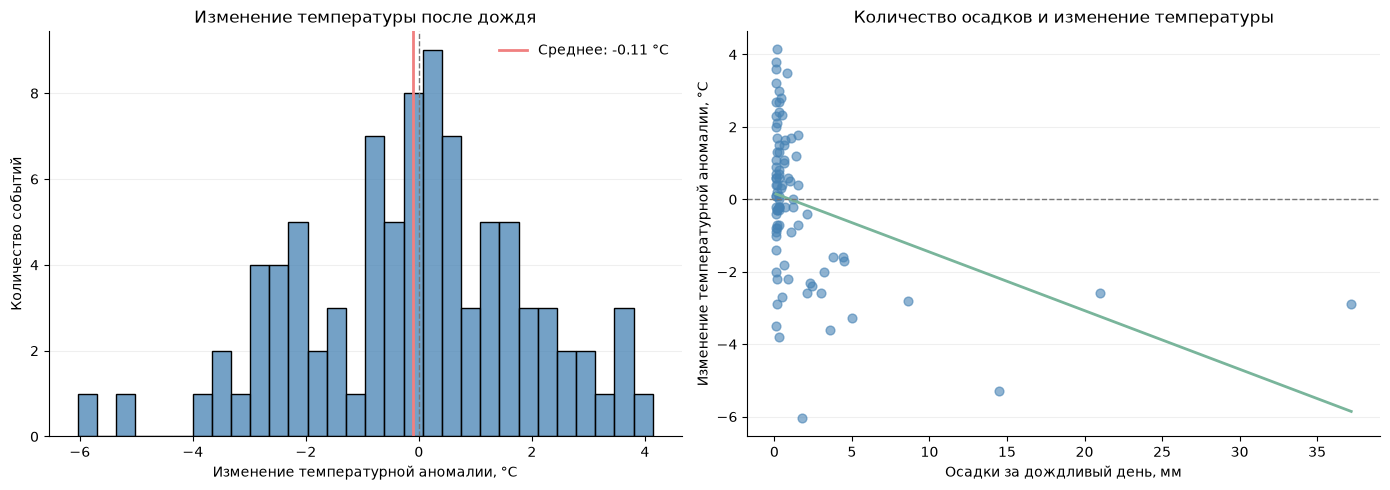

In [73]:
# Анализируем изменение температуры вокруг отдельных дождливых дней.
df_rain_change = rain_temperature_change.DataFrame()

columns = [
    'rain_mm',
    'change_on_rain_day',
    'change_after_rain',
]

df_rain_change[columns] = df_rain_change[columns].apply(
    pd.to_numeric,
    errors='coerce',
)

# Рассчитываем основные показатели.
changes = df_rain_change['change_after_rain'].dropna()

df_rain_change_stats = pd.DataFrame([{
    'Количество событий': len(changes),
    'Среднее изменение, °C': round(changes.mean(), 2),
    'Медиана, °C': round(changes.median(), 2),
    'Снижение температуры, %': round((changes < 0).mean() * 100, 2),
    'Повышение температуры, %': round((changes > 0).mean() * 100, 2),
}])

display(df_rain_change_stats.style.hide(axis='index').format(precision=2))

# Строим два графика.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Распределение изменений температурной аномалии.
sns.histplot(
    data=df_rain_change,
    x='change_after_rain',
    bins=30,
    color='#4682B4',
    ax=axes[0],
)

axes[0].axvline(
    0,
    color='#777777',
    linestyle='--',
    linewidth=1,
)

axes[0].axvline(
    changes.mean(),
    color='#F08080',
    linewidth=2,
    label=f'Среднее: {changes.mean():+.2f} °C',
)

axes[0].set(
    title='Изменение температуры после дождя',
    xlabel='Изменение температурной аномалии, °C',
    ylabel='Количество событий',
)

axes[0].legend(frameon=False)

# Проверяем связь количества осадков с изменением температуры.
sns.regplot(
    data=df_rain_change,
    x='rain_mm',
    y='change_after_rain',
    scatter_kws={
        'color': '#4682B4',
        'alpha': 0.6,
        's': 40,
    },
    line_kws={
        'color': '#79B59B',
        'linewidth': 2,
    },
    ci=None,
    ax=axes[1],
)

axes[1].axhline(
    0,
    color='#777777',
    linestyle='--',
    linewidth=1,
)

axes[1].set(
    title='Количество осадков и изменение температуры',
    xlabel='Осадки за дождливый день, мм',
    ylabel='Изменение температурной аномалии, °C',
)

for ax in axes:
    ax.grid(axis='y', alpha=0.2)
    ax.set_axisbelow(True)
    sns.despine(ax=ax)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / 'dubai_temperature_change_after_rain.png',
    dpi=300,
    bbox_inches='tight',
)

plt.show()

Анализ 89 дождливых событий не выявил устойчивого снижения температуры после осадков. В 48,31% случаев температурная аномалия уменьшалась, в 49,44% — увеличивалась. Среднее изменение составило −0,11 °C, а медиана — 0 °C.

Большинство изменений температуры сосредоточено около нуля, хотя встречаются отдельные случаи заметного похолодания и потепления. На точечном графике прослеживается отрицательный наклон линии регрессии, однако более сильные дожди представлены небольшим количеством наблюдений и могут существенно влиять на ее направление.

Таким образом, полученные данные не позволяют утверждать, что дождь в Дубае обычно приводит к похолоданию или что увеличение количества осадков обязательно сопровождается более сильным снижением температуры.

### Вывод

Наиболее заметная взаимосвязь среди рассмотренных погодных показателей обнаружена между температурой и относительной влажностью (r = −0,44). В дни, когда температура была выше среднего значения для соответствующего месяца, относительная влажность чаще оказывалась ниже. Остальные ежедневные корреляции были слабыми: например, между температурой и осадками коэффициент составил всего −0,05.

Анализ 61 изолированного дождливого дня показал, что после осадков средняя температурная аномалия снижалась, достигая −0,46 °C на вторые сутки. Однако при более широком анализе 89 дождливых событий снижение температуры наблюдалось в 48,31% случаев, повышение — в 49,44%. Среднее изменение составило −0,11 °C, а медиана — 0 °C. Таким образом, похолодание после дождя нельзя считать устойчивой закономерностью для всех событий.

Корреляция количества осадков с температурой в тот же день и в последующие пять дней также оказалась очень слабой (от −0,05 до −0,08). В целом результаты показывают, что температура, влажность и осадки взаимосвязаны, но характер этих связей различается. Особенно важно учитывать сезонность, интенсивность отдельных дождей и различия между погодными событиями.

## 7. Проверка статистических гипотез об изменении климатических характеристик

Проверим, наблюдаются ли статистически значимые тенденции изменения температуры, количества осадков и частоты дождливых дней в Дубае за период с 1 ноября 2016 года по 31 октября 2026 года.

Для анализа используем:

- **критерий Манна — Кендалла** — для проверки наличия монотонной тенденции;
- **метод Тейла — Сена** — для оценки направления и величины изменения показателя за год.

Проверяем две гипотезы:

- **H₀:** монотонная тенденция отсутствует.
- **H₁:** существует монотонная тенденция.

Уровень статистической значимости — **α = 0,05**.

Анализ проводится по десяти полным исследовательским годам (с ноября по октябрь). При интерпретации результатов учитываем небольшую длину временного ряда, возможную зависимость наблюдений между годами и ограничения исходных погодных данных.

Отсутствие статистически значимой тенденции не рассматривается как доказательство отсутствия климатических изменений.

### Проверка тенденций изменения погодных показателей

Проверим, наблюдаются ли монотонные тенденции изменения среднегодовой температуры, годового количества осадков и доли дождливых дней.

Для каждого показателя рассчитаем коэффициент Кендалла, статистическую значимость тенденции и оценку ежегодного изменения методом Тейла — Сена с 95%-м доверительным интервалом.

In [74]:
# Проверяем наличие монотонных тенденций по десяти исследовательским годам.
df_trends = df_temp_precip.copy()

indicators = {
    'Средняя температура, °C': 'temperature_mean',
    'Годовые осадки, мм': 'precipitation_total',
    'Дождливые дни, %': 'rainy_days_pct',
}

# Приводим показатели к числовому типу и сортируем по годам.
df_trends['year'] = pd.to_numeric(df_trends['year'], errors='coerce')

for column in indicators.values():
    df_trends[column] = pd.to_numeric(
        df_trends[column],
        errors='coerce',
    )

df_trends = df_trends.sort_values('year')

results = []

for name, column in indicators.items():
    data = df_trends[['year', column]].dropna()

    if len(data) < 4 or data[column].nunique() < 2:
        continue

    # Проверяем наличие монотонной тенденции.
    tau, p_value = kendalltau(
        data['year'],
        data[column],
    )

    # Оцениваем изменение показателя за один год.
    slope, intercept, lower, upper = theilslopes(
        data[column],
        data['year'],
        alpha=0.95,
    )

    results.append({
        'Показатель': name,
        'Количество лет': len(data),
        'Кендалл τ': round(tau, 4),
        'p-value': round(p_value, 4),
        'Изменение за год': round(slope, 4),
        'Нижняя граница 95% ДИ': round(lower, 4),
        'Верхняя граница 95% ДИ': round(upper, 4),
        'Значимость (α=0.05)': (
            'Да' if p_value < 0.05 else 'Нет'
        ),
    })

df_trend_tests = pd.DataFrame(results)

display(df_trend_tests.style.hide(axis='index'))

Показатель,Количество лет,Кендалл τ,p-value,Изменение за год,Нижняя граница 95% ДИ,Верхняя граница 95% ДИ,Значимость (α=0.05)
"Средняя температура, °C",10,0.584300,0.019600,0.080000,0.017100,0.148300,Да
"Годовые осадки, мм",10,0.244400,0.380700,21.850000,-8.216700,43.440000,Нет
"Дождливые дни, %",10,0.155600,0.600700,0.152200,-0.685000,0.960000,Нет


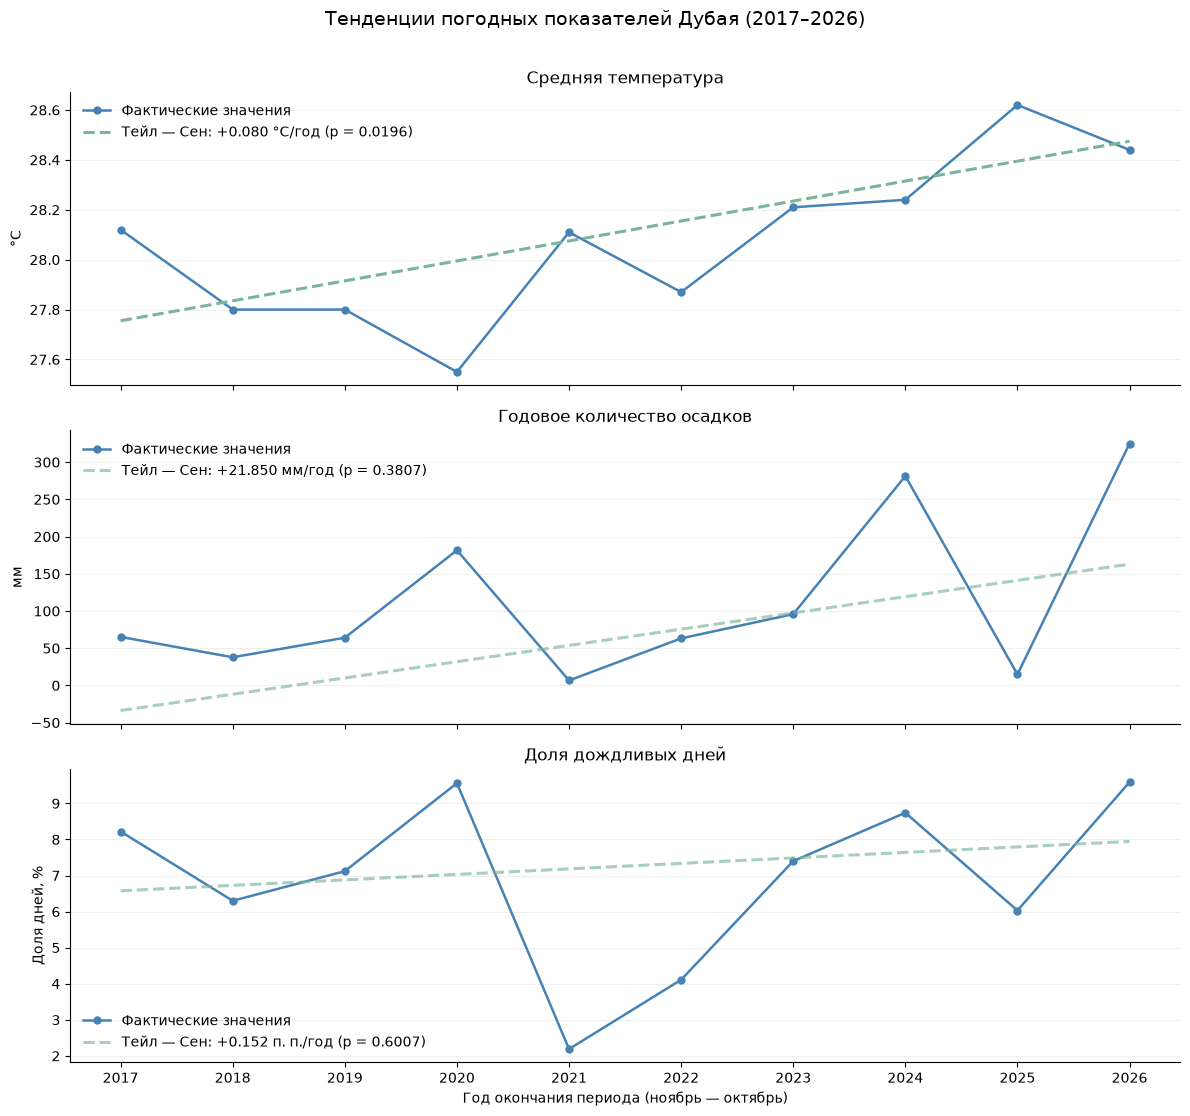

In [75]:
# Сравниваем фактические значения с оценками тенденций Тейла — Сена.
indicators = [
    ('temperature_mean', 'Средняя температура', '°C'),
    ('precipitation_total', 'Годовое количество осадков', 'мм'),
    ('rainy_days_pct', 'Доля дождливых дней', 'п. п.'),
]

fig, axes = plt.subplots(
    3, 1,
    figsize=(12, 11),
    sharex=True,
)

for ax, (column, title, unit) in zip(axes, indicators):
    data = df_trends[['year', column]].dropna().copy()
    data = data.sort_values('year')

    if len(data) < 4 or data[column].nunique() < 2:
        ax.set_title(f'{title}: недостаточно данных')
        continue

    tau, p_value = kendalltau(
        data['year'],
        data[column],
    )

    slope, intercept, lower, upper = theilslopes(
        data[column],
        data['year'],
        alpha=0.95,
    )

    trend = intercept + slope * data['year']

    significant = p_value < 0.05

    # Фактические значения показателя.
    ax.plot(
        data['year'],
        data[column],
        color='#4682B4',
        marker='o',
        markersize=5,
        linewidth=1.8,
        label='Фактические значения',
    )

    # Оценённая тенденция, а не прогноз.
    ax.plot(
        data['year'],
        trend,
        color='#79B59B',
        linestyle='--',
        linewidth=2.2,
        alpha=1 if significant else 0.65,
        label=f'Тейл — Сен: {slope:+.3f} {unit}/год (p = {p_value:.4f})',
    )

    ax.set(
        title=title,
        ylabel=unit if column != 'rainy_days_pct' else 'Доля дней, %',
    )

    ax.legend(frameon=False, loc='best')
    ax.grid(axis='y', alpha=0.2)
    ax.set_axisbelow(True)
    sns.despine(ax=ax)

axes[-1].set(
    xlabel='Год окончания периода (ноябрь — октябрь)',
    xticks=df_trends['year'].astype(int),
)

fig.suptitle(
    'Тенденции погодных показателей Дубая (2017–2026)',
    fontsize=14,
    y=1.01,
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / 'dubai_climate_trends_theil_sen.png',
    dpi=300,
    bbox_inches='tight',
)

plt.show()

### Перестановочный тест для месячных аномалий

Проверим, сохраняется ли связь между месячными аномалиями температуры и осадков при более осторожном учете временной структуры данных.

Для этого проведем 10 000 случайных перестановок годовых блоков по 12 месяцев. Такой подход сохраняет последовательность наблюдений внутри каждого исследовательского года.

Сравним фактическую корреляцию Пирсона с корреляциями, полученными при случайных перестановках. Если перестановочный p-value окажется меньше 0,05, связь будем считать статистически значимой в рамках этого теста.

In [76]:
# Проверяем связь месячных аномалий температуры и осадков,
# переставляя целые исследовательские годы, а не отдельные месяцы.
df_permutation = df_monthly_corr[
    ['month_date', 'temperature_anomaly', 'precipitation_anomaly']
].copy()

df_permutation['month_date'] = pd.to_datetime(
    df_permutation['month_date']
)

df_permutation['research_year'] = (
    df_permutation['month_date'].dt.year
    + (df_permutation['month_date'].dt.month >= 11).astype(int)
)

df_permutation['research_month'] = (
    (df_permutation['month_date'].dt.month - 11) % 12
)

# Оставляем полные исследовательские годы с 12 наблюдениями.
complete_years = df_permutation.groupby('research_year').filter(
    lambda group: (
        len(group) == 12
        and group['research_month'].nunique() == 12
    )
)

temperature = complete_years.pivot(
    index='research_year',
    columns='research_month',
    values='temperature_anomaly',
).sort_index()

precipitation = complete_years.pivot(
    index='research_year',
    columns='research_month',
    values='precipitation_anomaly',
).reindex(temperature.index)

if len(temperature) < 4:
    print('Недостаточно полных исследовательских лет для теста.')
else:
    temp_values = temperature.to_numpy(dtype=float)
    precip_values = precipitation.to_numpy(dtype=float)

    observed_r = pearsonr(
        temp_values.ravel(),
        precip_values.ravel(),
    ).statistic

    # Переставляем годовые блоки осадков относительно температуры.
    rng = np.random.default_rng(42)
    n_permutations = 10000

    permutation_r = np.empty(n_permutations)

    for i in range(n_permutations):
        shuffled = precip_values[rng.permutation(len(precip_values))]

        permutation_r[i] = pearsonr(
            temp_values.ravel(),
            shuffled.ravel(),
        ).statistic

    # Двусторонний тест учитывает связи обоих направлений.
    p_value = (
        np.count_nonzero(np.abs(permutation_r) >= abs(observed_r)) + 1
    ) / (n_permutations + 1)

    df_permutation_result = pd.DataFrame([{
        'Количество лет': len(temperature),
        'Количество месяцев': temp_values.size,
        'Корреляция Пирсона': round(observed_r, 4),
        'Перестановочный p-value': round(p_value, 4),
        'Значимость (α=0.05)': 'Да' if p_value < 0.05 else 'Нет',
    }])

    display(df_permutation_result)

,Количество лет,Количество месяцев,Корреляция Пирсона,Перестановочный p-value,Значимость (α=0.05)
0,10,120,-0.0943,0.4636,Нет


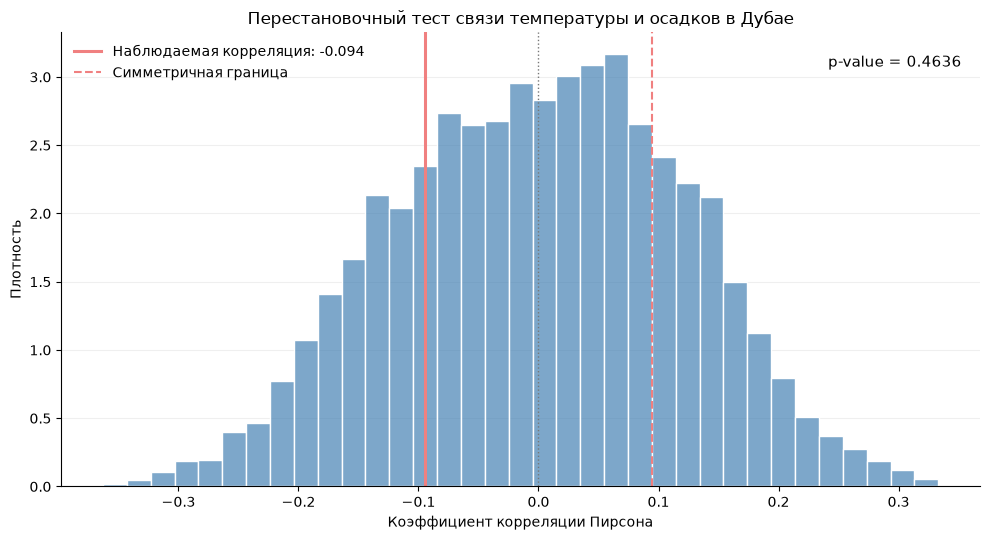

In [77]:
# Сравниваем фактическую корреляцию с результатами
# случайных перестановок годовых блоков.

fig, ax = plt.subplots(figsize=(10, 5.5))

sns.histplot(
    permutation_r,
    bins=35,
    color='#4682B4',
    alpha=0.7,
    stat='density',
    edgecolor='white',
    ax=ax,
)

# Фактическая корреляция.
ax.axvline(
    observed_r,
    color='#F08080',
    linewidth=2.2,
    label=f'Наблюдаемая корреляция: {observed_r:+.3f}',
)

# Симметричная граница для двустороннего теста.
ax.axvline(
    -observed_r,
    color='#F08080',
    linestyle='--',
    linewidth=1.5,
    label='Симметричная граница',
)

ax.axvline(
    0,
    color='#777777',
    linestyle=':',
    linewidth=1,
)

ax.set(
    title='Перестановочный тест связи температуры и осадков в Дубае',
    xlabel='Коэффициент корреляции Пирсона',
    ylabel='Плотность',
)

ax.text(
    0.98,
    0.95,
    f'p-value = {p_value:.4f}',
    transform=ax.transAxes,
    ha='right',
    va='top',
    fontsize=11,
)

ax.legend(frameon=False)
ax.grid(axis='y', alpha=0.2)
ax.set_axisbelow(True)
sns.despine(ax=ax)

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / 'dubai_temperature_precipitation_permutation_test.png',
    dpi=300,
    bbox_inches='tight',
)
plt.show()

Перестановочный тест с сохранением годовых блоков не выявил статистически значимой линейной связи между месячными аномалиями температуры и осадков (r = −0,0943; p = 0,4636).

Полученное значение p-value показывает, что корреляции не меньшей абсолютной величины достаточно часто встречаются при случайном сопоставлении годовых последовательностей. Поэтому оснований утверждать, что месяцы с повышенным количеством осадков систематически отличаются по температуре, недостаточно.

Этот результат не исключает более сложных или нелинейных зависимостей между показателями.

### Проверка различий температуры в дождливые и сухие дни

Проверим, насколько устойчиво обнаруженное ранее различие температурных аномалий между дождливыми и сухими днями.

Для этого проведем 10 000 повторных расчетов, случайным образом выбирая исследовательские годы с возможностью повторения. На основе полученных результатов определим 95%-й доверительный интервал, чтобы оценить надежность различий.

In [78]:
# Оцениваем разницу средних температурных аномалий
# между дождливыми и сухими днями с учетом годовых блоков.
df_rain_test = df_rainy_dry[
    ['weather_date', 'day_type', 'temperature_anomaly']
].copy()

df_rain_test['weather_date'] = pd.to_datetime(
    df_rain_test['weather_date']
)

df_rain_test['temperature_anomaly'] = pd.to_numeric(
    df_rain_test['temperature_anomaly'],
    errors='coerce',
)

df_rain_test = df_rain_test.dropna()

df_rain_test['research_year'] = (
    df_rain_test['weather_date'].dt.year
    + (df_rain_test['weather_date'].dt.month >= 11).astype(int)
)

# Оставляем полные исследовательские годы.
year_counts = df_rain_test.groupby('research_year')['weather_date'].nunique()

complete_years = [
    year
    for year, count in year_counts.items()
    if count == (
        pd.Timestamp(year, 11, 1)
        - pd.Timestamp(year - 1, 11, 1)
    ).days
]

df_rain_test = df_rain_test[
    df_rain_test['research_year'].isin(complete_years)
]

# Разница рассчитывается как средняя аномалия дождливых дней
# минус средняя аномалия сухих дней.
def temperature_difference(data):
    means = data.groupby('day_type')['temperature_anomaly'].mean()

    if not {'Дождливый день', 'Сухой день'}.issubset(means.index):
        return np.nan

    return means['Дождливый день'] - means['Сухой день']


observed_difference = temperature_difference(df_rain_test)

# Повторно выбираем целые исследовательские годы с возвращением.
rng = np.random.default_rng(42)
years = df_rain_test['research_year'].unique()
year_groups = {
    year: group
    for year, group in df_rain_test.groupby('research_year')
}

bootstrap_differences = []

if len(years) >= 4 and np.isfinite(observed_difference):
    for _ in range(10000):
        sampled_years = rng.choice(
            years,
            size=len(years),
            replace=True,
        )

        sample = pd.concat(
            [year_groups[year] for year in sampled_years],
            ignore_index=True,
        )

        bootstrap_differences.append(
            temperature_difference(sample)
        )

    bootstrap_differences = np.asarray(
        bootstrap_differences,
        dtype=float,
    )

    bootstrap_differences = bootstrap_differences[
        np.isfinite(bootstrap_differences)
    ]

    if len(bootstrap_differences) > 0:
        ci_lower, ci_upper = np.percentile(
            bootstrap_differences,
            [2.5, 97.5],
        )

        display(pd.DataFrame([{
            'Количество лет': len(years),
            'Дождливых дней': (
                df_rain_test['day_type'] == 'Дождливый день'
            ).sum(),
            'Разница средних, °C': round(observed_difference, 3),
            'Нижняя граница 95% ДИ': round(ci_lower, 3),
            'Верхняя граница 95% ДИ': round(ci_upper, 3),
            'ДИ включает 0': 'Да' if ci_lower <= 0 <= ci_upper else 'Нет',
        }]))
    else:
        print('Недостаточно дождливых дней в бутстрэп-выборках.')
else:
    print('Недостаточно полных исследовательских лет или данных для сравнения.')

,Количество лет,Дождливых дней,"Разница средних, °C",Нижняя граница 95% ДИ,Верхняя граница 95% ДИ,ДИ включает 0
0,10,253,0.086,-0.12,0.276,Да


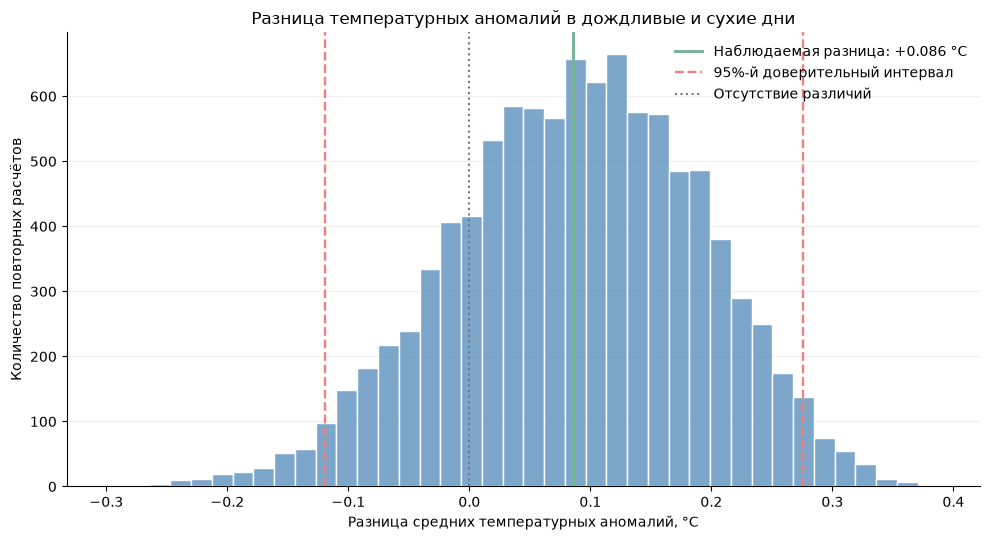

In [79]:
# Показываем распределение результатов 10 000 повторных расчетов
# и 95%-й доверительный интервал разницы температур.
if len(bootstrap_differences) > 0:
    fig, ax = plt.subplots(figsize=(10, 5.5))

    sns.histplot(
        bootstrap_differences,
        bins=40,
        color='#4682B4',
        alpha=0.7,
        edgecolor='white',
        ax=ax,
    )

    # Фактическая разница средних температурных аномалий.
    ax.axvline(
        observed_difference,
        color='#79B59B',
        linewidth=2.2,
        label=f'Наблюдаемая разница: {observed_difference:+.3f} °C',
    )

    # Границы 95%-го доверительного интервала.
    ax.axvline(
        ci_lower,
        color='#F08080',
        linestyle='--',
        linewidth=1.7,
        label='95%-й доверительный интервал',
    )

    ax.axvline(
        ci_upper,
        color='#F08080',
        linestyle='--',
        linewidth=1.7,
    )

    # Ноль означает отсутствие различий между группами.
    ax.axvline(
        0,
        color='#777777',
        linestyle=':',
        linewidth=1.5,
        label='Отсутствие различий',
    )

    ax.set(
        title='Разница температурных аномалий в дождливые и сухие дни',
        xlabel='Разница средних температурных аномалий, °C',
        ylabel='Количество повторных расчётов',
    )

    ax.legend(frameon=False)
    ax.grid(axis='y', alpha=0.2)
    ax.set_axisbelow(True)
    sns.despine(ax=ax)

    plt.tight_layout()

    plt.savefig(
        FIGURES_DIR / 'dubai_rainy_dry_temperature_bootstrap.png',
        dpi=300,
        bbox_inches='tight',
    )

    plt.show()
else:
    print('Нет результатов повторных расчетов для визуализации.')

Средняя температурная аномалия в дождливые дни оказалась на 0,086 °C выше, чем в сухие. Однако 95%-й доверительный интервал от −0,120 до +0,276 °C включает ноль. Статистически значимых различий не выявлено.

### Сводные результаты проверки гипотез

Объединим результаты проверки температурных трендов, изменений количества осадков, связи между температурой и осадками, а также различий между дождливыми и сухими днями.

Для каждой гипотезы представим оценку эффекта, доверительный интервал (если рассчитывался) и результат проверки статистической значимости.

In [80]:
# Объединяем результаты статистических проверок в одну таблицу.
summary = []

# Единицы измерения для годовых трендов.
trend_units = {
    'Температура': '°C/год',
    'Осадки': 'мм/год',
    'Дождливые дни': 'п.п./год',
}

for _, row in df_trend_tests.iterrows():
    indicator = row['Показатель']

    unit = next(
        (value for key, value in trend_units.items() if key.lower() in indicator.lower()),
        'в год',
    )

    summary.append({
        'Гипотеза': f'Тренд: {indicator}',
        'Метод': 'Анализ монотонного тренда',
        'Оценка эффекта': f'{row["Изменение за год"]:+.4f} {unit}',
        '95% ДИ': (
            f'[{row["Нижняя граница 95% ДИ"]:.4f}; '
            f'{row["Верхняя граница 95% ДИ"]:.4f}]'
        ),
        'p-value': row['p-value'],
        'Статистическая значимость': row['Значимость (α=0.05)'],
    })

# Связь месячных аномалий температуры и осадков.
if 'df_permutation_result' in globals():
    row = df_permutation_result.iloc[0]

    summary.append({
        'Гипотеза': 'Связь температуры и осадков',
        'Метод': 'Перестановочный тест по годам',
        'Оценка эффекта': f'r = {row["Корреляция Пирсона"]:+.4f}',
        '95% ДИ': '—',
        'p-value': row['Перестановочный p-value'],
        'Статистическая значимость': row['Значимость (α=0.05)'],
    })

# Различие температурных аномалий дождливых и сухих дней.
if (
    'bootstrap_differences' in globals()
    and len(bootstrap_differences) > 0
):
    summary.append({
        'Гипотеза': 'Температура в дождливые и сухие дни',
        'Метод': 'Повторные выборки по годам',
        'Оценка эффекта': f'{observed_difference:+.3f} °C',
        '95% ДИ': f'[{ci_lower:.3f}; {ci_upper:.3f}]',
        'p-value': np.nan,
        'Статистическая значимость': (
            'Нет' if ci_lower <= 0 <= ci_upper else 'Да'
        ),
    })

df_hypotheses_summary = pd.DataFrame(summary)

display(
    df_hypotheses_summary.style.format(
        {'p-value': '{:.4f}'},
        na_rep='—',
    )
)

,Гипотеза,Метод,Оценка эффекта,95% ДИ,p-value,Статистическая значимость
0,"Тренд: Средняя температура, °C",Анализ монотонного тренда,+0.0800 °C/год,[0.0171; 0.1483],0.0196,Да
1,"Тренд: Годовые осадки, мм",Анализ монотонного тренда,+21.8500 мм/год,[-8.2167; 43.4400],0.3807,Нет
2,"Тренд: Дождливые дни, %",Анализ монотонного тренда,+0.1522 п.п./год,[-0.6850; 0.9600],0.6007,Нет
3,Связь температуры и осадков,Перестановочный тест по годам,r = -0.0943,—,0.4636,Нет
4,Температура в дождливые и сухие дни,Повторные выборки по годам,+0.086 °C,[-0.120; 0.276],—,Нет


### Вывод

Статистический анализ выявил значимый положительный тренд среднегодовой температуры в Дубае за исследуемый период 2016–2026 годов. Средняя скорость повышения составила 0,08 °C в год (p = 0,0196). При этом статистически значимых тенденций изменения годового количества осадков и доли дождливых дней не обнаружено.

Проверка связи между месячными аномалиями температуры и осадков также не выявила значимой линейной зависимости (r = −0,0943; p = 0,4636). Разница средних температурных аномалий между дождливыми и сухими днями составила всего 0,086 °C, а доверительный интервал включал ноль.

Таким образом, из рассмотренных гипотез статистическое подтверждение получил только тренд повышения температуры. Остальные показатели характеризуются значительной изменчивостью, но убедительных свидетельств направленных изменений или устойчивой линейной связи в рамках выбранных проверок не получено. Результаты следует интерпретировать с учетом относительно короткого десятилетнего периода наблюдений.

## 8. Сопоставление климатических тенденций с программами модификации погоды в ОАЭ

Цель раздела — сопоставить выявленные климатические тенденции в Дубае с доступной информацией о развитии программ засева облаков в ОАЭ, уделив особое внимание динамике осадков.

Основные задачи:

1. Изучить историю и основные направления развития программ засева облаков в ОАЭ.
2. Оценить доступность и полноту опубликованных сведений о количестве и периодах проведения операций.
3. При наличии сопоставимых данных проанализировать связь между годовым количеством операций засева облаков в ОАЭ и количеством осадков в Дубае.
4. Определить ограничения анализа и возможности интерпретации полученных результатов.

Сопоставление носит наблюдательный характер. Даже при обнаружении статистической связи между количеством операций и осадками она не может рассматриваться как доказательство эффективности засева облаков.

Для оценки непосредственного влияния таких операций необходимы более подробные данные об их времени, месте проведения и метеорологических условиях, а также соответствующая методика оценки причинно-следственных связей.

### 8.1. Хронология развития программ засева облаков в ОАЭ

Работы по увеличению количества осадков в ОАЭ начались задолго до исследуемого периода — еще в 1990-х годах.

В 2015 году была создана исследовательская программа UAE Research Program for Rain Enhancement Science (UAEREP), находящаяся под управлением Национального центра метеорологии ОАЭ (National Center of Meteorology, NCM).

В 2016–2025 годах программа развивалась в рамках нескольких циклов финансирования научных проектов. Основные направления исследований включали совершенствование технологий засева облаков, изучение процессов формирования осадков, разработку новых материалов, использование дистанционного зондирования и математического моделирования.

Развитие программы свидетельствует о расширении научных и технологических возможностей ОАЭ в области увеличения осадков. Однако сведения об исследовательских проектах не позволяют определить количество фактически проведенных операций засева облаков, их географическое распределение и возможное влияние на осадки в Дубае.

**Источники:**

- [UAEREP — About the Program](https://www.uaerep.ae/section/the-program/about-the-program?locale=en&nID=2094)
- [UAEREP — Research Projects](https://www.uaerep.ae/research-projects?locale=en)
- [WMO — A Decade Revolutionizing Rain Enhancement Science and Applications](https://wmo.int/resources/meteoworld/meteoworld-june-2025/decade-revolutionizing-rain-enhancement-science-and-applications)

### 8.2. Сбор и подготовка статистики операций засева облаков

Для количественного анализа используются опубликованные сведения о количестве операций засева облаков в ОАЭ за 2016–2026 годы.

Сбор данных выполняется отдельным Python-скриптом с использованием библиотек requests и BeautifulSoup. Из открытых публикаций извлекаются год, количество операций, единица учета, отчетный период и ссылка на источник.

Поскольку в публикациях используются различные обозначения — operations, missions и flights, — исходные термины сохраняются для проверки сопоставимости показателей.

Полученные сведения проверяются на полноту отчетного периода, наличие противоречий и корректность извлеченных значений. Неполные и неоднозначные данные отделяются от подтвержденных годовых показателей.

Результаты сбора сохраняются в CSV вместе с фрагментами исходных публикаций и ссылками на источники. Для дальнейшего анализа используются только проверенные и сопоставимые данные.


### 8.3. Сопоставление операций засева облаков и осадков в Дубае

Для сопоставления используются два набора данных:

- годовые суммы осадков в Дубае по метеорологическим наблюдениям;
- опубликованные сведения о количестве операций засева облаков на территории ОАЭ.

Данные объединяются по календарным годам. В анализ включаются только годы с полными метеорологическими наблюдениями и проверенными, сопоставимыми показателями операций.

При достаточном количестве наблюдений связь между показателями оценивается с помощью коэффициентов корреляции Пирсона и Спирмена. Результаты представляются в виде диаграммы рассеяния и сводной таблицы.

Анализ носит наблюдательный характер: статистика операций по всей территории ОАЭ не позволяет установить их непосредственное влияние на количество осадков в Дубае.

### Загрузка статистики операций засева облаков

Запустим внешний Python-модуль для сбора опубликованных сведений об операциях засева облаков в ОАЭ за 2016–2026 годы.

Полученные данные загрузим в DataFrame и проверим полноту, единицы учета и наличие неоднозначных значений перед дальнейшим анализом.

In [81]:
import sys
from pathlib import Path

# Добавляем корень проекта в пути импорта.
project_root = Path.cwd().parent.resolve()

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from scripts.cloud_seeding_parser import build_dataset, SOURCES

# Запускаем сбор данных.
df_seeding, df_candidates, df_errors = build_dataset(SOURCES)

display(df_seeding)

,year,operations,metric_type,period_type,period_end,verification_status,source_url
0,2016,177,missions,full_year,2016-12-31,auto_extracted,https://www.thenationalnews.com/uae/environmen...
1,2017,242,missions,full_year,2017-12-31,auto_extracted,https://www.thenationalnews.com/uae/environmen...
2,2018,184,operations,full_year,2018-12-31,auto_extracted,https://gulfnews.com/uae/environment/revealed-...
3,2019,247,operations,full_year,2019-12-31,auto_extracted,https://www.thenationalnews.com/uae/environmen...
4,2020,399,operations,full_year,2020-12-31,auto_extracted,https://www.gulftoday.ae/News/2022/01/01/UAE-c...
5,2021,299,operations,full_year,2021-12-31,auto_extracted,https://www.gulftoday.ae/News/2022/01/01/UAE-c...
6,2022,311,missions,full_year,2022-12-31,auto_extracted,https://www.thenationalnews.com/uae/2023/01/24...
7,2023,<NA>,<NA>,<NA>,<NA>,missing,<NA>
8,2024,388,operations,full_year,2024-12-31,auto_extracted,https://www.khaleejtimes.com/uae/weather/uae-w...
9,2025,172,flights,partial_year,2025-08-10,auto_extracted,https://gulfnews.com/uae/weather/uae-conducts-...


Извлечено кандидатов: 17
Ошибок загрузки: 0
Годов без однозначного результата: 1


,year,operations,metric_type,period_start,period_end,period_type,geography,source,source_url,source_context,verification_status
0,2016,177,missions,2016-01-01,2016-12-31,full_year,UAE,www.thenationalnews.com,https://www.thenationalnews.com/uae/environmen...,"In 2017, 242 cloud seeding missions were carri...",auto_extracted
1,2017,242,missions,2017-01-01,2017-12-31,full_year,UAE,www.thenationalnews.com,https://www.thenationalnews.com/uae/environmen...,"In 2017, 242 cloud seeding missions were carri...",auto_extracted
2,2018,184,operations,2018-01-01,2018-12-31,full_year,UAE,gulfnews.com,https://gulfnews.com/uae/environment/revealed-...,"According to the NCM, the UAE saw just 46.5 mi...",auto_extracted
3,2019,247,operations,2019-01-01,2019-12-31,full_year,UAE,www.thenationalnews.com,https://www.thenationalnews.com/uae/environmen...,A total of 247 cloud seeding operations were c...,auto_extracted
4,2020,399,operations,2020-01-01,2020-12-31,full_year,UAE,www.gulftoday.ae,https://www.gulftoday.ae/News/2022/01/01/UAE-c...,"Emadeddin Khlalil, Staff Reporter The National...",auto_extracted
5,2021,299,operations,2021-01-01,2021-12-31,full_year,UAE,www.gulftoday.ae,https://www.gulftoday.ae/News/2022/01/01/UAE-c...,UAE carried out 299 cloud seeding operations i...,auto_extracted
6,2022,311,missions,2022-01-01,2022-12-31,full_year,UAE,www.thenationalnews.com,https://www.thenationalnews.com/uae/2023/01/24...,The UAE conducted 311 cloud-seeding missions i...,auto_extracted
7,2023,<NA>,<NA>,<NA>,<NA>,<NA>,UAE,<NA>,<NA>,<NA>,missing
8,2024,388,operations,2024-01-01,2024-12-31,full_year,UAE,www.khaleejtimes.com,https://www.khaleejtimes.com/uae/weather/uae-w...,"In 2024, the country carried out 388 cloud see...",auto_extracted
9,2025,172,flights,2025-01-01,2025-08-10,partial_year,UAE,gulfnews.com,https://gulfnews.com/uae/weather/uae-conducts-...,UAE conducts 172 cloud-seeding flights in 2025...,auto_extracted


In [82]:
# Проверяем исходные публикации и извлеченные значения.
df_seeding_check = df_seeding[
    [
        'year',
        'operations',
        'metric_type',
        'period_type',
        'source_context',
        'source_url',
    ]
].copy()

display(
    df_seeding_check.style.set_properties(
        subset=['source_context'],
        **{'text-align': 'left'},
    )
)

,year,operations,metric_type,period_type,source_context,source_url
0,2016,177,missions,full_year,"In 2017, 242 cloud seeding missions were carried out by the UAE, with 177 carried out in 2016.",https://www.thenationalnews.com/uae/environment/seeding-flights-in-uae-boosting-rainfall-from-clouds-by-a-third-1.694589
1,2017,242,missions,full_year,"In 2017, 242 cloud seeding missions were carried out by the UAE, with 177 carried out in 2016.",https://www.thenationalnews.com/uae/environment/seeding-flights-in-uae-boosting-rainfall-from-clouds-by-a-third-1.694589
2,2018,184,operations,full_year,"According to the NCM, the UAE saw just 46.5 millimetres of rainfall in 2018, even though 184 cloud seeding operations were carried out.",https://gulfnews.com/uae/environment/revealed-how-much-rain-fell-due-to-cloud-seeding-in-uae-1.69106071
3,2019,247,operations,full_year,A total of 247 cloud seeding operations were carried out by NCM's four dedicated airplanes in 2019.,https://www.thenationalnews.com/uae/environment/uae-aims-to-boost-cloud-seeding-via-artificial-clouds-says-top-meteorologist-1.966292
4,2020,399,operations,full_year,"Emadeddin Khlalil, Staff Reporter The National Center of Meteorology (NCM) revealed that it had carried out 299 cloud seeding operations during 2021, compared to 399 in 2020, at a rate of 2-3 hours per operation, covering most of the country’s regions.",https://www.gulftoday.ae/News/2022/01/01/UAE-carried-out-299-cloud-seeding-operations-in-2021
5,2021,299,operations,full_year,UAE carried out 299 cloud seeding operations in 2021,https://www.gulftoday.ae/News/2022/01/01/UAE-carried-out-299-cloud-seeding-operations-in-2021
6,2022,311,missions,full_year,"The UAE conducted 311 cloud-seeding missions in 2022, clocking up close to 1,000 flying hours.",https://www.thenationalnews.com/uae/2023/01/24/uae-doubles-number-of-cloud-seeding-flights-in-six-years-in-bid-to-boost-rainfall/
7,2023,,,,,
8,2024,388,operations,full_year,"In 2024, the country carried out 388 cloud seeding operations, a record number that could potentially be matched again this year if local cloud activity picks up, particularly during the summer and winter seeding seasons.",https://www.khaleejtimes.com/uae/weather/uae-why-less-rainfall-this-year
9,2025,172,flights,partial_year,UAE conducts 172 cloud-seeding flights in 2025 so far,https://gulfnews.com/uae/weather/uae-conducts-172-cloud-seeding-flights-in-2025-so-far-1.500228558


In [83]:
# Проверяем полноту наблюдений осадков по календарным годам.
df_precip_year_complete = (
    df_precip_month.groupby('year', as_index=False)
    .agg(
        observed_days=('observed_days', 'sum'),
        expected_days=('expected_days', 'sum'),
        observed_months=('month', 'nunique'),
    )
)

df_precip_year_complete['precipitation_complete'] = (
    df_precip_year_complete['observed_months'].eq(12)
    & df_precip_year_complete['observed_days'].eq(
        df_precip_year_complete['expected_days']
    )
)

# Объединяем годовые осадки Дубая, полноту наблюдений
# и статистику операций засева облаков в ОАЭ.
df_seeding_comparison = (
    df_corr[['year', 'precipitation_total']]
    .merge(
        df_precip_year_complete[['year', 'precipitation_complete']],
        on='year',
        how='inner',
    )
    .merge(
        df_seeding[
            [
                'year',
                'operations',
                'metric_type',
                'period_type',
                'verification_status',
            ]
        ],
        on='year',
        how='inner',
    )
)

# Оставляем полные календарные годы с доступной годовой
# статистикой операций засева облаков.
# Термины missions, operations и flights считаем условно сопоставимыми.
df_seeding_comparison = df_seeding_comparison[
    df_seeding_comparison['year'].between(2017, 2025)
    & df_seeding_comparison['precipitation_complete']
    & df_seeding_comparison['period_type'].eq('full_year')
    & df_seeding_comparison['verification_status'].eq('auto_extracted')
    & df_seeding_comparison['operations'].notna()
].copy()

display(df_seeding_comparison.sort_values('year'))

print('Количество лет для сравнения:', len(df_seeding_comparison))

,year,precipitation_total,precipitation_complete,operations,metric_type,period_type,verification_status
0,2017,65.2,True,242,missions,full_year,auto_extracted
1,2018,37.8,True,184,operations,full_year,auto_extracted
2,2019,64.1,True,247,operations,full_year,auto_extracted
3,2020,181.6,True,399,operations,full_year,auto_extracted
4,2021,6.7,True,299,operations,full_year,auto_extracted
5,2022,63.2,True,311,missions,full_year,auto_extracted
7,2024,281.3,True,388,operations,full_year,auto_extracted


Количество лет для сравнения: 7


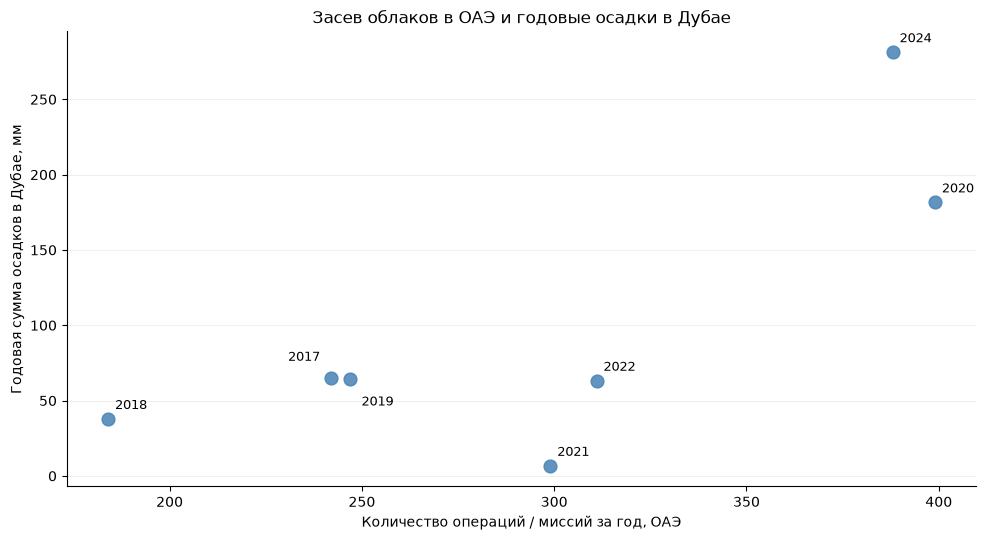

,Количество лет,Пирсон r,Пирсон p-value,Спирмен ρ,Спирмен p-value
0,7,0.764,0.0454,0.536,0.2152


In [84]:
# Приводим показатели к числовому типу.
# Это необходимо, поскольку после объединения таблиц
# столбец operations мог сохранить тип object.
data = df_seeding_comparison.copy()

for column in ['operations', 'precipitation_total']:
    data[column] = pd.to_numeric(
        data[column],
        errors='coerce',
    ).astype('float64')

# Удаляем строки, в которых нет одного из сравниваемых показателей.
data = data.dropna(
    subset=['operations', 'precipitation_total']
)

n = len(data)

if n >= 3:
    # Пирсон — линейная связь, Спирмен — монотонная связь.
    pearson_r, pearson_p = pearsonr(
        data['operations'].to_numpy(dtype=float),
        data['precipitation_total'].to_numpy(dtype=float),
    )

    spearman_r, spearman_p = spearmanr(
        data['operations'].to_numpy(dtype=float),
        data['precipitation_total'].to_numpy(dtype=float),
    )

    # Строим диаграмму рассеяния с подписями годов.
    fig, ax = plt.subplots(figsize=(10, 5.5))

    ax.scatter(
        data['operations'],
        data['precipitation_total'],
        color='#4682B4',
        s=85,
        alpha=0.85,
    )

    # Разносим подписи близко расположенных точек.
    label_offsets = {
        2017: (-8, 10),
        2019: (8, -12),
    }

    for _, row in data.iterrows():
        year = int(row['year'])
        offset = label_offsets.get(year, (5, 5))

        ax.annotate(
            str(year),
            (row['operations'], row['precipitation_total']),
            xytext=offset,
            textcoords='offset points',
            fontsize=9,
            ha='right' if offset[0] < 0 else 'left',
            va='top' if offset[1] < 0 else 'bottom',
        )

    ax.set(
        title='Засев облаков в ОАЭ и годовые осадки в Дубае',
        xlabel='Количество операций / миссий за год, ОАЭ',
        ylabel='Годовая сумма осадков в Дубае, мм',
    )

    ax.grid(axis='y', alpha=0.2)
    ax.set_axisbelow(True)
    sns.despine(ax=ax)

    plt.tight_layout()

    plt.savefig(
        FIGURES_DIR / 'cloud_seeding_precipitation_correlation.png',
        dpi=300,
        bbox_inches='tight',
    )

    plt.show()

    # Сохраняем результаты статистических тестов.
    df_seeding_correlation = pd.DataFrame([{
        'Количество лет': n,
        'Пирсон r': round(float(pearson_r), 3),
        'Пирсон p-value': round(float(pearson_p), 4),
        'Спирмен ρ': round(float(spearman_r), 3),
        'Спирмен p-value': round(float(spearman_p), 4),
    }])

    display(df_seeding_correlation)

else:
    print('Недостаточно полных лет для расчета корреляции.')

### Вывод

Для сопоставления количества операций засева облаков в ОАЭ и годовой суммы осадков в Дубае использованы данные за **7 календарных лет (2017–2022 и 2024)**. Из девяти полных календарных лет исключены 2023 год из-за отсутствия годовой статистики операций и 2025 год, для которого доступны только промежуточные сведения.

Корреляционный анализ показал **положительную линейную связь** между количеством операций засева облаков и годовыми осадками в Дубае (коэффициент Пирсона r = 0.764, p = 0.0454). При этом коэффициент Спирмена (ρ = 0.536, p = 0.2152) не подтвердил статистически значимой монотонной связи.

Полученные результаты требуют осторожной интерпретации. Выборка включает всего семь наблюдений, а на коэффициенты корреляции могли существенно повлиять отдельные годы с большим количеством осадков, особенно 2020 и 2024. Кроме того, статистика операций охватывает всю территорию ОАЭ, тогда как осадки анализируются только для Дубая. Показатели *missions*, *operations* и *flights* приняты условно сопоставимыми, хотя методика их учета может различаться.

**Таким образом, обнаруженная положительная корреляция не доказывает влияние засева облаков на количество осадков.** Число операций само по себе зависит от погодных условий и наличия подходящих облаков. Для оценки эффективности программ засева необходимы более подробные сведения о времени и месте проведения операций, характеристиках облаков и количестве естественных осадков в сопоставимых условиях.

## 9. Итоговое обобщение результатов исследования

### 9.1. Основные характеристики климата Дубая

В исследовании проанализированы метеорологические данные Дубая за период с 1 ноября 2016 года по 31 октября 2026 года, охватывающий десять полных исследовательских лет.

Анализ подтвердил выраженную сезонность климата Дубая. Температурный режим характеризуется продолжительным жарким периодом и относительно мягкой зимой. Осадки распределяются неравномерно, преимущественно приходятся на прохладную часть года и существенно различаются по объему между отдельными годами.

Влажность воздуха и скорость ветра также демонстрируют сезонную изменчивость, отражая особенности местного климатического режима.

### 9.2. Температурные аномалии и экстремальные явления

Анализ межгодовой динамики выявил **статистически значимую тенденцию повышения среднегодовой температуры**. Коэффициент Кендалла составил τ = 0.584 (p = 0.0196), а оценка тренда Тейла — Сена — приблизительно +0.08 °C в год.

Полученные результаты свидетельствуют о повышении температурного фона в течение исследуемого десятилетия. При этом отдельные температурные аномалии и экстремально жаркие периоды необходимо рассматривать с учетом естественной межгодовой изменчивости.

Для годовой суммы осадков и доли дождливых дней статистически значимых долгосрочных тенденций не выявлено. Осадки характеризуются высокой изменчивостью, а отдельные экстремальные дождевые события могут существенно влиять на годовые показатели.

### 9.3. Взаимосвязи метеорологических показателей

Корреляционный анализ позволил оценить взаимосвязи между температурой, осадками и другими метеорологическими характеристиками.

При сопоставлении месячных показателей температуры и осадков коэффициент Пирсона составил r = −0.094. Проверка статистической значимости с учетом группировки наблюдений по годам не подтвердила наличие устойчивой линейной связи (p = 0.4636).

Дополнительно исследована разница температурных аномалий между дождливыми и сухими днями. Наблюдаемая разница составила +0.086 °C, однако 95%-й доверительный интервал от −0.120 до +0.276 °C включает ноль.

Таким образом, **статистически значимых различий температурных аномалий между дождливыми и сухими днями не обнаружено**. Полученные результаты показывают важность учета сезонности, межгодовой изменчивости и неопределенности статистических оценок.

### 9.4. Программы засева облаков и наблюдаемые осадки

Дополнительный анализ был посвящен сопоставлению количества операций засева облаков в ОАЭ с годовыми суммами осадков в Дубае.

Для сравнения использованы семь календарных лет: 2017–2022 и 2024. Коэффициент Пирсона составил r = 0.764 (p = 0.0454), что указывает на положительную линейную корреляцию. Однако коэффициент Спирмена ρ = 0.536 (p = 0.2152) не подтвердил статистически значимой монотонной связи.

Результаты ограничены небольшим количеством наблюдений, различиями в терминологии учета операций и несовпадением пространственного охвата показ